In [ ]:
# ===== Data location =====================================================
# Set DATA_DIR to the folder that holds the dataset file(s).
#   - This project needs: AI_nano.xlsx
#   - The endpoint notebook also needs: Literature_transcriptomics_review.xlsx
# On Google Colab with the datasets in Drive, the default below works
# (run the drive.mount cell that follows). For a local run, set e.g.
#   DATA_DIR = './data'   and skip the drive.mount cell.
import os
DATA_DIR = '/content/drive/MyDrive/datasets'


In [ ]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import re
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import RFE
from sklearn.linear_model import RidgeCV, LassoCV, Ridge, Lasso
#from sklearn.metrics import plot_confusion_matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import (precision_recall_curve,PrecisionRecallDisplay)
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score
from sklearn.metrics import mean_absolute_error, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn import tree
from sklearn import metrics
pd.options.display.max_columns = None
pd.options.display.max_rows = None

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import re
import seaborn as sns
import math
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

In [ ]:
# Libraries
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from sklearn.neural_network import MLPRegressor

import warnings
warnings.filterwarnings('ignore')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Import the data (CSV file)

In [ ]:
df = pd.read_excel(f"{DATA_DIR}/AI_nano.xlsx")
#df = pd.read_csv('/content/drive/MyDrive/datasets/data.csv')                       ############################
df

,ID,Type,TS,HD,Zeta,Charge,Shape,TM,CT,TSz,TW,Dose,BW,DE24,DE168,Demax,KTRESrelease,KTRESmax,KTRES50,KTRESn,QTC,VTC,BVT,PT,PATC
0,1,Inorganic,Active,NaN,18.00,0.0,Rod,Xenograft Heterotopic,cervix,0.100,0.1200,2.000000e+01,20.0,1.690,2.060,2.360,0.0010,0.0550,0.50000,0.50,0.010,0.00600,0.02,0.265000,0.010000
1,2,Inorganic,Passive,NaN,0.00,2.0,Rod,Allograft Heterotopic,colon,NaN,0.1423,1.205000e+01,20.0,0.990,0.790,2.390,0.0550,0.4000,12.00000,5.00,0.010,0.00710,0.02,0.100000,0.100000
2,3,Inorganic,Active,42.00,5.00,0.0,Spherical,Xenograft Heterotopic,brain,NaN,0.9167,1.000000e+00,20.0,3.270,2.830,4.180,0.0070,0.0450,2.00000,5.00,0.010,0.04580,0.02,0.070000,0.070000
3,4,Inorganic,Passive,38.30,5.00,0.0,Spherical,Xenograft Heterotopic,brain,NaN,0.9167,1.000000e+00,20.0,6.640,2.990,7.440,0.0001,0.0060,2.00000,5.00,0.010,0.04580,0.02,0.200000,0.100000
4,5,Inorganic,Active,68.40,9.30,0.0,Other,Xenograft Heterotopic,breast,0.175,0.2100,4.800000e+00,20.0,0.420,1.670,1.770,0.0010,24.0000,108.00000,5.00,0.010,0.01100,0.02,0.055000,0.005000
5,6,Inorganic,Passive,166.00,6.00,0.0,Spherical,Xenograft Orthotopic,skin,1.100,1.3200,2.706000e+01,21.0,5.630,4.250,6.410,0.0010,0.2000,72.00000,3.00,0.010,0.06300,0.02,0.132000,0.017000
6,7,Inorganic,Active,175.60,5.00,0.0,Spherical,Xenograft Orthotopic,skin,1.100,1.3200,2.706000e+01,21.0,9.610,2.980,11.150,1.0500,5.0000,3.00000,2.00,0.010,0.06300,0.02,0.050000,0.100000
7,8,Inorganic,Passive,104.20,10.00,0.0,Spherical,Xenograft Orthotopic,skin,1.100,1.3200,1.624000e+01,21.0,11.980,4.530,14.770,0.1400,1.3000,0.60000,1.50,0.010,0.06300,0.02,0.041000,0.090000
8,9,Inorganic,Passive,64.20,15.00,0.0,Spherical,Xenograft Orthotopic,skin,1.100,1.3200,8.120000e+00,21.0,14.710,5.470,17.520,0.1400,1.4000,0.10000,2.00,0.010,0.06300,0.02,0.046000,0.090000
9,10,Inorganic,Passive,46.30,6.70,0.0,Spherical,Xenograft Orthotopic,skin,1.100,1.3200,4.060000e+00,21.0,18.110,7.790,23.400,0.1150,1.7500,0.80000,1.50,0.010,0.06300,0.02,0.048000,0.090000


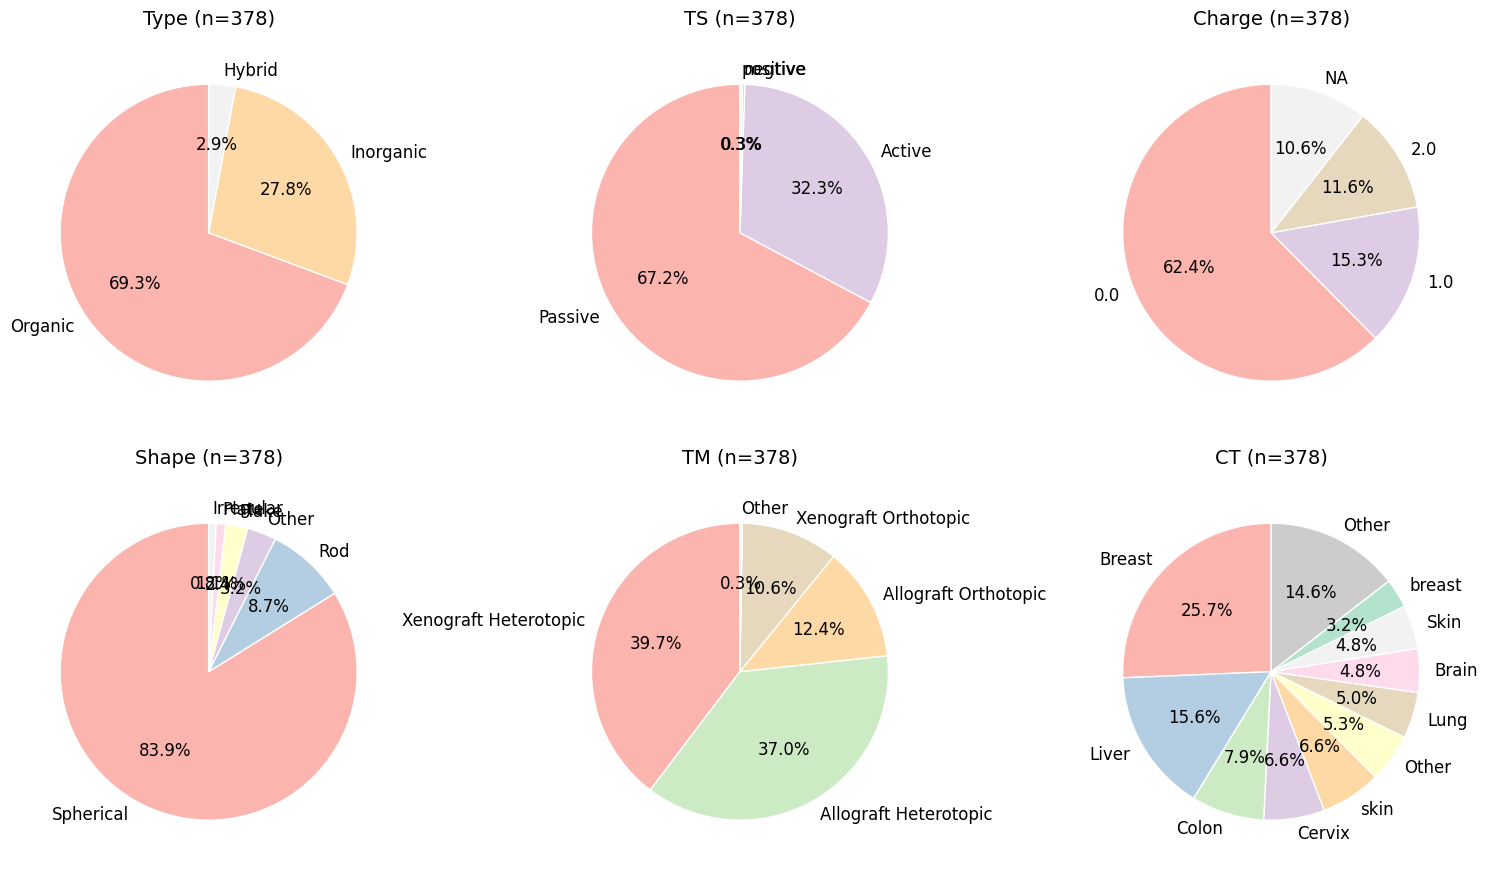

In [ ]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- choose which columns to plot as categorical pies ----
candidate_cols = ["Type", "TS", "HD", "Zeta", "Charge", "Shape", "TM", "CT", "TSz", "TW", "Dose"]
cat_cols = [c for c in candidate_cols if c in df.columns]

# Heuristic: keep categorical-looking columns (object dtype or low cardinality)
cat_cols = [c for c in cat_cols if (df[c].dtype == "object" or df[c].nunique(dropna=True) <= 20)]
if not cat_cols:
    raise ValueError("No categorical-looking columns found to plot.")

def topN_with_other(s, topn=10, other_label="Other"):
    vc = s.value_counts(dropna=False)
    if len(vc) <= topn:
        return vc
    head = vc.iloc[:topn]
    tail_sum = vc.iloc[topn:].sum()
    return pd.concat([head, pd.Series({other_label: tail_sum})])

# Pastel color helper
def pastel_colors(n):
    cmaps = [plt.cm.Pastel1, plt.cm.Pastel2]
    cols = []
    i = 0
    while len(cols) < n:
        cmap = cmaps[i % len(cmaps)]
        m = min(n - len(cols), cmap.N)  # take up to cmap length
        cols.extend(list(cmap(np.linspace(0, 1, m))))
        i += 1
    return cols[:n]

# ---- build subplots grid ----
n = len(cat_cols)
ncols = 3
nrows = math.ceil(n / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 4.5*nrows))
axes = axes.flatten() if n > 1 else [axes]

for ax, col in zip(axes, cat_cols):
    cats = (df[col].astype("string").str.strip().fillna("NA").replace("", "NA"))
    counts = topN_with_other(cats, topn=10, other_label="Other")
    labels = [str(x) for x in counts.index]
    colors = pastel_colors(len(counts))

    ax.pie(
        counts.values,
        labels=labels,
        colors=colors,
        autopct="%1.1f%%",
        startangle=90,
        wedgeprops={"edgecolor":"white", "linewidth":1},
        textprops={"fontsize":12}
    )
    ax.set_title(f"{col} (n={len(cats)})", fontsize=14)
    ax.axis("equal")

# hide unused axes
for j in range(len(cat_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


Saved: categorical_distribution_pies_publication_large.png
Saved: categorical_distribution_pies_publication_large.pdf


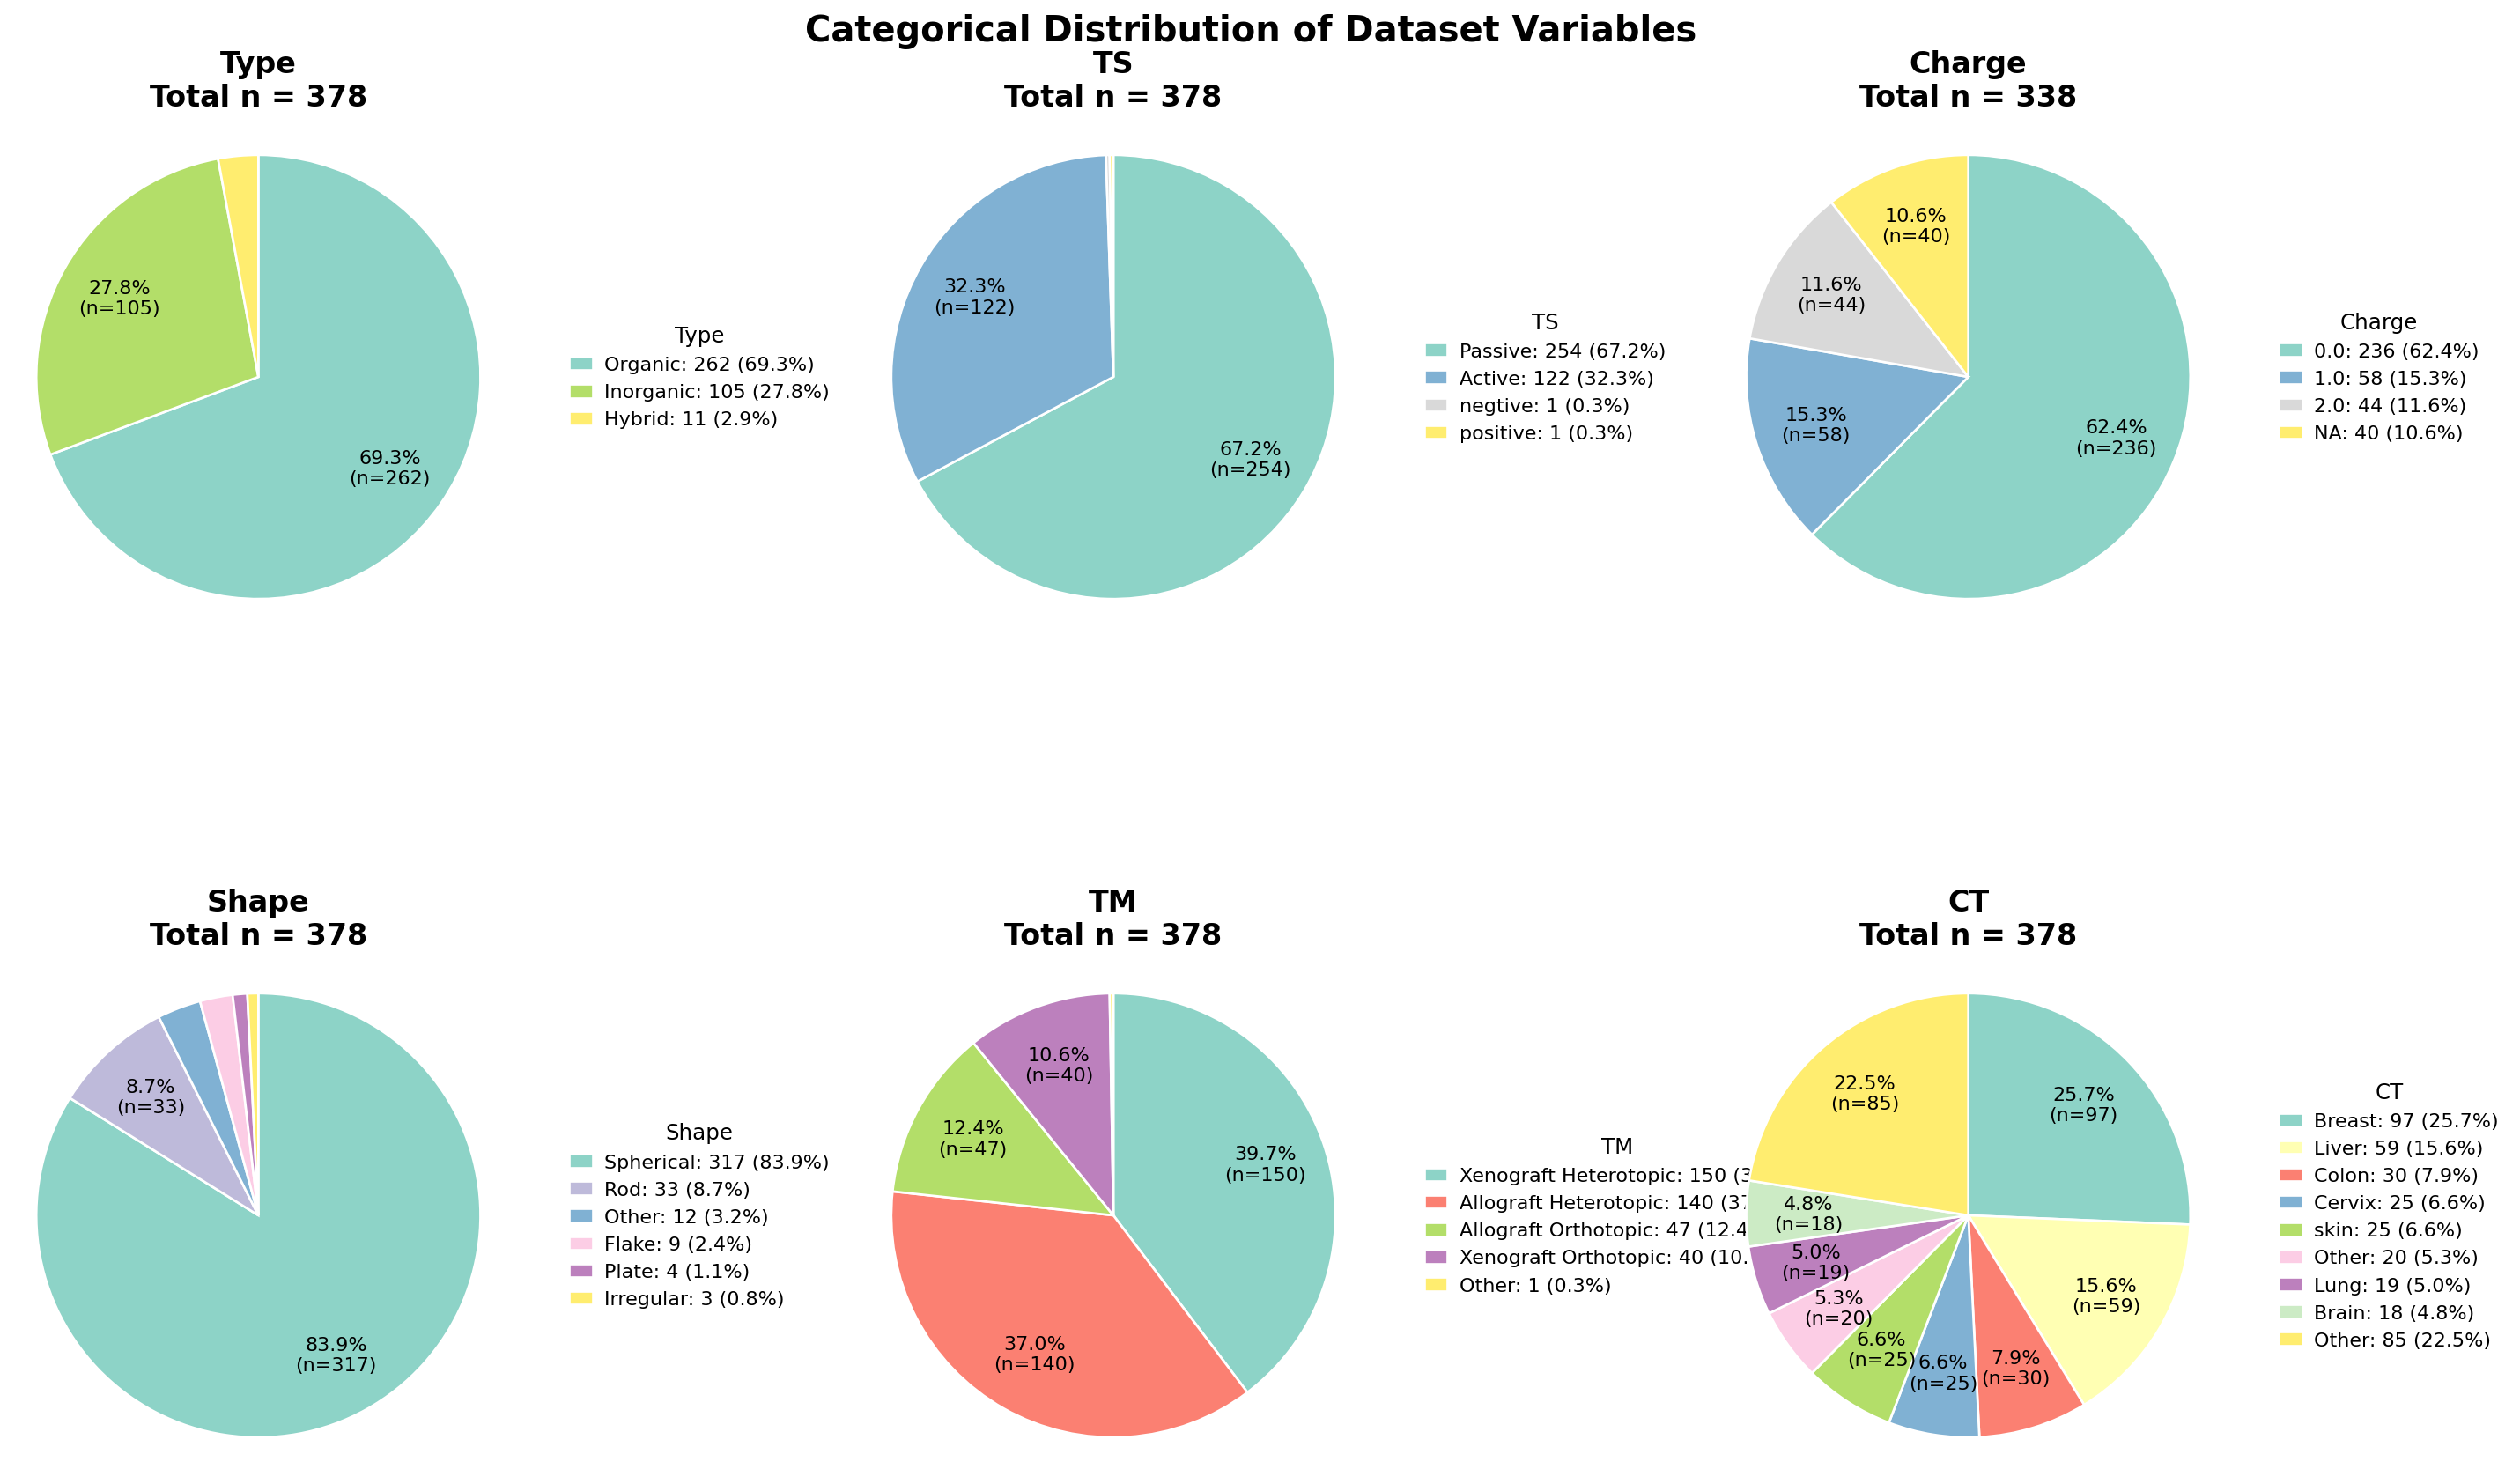

In [ ]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================================================
# SETTINGS
# =========================================================
candidate_cols = ["Type", "TS", "HD", "Zeta", "Charge", "Shape", "TM", "CT", "TSz", "TW", "Dose"]

TOP_N = 8
N_COLS = 3
SAVE_FIG = True
OUT_PNG = "categorical_distribution_pies_publication_large.png"
OUT_PDF = "categorical_distribution_pies_publication_large.pdf"

# =========================================================
# SELECT CATEGORICAL COLUMNS
# =========================================================
cat_cols = [c for c in candidate_cols if c in df.columns]

cat_cols = [
    c for c in cat_cols
    if (
        df[c].dtype == "object"
        or df[c].dtype.name == "category"
        or df[c].nunique(dropna=True) <= 20
    )
]

if not cat_cols:
    raise ValueError("No categorical-looking columns found to plot.")

# =========================================================
# HELPER FUNCTIONS
# =========================================================
def topN_with_other(s, topn=8, other_label="Other"):
    s = (
        s.astype("string")
        .str.strip()
        .fillna("NA")
        .replace("", "NA")
    )
    vc = s.value_counts(dropna=False)

    if len(vc) <= topn:
        return vc

    head = vc.iloc[:topn]
    tail_sum = vc.iloc[topn:].sum()
    return pd.concat([head, pd.Series({other_label: tail_sum})])


def make_autopct(values, min_pct_label=3):
    total = np.sum(values)

    def autopct(pct):
        if pct < min_pct_label:
            return ""
        count = int(round(pct * total / 100.0))
        return f"{pct:.1f}%\n(n={count})"

    return autopct


def get_colors(n):
    cmap = plt.cm.Set3
    colors = cmap(np.linspace(0, 1, max(n, 3)))
    return colors[:n]


# =========================================================
# PUBLICATION STYLE
# =========================================================
plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "legend.fontsize": 10,
    "legend.title_fontsize": 11,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# =========================================================
# CREATE FIGURE
# =========================================================
n = len(cat_cols)
nrows = math.ceil(n / N_COLS)

fig, axes = plt.subplots(
    nrows,
    N_COLS,
    figsize=(6.5 * N_COLS, 5.5 * nrows)
)

axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, cat_cols):
    counts = topN_with_other(df[col], topn=TOP_N, other_label="Other")
    labels = [str(x) for x in counts.index]
    values = counts.values
    colors = get_colors(len(values))

    wedges, texts, autotexts = ax.pie(
        values,
        labels=None,
        colors=colors,
        autopct=make_autopct(values, min_pct_label=4),
        startangle=90,
        counterclock=False,
        pctdistance=0.72,
        radius=1.15,
        wedgeprops={
            "edgecolor": "white",
            "linewidth": 1.2
        },
        textprops={
            "fontsize": 10,
            "color": "black"
        }
    )

    ax.set_title(f"{col}\nTotal n = {len(df[col].dropna())}", pad=16)
    ax.axis("equal")

    legend_labels = [
        f"{lab}: {val} ({val / values.sum() * 100:.1f}%)"
        for lab, val in zip(labels, values)
    ]

    ax.legend(
        wedges,
        legend_labels,
        title=col,
        loc="center left",
        bbox_to_anchor=(1.10, 0.5),
        frameon=False,
        handlelength=1.2,
        handletextpad=0.6
    )

# remove unused axes
for j in range(len(cat_cols), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Categorical Distribution of Dataset Variables",
    fontsize=18,
    fontweight="bold",
    y=0.98
)

plt.subplots_adjust(
    left=0.05,
    right=0.85,
    top=0.90,
    bottom=0.05,
    wspace=0.75,
    hspace=0.75
)

if SAVE_FIG:
    plt.savefig(OUT_PNG, bbox_inches="tight")
    plt.savefig(OUT_PDF, bbox_inches="tight")
    print(f"Saved: {OUT_PNG}")
    print(f"Saved: {OUT_PDF}")

plt.show()

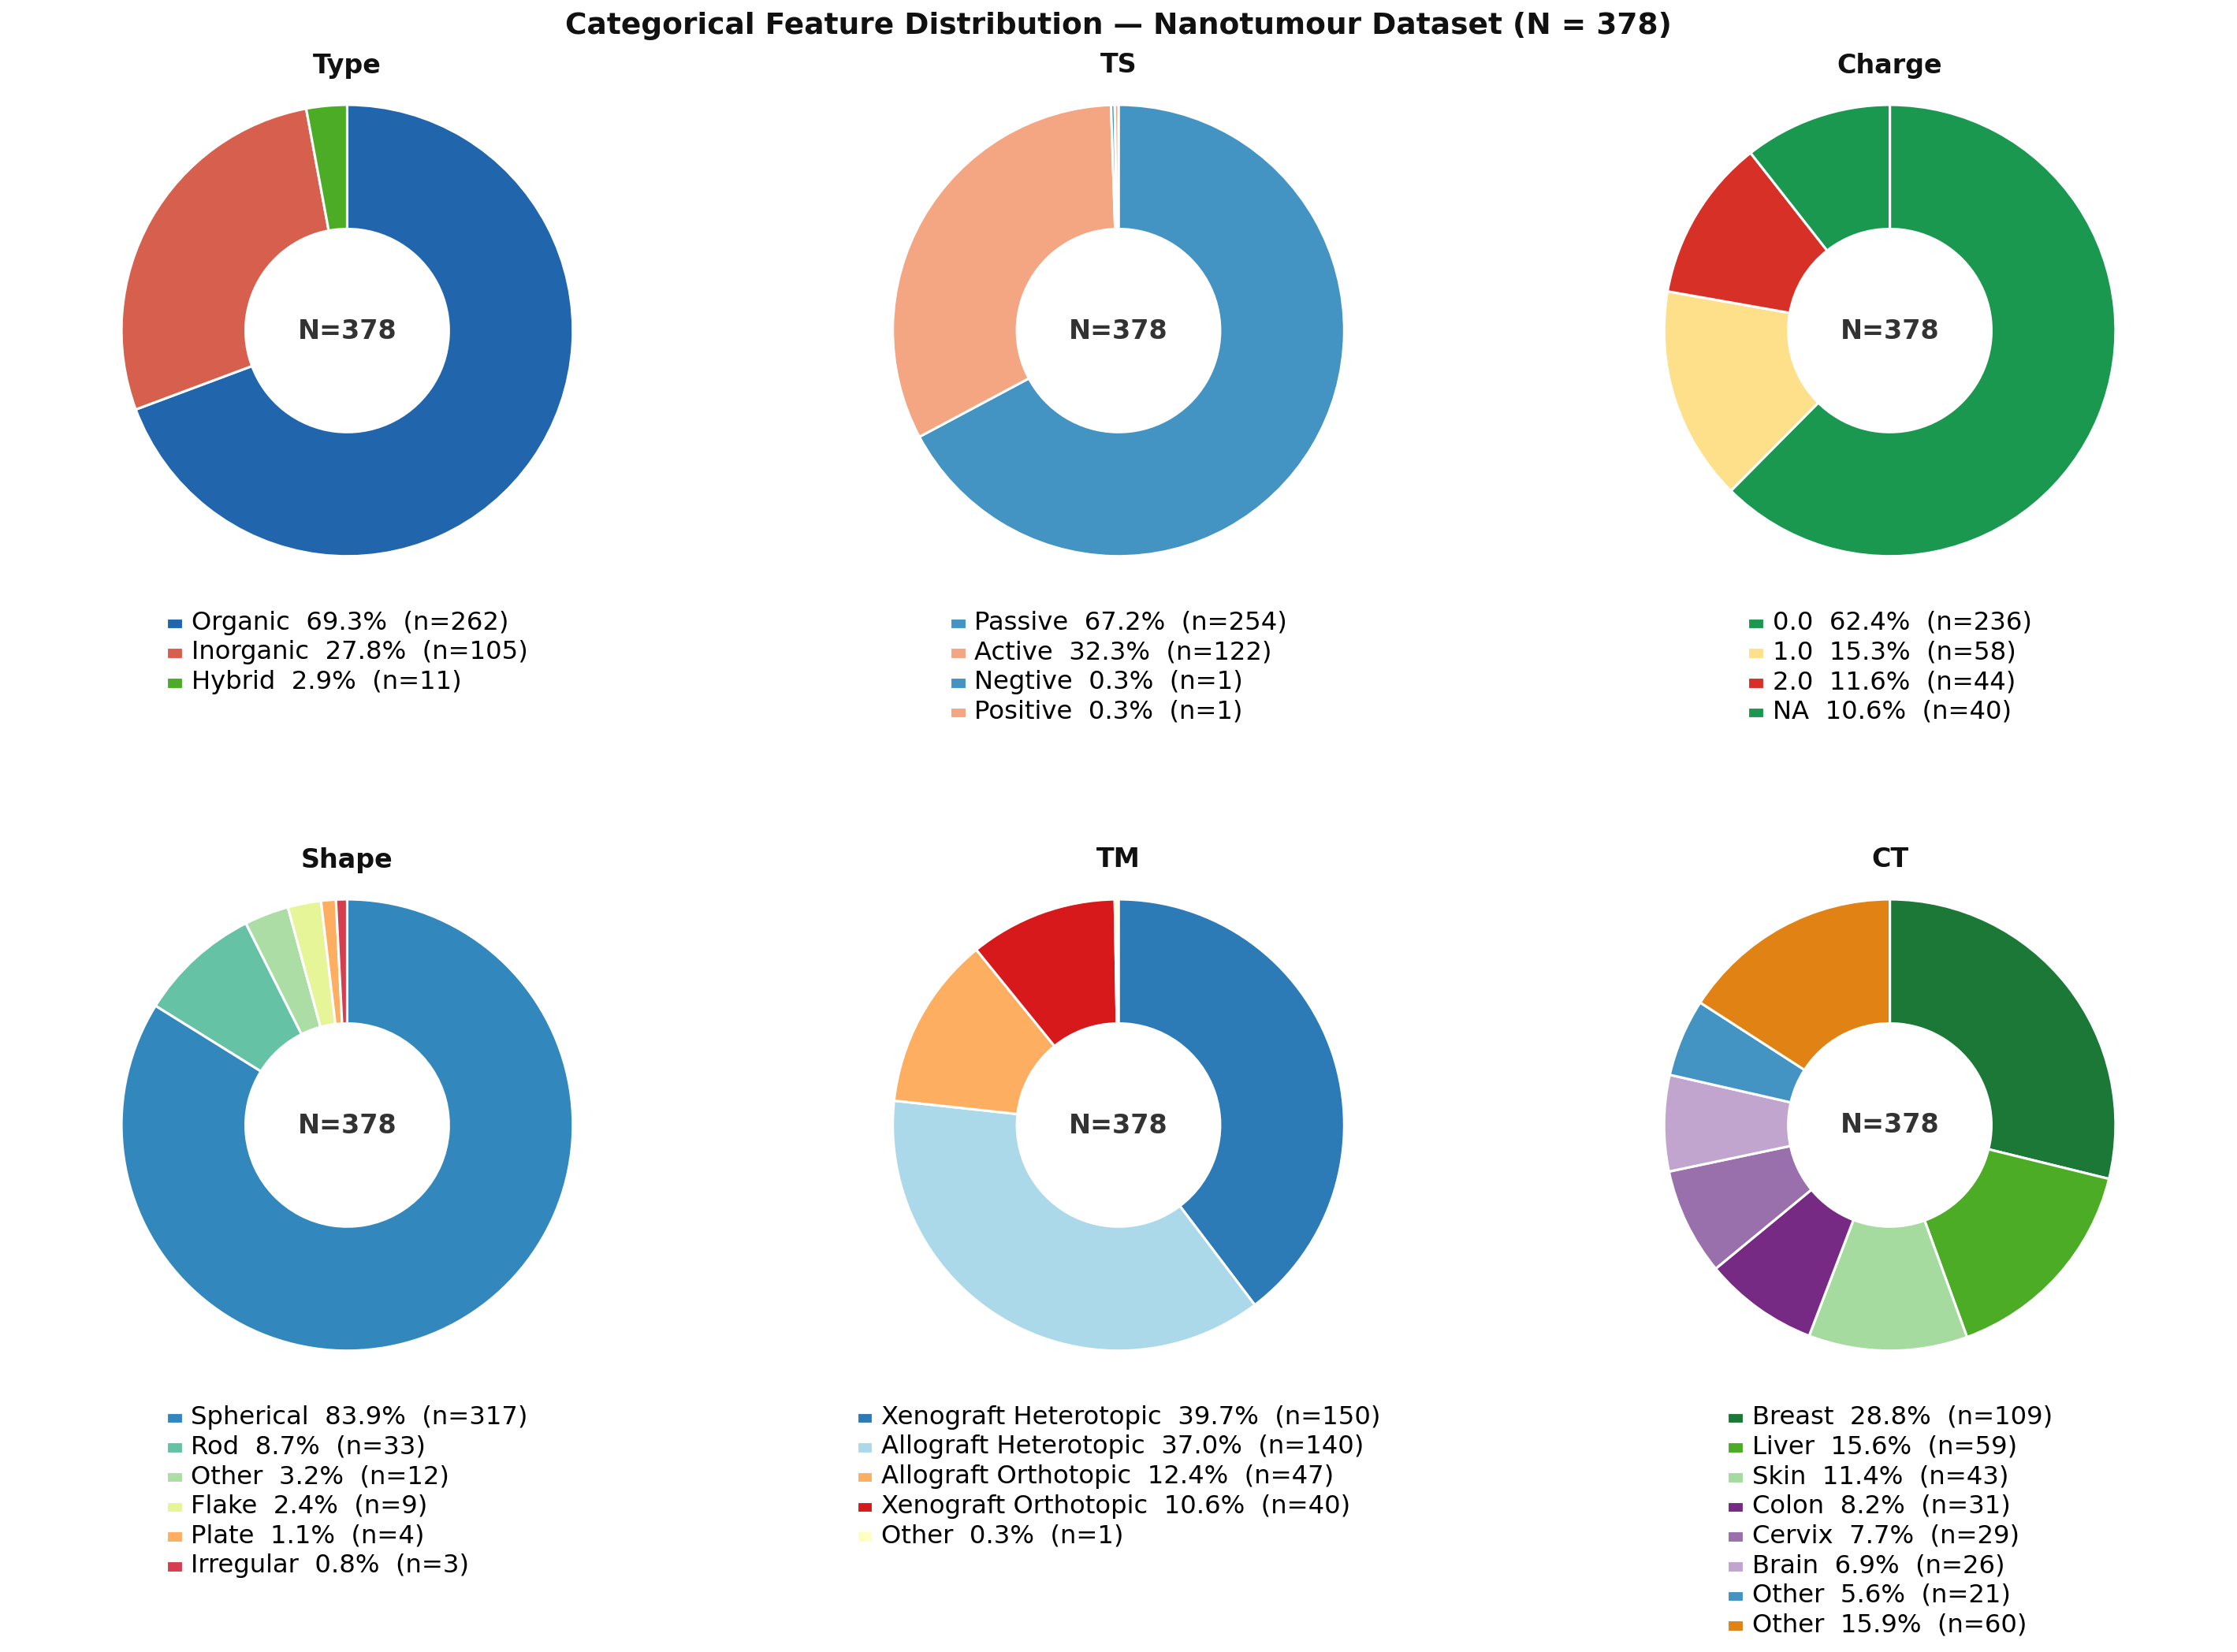

In [ ]:
import math
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

PALETTES = {
    'Type'  : ['#2166AC','#D6604D','#4DAC26'],
    'TS'    : ['#4393C3','#F4A582'],
    'Charge': ['#1A9850','#FEE08B','#D73027'],
    'Shape' : ['#3288BD','#66C2A5','#ABDDA4','#E6F598','#FDAE61','#D53E4F'],
    'TM'    : ['#2C7BB6','#ABD9E9','#FDAE61','#D7191C','#FFFFBF'],
    'CT'    : ['#1B7837','#4DAC26','#A6DBA0','#762A83','#9970AB',
               '#C2A5CF','#4393C3','#E08214','#D9F0D3'],
}
DEFAULT_PAL = ['#2166AC','#D6604D','#4DAC26','#762A83','#E08214',
               '#35978F','#BF812D','#80CDC1','#DFC27D','#999999']

mpl.rcParams.update({
    'figure.dpi'   : 150,
    'savefig.dpi'  : 600,
    'font.family'  : 'DejaVu Sans',
    'font.size'    : 19,
    'pdf.fonttype' : 42,
    'ps.fonttype'  : 42,
})

def topN_with_other(series, topn=7):
    s = (series.astype(str).str.strip()
               .str.title()
               .replace({'Nan':'NA','':'NA'}))
    vc = s.value_counts(dropna=False)
    if len(vc) <= topn:
        return vc
    return pd.concat([vc.iloc[:topn],
                      pd.Series({'Other': vc.iloc[topn:].sum()})])

def draw_donut(ax, col, df, topn=7):
    counts = topN_with_other(df[col], topn=topn)
    labels = list(counts.index)
    values = counts.values.astype(float)
    total  = values.sum()
    colors = PALETTES.get(col, DEFAULT_PAL)[:len(values)]

    wedges, _ = ax.pie(
        values,
        colors       = colors,
        startangle   = 90,
        counterclock = False,
        radius       = 1.0,
        wedgeprops   = {'edgecolor':'white','linewidth':1.5,'width':0.55},
    )

    ax.text(0, 0, f'N={int(total)}',
            ha='center', va='center',
            fontsize=16, fontweight='bold', color='#333333')

    ax.set_title(col, pad=6, fontsize=16,
                 fontweight='bold', color='#111111')
    ax.axis('equal')

    leg_labels = [
        f"{lbl}  {v/total*100:.1f}%  (n={int(v)})"
        for lbl, v in zip(labels, values)
    ]
    leg = ax.legend(
        wedges, leg_labels,
        loc            = 'upper center',
        bbox_to_anchor = (0.5, -0.04),
        ncol           = 1,
        frameon        = False,
        handlelength   = 1.0,
        handletextpad  = 0.5,
        borderpad      = 0.2,
        labelspacing   = 0.32,
    )
    for txt in leg.get_texts():
        txt.set_fontsize(15.5)

candidate_cols = ['Type','TS','Charge','Shape','TM','CT']
cat_cols = [c for c in candidate_cols if c in df.columns]

N_COLS  = 3
n_plots = len(cat_cols)
n_rows  = math.ceil(n_plots / N_COLS)

fig = plt.figure(figsize=(6.5*N_COLS, 6.0*n_rows), facecolor='white')
gs  = GridSpec(n_rows, N_COLS, figure=fig,
               hspace=0.60, wspace=0.15,
               left=0.02, right=0.98, top=0.93, bottom=0.02)

for idx, col in enumerate(cat_cols):
    ax = fig.add_subplot(gs[idx//N_COLS, idx%N_COLS])
    draw_donut(ax, col, df, topn=7)

for j in range(n_plots, n_rows*N_COLS):
    fig.add_subplot(gs[j//N_COLS, j%N_COLS]).set_visible(False)

fig.suptitle(
    f'Categorical Feature Distribution — Nanotumour Dataset (N = {len(df)})',
    fontsize=18, fontweight='bold', y=0.98, color='#111111'
)

plt.savefig('categorical_distribution_publication.png',
            dpi=600, bbox_inches='tight', facecolor='white')
plt.savefig('categorical_distribution_publication.pdf',
            bbox_inches='tight', facecolor='white')
plt.show()

Numeric-like columns: ['Zeta', 'Dose', 'HD', 'Charge', 'TSz', 'TW']
Categorical-like columns: ['TS', 'TM', 'CT', 'Type', 'Shape']


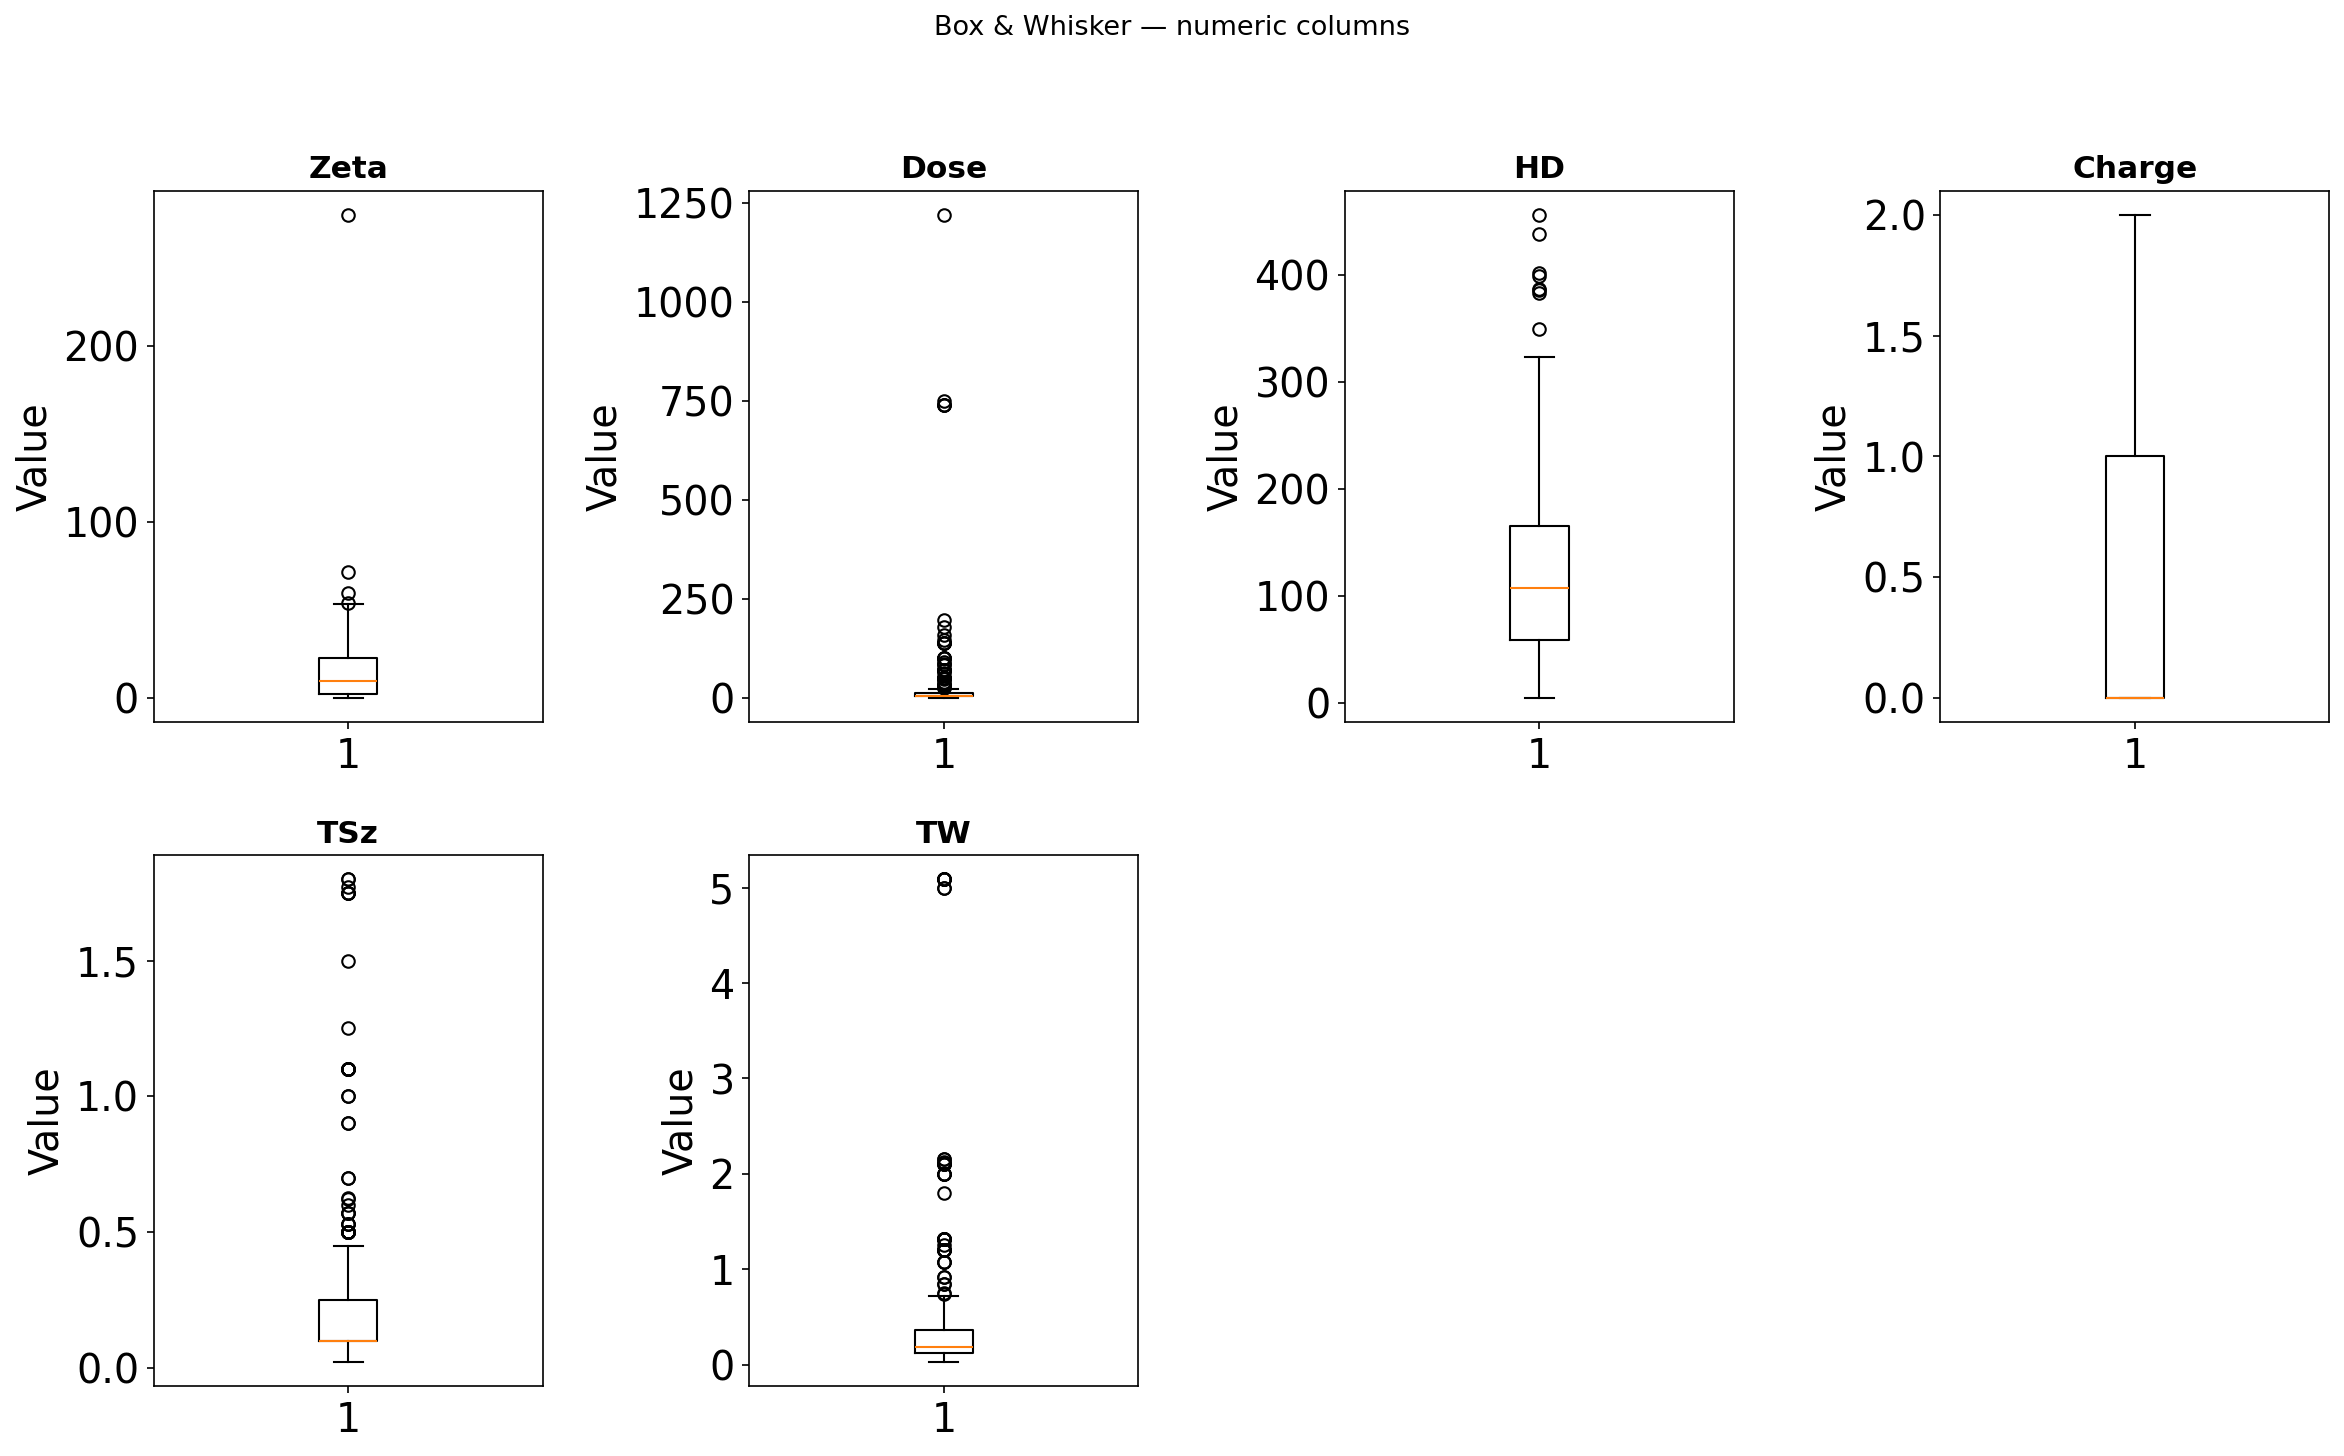

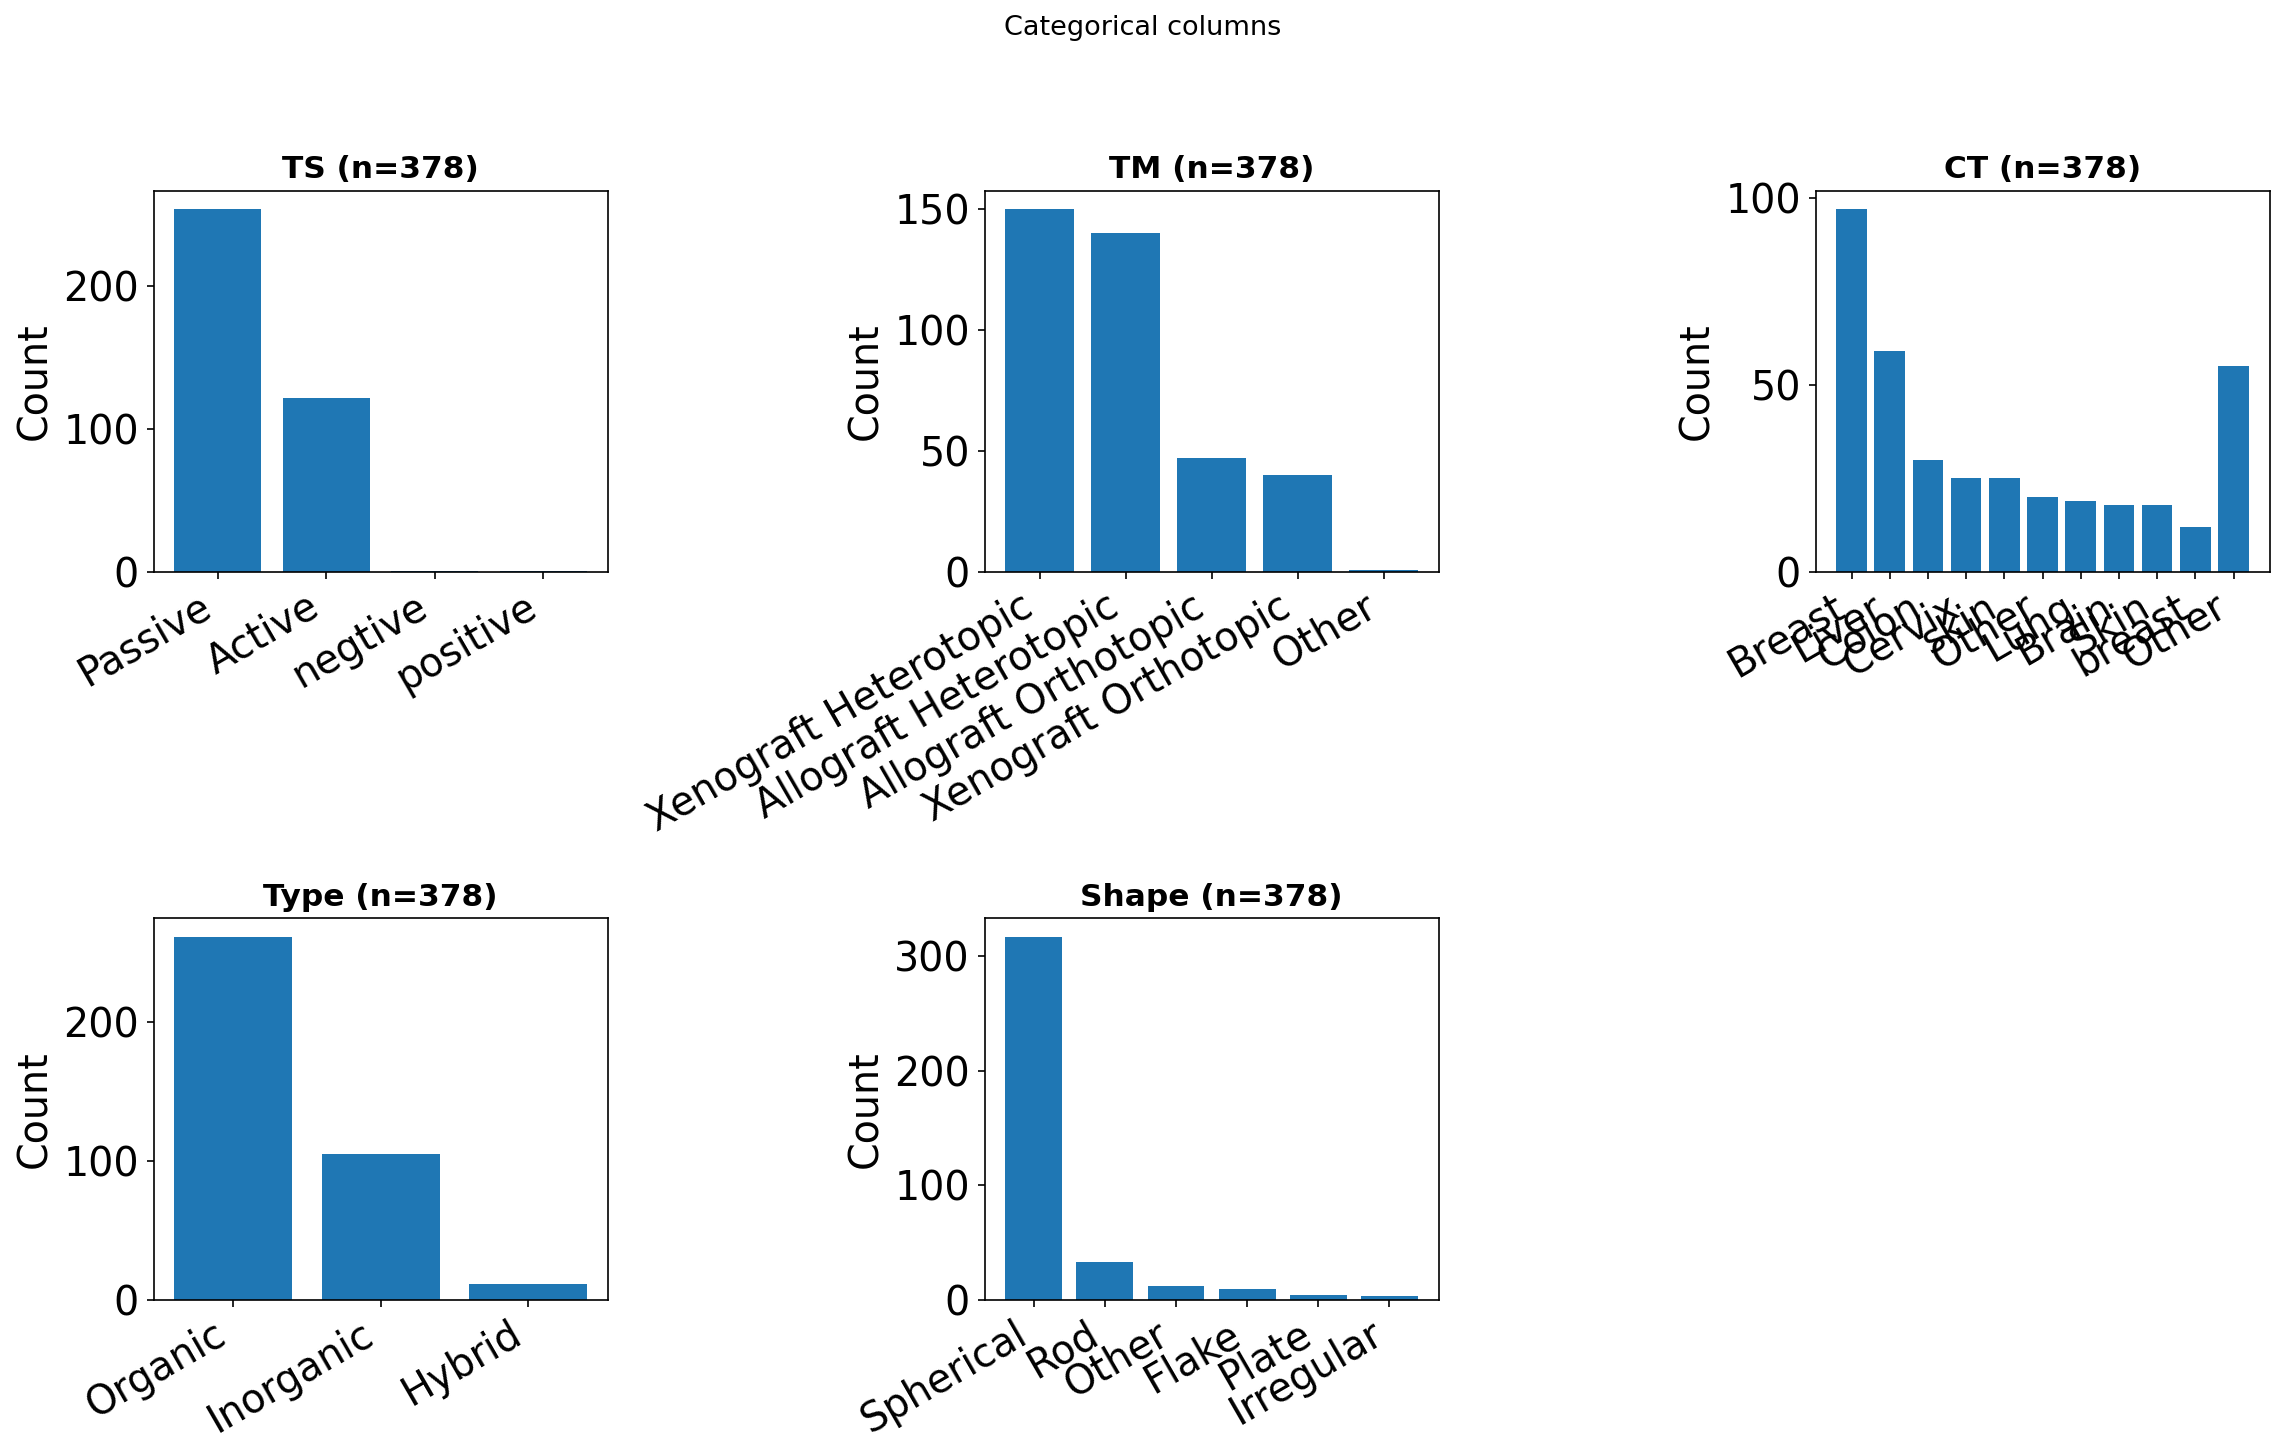

In [ ]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------- config ----------
cols_wanted = ["Zeta","Dose","TS","HD","Charge","TM","CT","TSz","Type","Shape","TW"]
convert_threshold = 0.6   # ≥60% values convertible to numeric -> treat as numeric
topn_cats = 10            # show top N categories, lump the rest into "Other"
# ---------------------------

def coerce_numeric(series):
    """Try to coerce to numeric (handles strings like '12.3')."""
    s = pd.to_numeric(series.replace({',':''}, regex=True), errors="coerce")
    return s

def split_numeric_vs_categorical(df, cols):
    numeric_cols, categorical_cols = [], []
    for c in cols:
        if c not in df.columns:
            continue
        s = df[c]
        # try coercion
        s_num = coerce_numeric(s)
        frac_num = s_num.notna().mean()
        if frac_num >= convert_threshold:
            numeric_cols.append(c)
        else:
            categorical_cols.append(c)
    return numeric_cols, categorical_cols

def topN_with_other_counts(s, topn=10, other_label="Other"):
    vc = s.value_counts(dropna=False)
    if len(vc) <= topn:
        return vc
    head = vc.iloc[:topn]
    tail_sum = vc.iloc[topn:].sum()
    return pd.concat([head, pd.Series({other_label: tail_sum})])

def plot_boxgrid(df, num_cols, ncols=4):
    if not num_cols:
        return
    data = [coerce_numeric(df[c]).dropna().values for c in num_cols]
    # drop empty
    keep = [i for i, d in enumerate(data) if len(d) > 0]
    num_cols = [num_cols[i] for i in keep]
    data = [data[i] for i in keep]
    if not data:
        return
    # grid
    n = len(num_cols); nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 4.8*nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, c, d in zip(axes, num_cols, data):
        ax.boxplot(d, vert=True, whis=1.5, showfliers=True)
        ax.set_title(c)
        ax.set_ylabel("Value")
    for ax in axes[len(num_cols):]:
        fig.delaxes(ax)
    fig.suptitle("Box & Whisker — numeric columns", y=1.02, fontsize=13)
    plt.tight_layout()
    plt.show()

def plot_catgrid(df, cat_cols, ncols=3, pie=False):
    if not cat_cols:
        return
    n = len(cat_cols); nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2*ncols, 4.8*nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, c in zip(axes, cat_cols):
        s = (df[c].astype("string").str.strip().replace({"": np.nan}))
        counts = topN_with_other_counts(s.fillna("NA"), topn=topn_cats)
        if pie:
            ax.pie(counts.values, labels=[str(x) for x in counts.index],
                   autopct="%1.1f%%", startangle=90,
                   wedgeprops={"edgecolor":"white","linewidth":1})
            ax.axis("equal")
        else:
            ax.bar(range(len(counts)), counts.values)
            ax.set_xticks(range(len(counts)))
            ax.set_xticklabels([str(x) for x in counts.index], rotation=30, ha="right")
            ax.set_ylabel("Count")
        ax.set_title(f"{c} (n={s.notna().sum()})")
    for ax in axes[len(cat_cols):]:
        fig.delaxes(ax)
    fig.suptitle("Categorical columns", y=1.02, fontsize=13)
    plt.tight_layout()
    plt.show()

# ---------- run ----------
cols = [c for c in cols_wanted if c in df.columns]
num_cols, cat_cols = split_numeric_vs_categorical(df, cols)

print("Numeric-like columns:", num_cols)
print("Categorical-like columns:", cat_cols)

plot_boxgrid(df, num_cols, ncols=4)           # boxplots
plot_catgrid(df, cat_cols, ncols=3, pie=False)  # bar charts (use pie=True for pies)


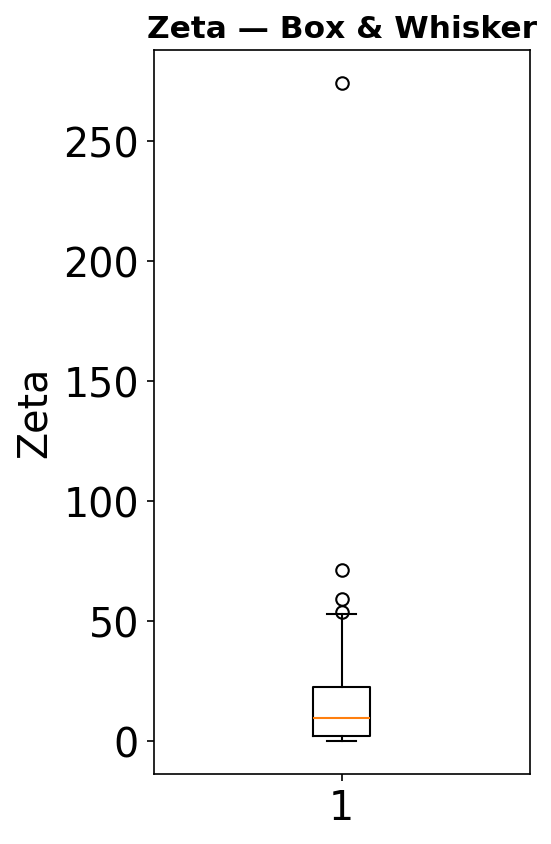

In [ ]:
# drop NaNs to avoid warnings
z = pd.to_numeric(df["Zeta"], errors="coerce").dropna()

plt.figure(figsize=(4, 6))
plt.boxplot(z, vert=True, whis=1.5, showfliers=True)  # 1.5*IQR whiskers; show outliers
plt.ylabel("Zeta")
plt.title("Zeta — Box & Whisker")
plt.tight_layout()
plt.show()

In [ ]:
total_sample=df.size
total_sample = len(df)
dropped_rows = []
#df.shape

In [ ]:
df.isna().sum()

,0
ID,0
Type,0
TS,0
HD,36
Zeta,44
Charge,40
Shape,0
TM,0
CT,0
TSz,31


In [ ]:
df.iloc[:,:].value_counts()

,,,,,,,,,,,,,,,,,,,,,,,,,count
ID,Type,TS,HD,Zeta,Charge,Shape,TM,CT,TSz,TW,Dose,BW,DE24,DE168,Demax,KTRESrelease,KTRESmax,KTRES50,KTRESn,QTC,VTC,BVT,PT,PATC,
5,Inorganic,Active,68.40,9.30,0.0,Other,Xenograft Heterotopic,breast,0.175,0.2100,4.8000,20.0,0.420,1.670,1.770,0.0010,24.0000,108.000,5.00,0.010,0.01100,0.02,0.05500,0.005000,1
6,Inorganic,Passive,166.00,6.00,0.0,Spherical,Xenograft Orthotopic,skin,1.100,1.3200,27.0600,21.0,5.630,4.250,6.410,0.0010,0.2000,72.000,3.00,0.010,0.06300,0.02,0.13200,0.017000,1
7,Inorganic,Active,175.60,5.00,0.0,Spherical,Xenograft Orthotopic,skin,1.100,1.3200,27.0600,21.0,9.610,2.980,11.150,1.0500,5.0000,3.000,2.00,0.010,0.06300,0.02,0.05000,0.100000,1
8,Inorganic,Passive,104.20,10.00,0.0,Spherical,Xenograft Orthotopic,skin,1.100,1.3200,16.2400,21.0,11.980,4.530,14.770,0.1400,1.3000,0.600,1.50,0.010,0.06300,0.02,0.04100,0.090000,1
9,Inorganic,Passive,64.20,15.00,0.0,Spherical,Xenograft Orthotopic,skin,1.100,1.3200,8.1200,21.0,14.710,5.470,17.520,0.1400,1.4000,0.100,2.00,0.010,0.06300,0.02,0.04600,0.090000,1
10,Inorganic,Passive,46.30,6.70,0.0,Spherical,Xenograft Orthotopic,skin,1.100,1.3200,4.0600,21.0,18.110,7.790,23.400,0.1150,1.7500,0.800,1.50,0.010,0.06300,0.02,0.04800,0.090000,1
11,Inorganic,Active,49.50,0.64,0.0,Spherical,Xenograft Orthotopic,skin,1.100,1.3200,4.0600,21.0,22.860,11.000,29.880,0.1050,2.5000,6.000,0.25,0.010,0.06300,0.02,0.07600,0.090000,1
12,Inorganic,Active,60.00,11.00,0.0,Spherical,Xenograft Orthotopic,skin,1.100,1.3200,8.1200,21.0,26.630,9.940,30.240,0.1900,2.3000,0.200,0.10,0.010,0.06300,0.02,0.12000,0.200000,1
13,Inorganic,Active,100.40,9.00,0.0,Spherical,Xenograft Orthotopic,skin,1.100,1.3200,16.2400,21.0,26.870,8.770,29.780,1.2000,5.0000,0.800,1.50,0.010,0.06300,0.02,0.04800,0.090000,1


In [ ]:
df.head(30)

,ID,Type,TS,HD,Zeta,Charge,Shape,TM,CT,TSz,TW,Dose,BW,DE24,DE168,Demax,KTRESrelease,KTRESmax,KTRES50,KTRESn,QTC,VTC,BVT,PT,PATC
0,1,Inorganic,Active,NaN,18.00,0.0,Rod,Xenograft Heterotopic,cervix,0.100,0.1200,2.000000e+01,20.0,1.69,2.06,2.36,0.0010,0.055,0.50,0.50,0.01,0.0060,0.02,0.2650,0.0100
1,2,Inorganic,Passive,NaN,0.00,2.0,Rod,Allograft Heterotopic,colon,NaN,0.1423,1.205000e+01,20.0,0.99,0.79,2.39,0.0550,0.400,12.00,5.00,0.01,0.0071,0.02,0.1000,0.1000
2,3,Inorganic,Active,42.00,5.00,0.0,Spherical,Xenograft Heterotopic,brain,NaN,0.9167,1.000000e+00,20.0,3.27,2.83,4.18,0.0070,0.045,2.00,5.00,0.01,0.0458,0.02,0.0700,0.0700
3,4,Inorganic,Passive,38.30,5.00,0.0,Spherical,Xenograft Heterotopic,brain,NaN,0.9167,1.000000e+00,20.0,6.64,2.99,7.44,0.0001,0.006,2.00,5.00,0.01,0.0458,0.02,0.2000,0.1000
4,5,Inorganic,Active,68.40,9.30,0.0,Other,Xenograft Heterotopic,breast,0.175,0.2100,4.800000e+00,20.0,0.42,1.67,1.77,0.0010,24.000,108.00,5.00,0.01,0.0110,0.02,0.0550,0.0050
5,6,Inorganic,Passive,166.00,6.00,0.0,Spherical,Xenograft Orthotopic,skin,1.100,1.3200,2.706000e+01,21.0,5.63,4.25,6.41,0.0010,0.200,72.00,3.00,0.01,0.0630,0.02,0.1320,0.0170
6,7,Inorganic,Active,175.60,5.00,0.0,Spherical,Xenograft Orthotopic,skin,1.100,1.3200,2.706000e+01,21.0,9.61,2.98,11.15,1.0500,5.000,3.00,2.00,0.01,0.0630,0.02,0.0500,0.1000
7,8,Inorganic,Passive,104.20,10.00,0.0,Spherical,Xenograft Orthotopic,skin,1.100,1.3200,1.624000e+01,21.0,11.98,4.53,14.77,0.1400,1.300,0.60,1.50,0.01,0.0630,0.02,0.0410,0.0900
8,9,Inorganic,Passive,64.20,15.00,0.0,Spherical,Xenograft Orthotopic,skin,1.100,1.3200,8.120000e+00,21.0,14.71,5.47,17.52,0.1400,1.400,0.10,2.00,0.01,0.0630,0.02,0.0460,0.0900
9,10,Inorganic,Passive,46.30,6.70,0.0,Spherical,Xenograft Orthotopic,skin,1.100,1.3200,4.060000e+00,21.0,18.11,7.79,23.40,0.1150,1.750,0.80,1.50,0.01,0.0630,0.02,0.0480,0.0900


In [ ]:
#Encoding non numeric data using label encoder
from sklearn.preprocessing import LabelEncoder
labelencoder = LabelEncoder()


df.head()

,ID,Type,TS,HD,Zeta,Charge,Shape,TM,CT,TSz,TW,Dose,BW,DE24,DE168,Demax,KTRESrelease,KTRESmax,KTRES50,KTRESn,QTC,VTC,BVT,PT,PATC
0,1,Inorganic,Active,NaN,18.0,0.0,Rod,Xenograft Heterotopic,cervix,0.100,0.1200,20.00,20.0,1.69,2.06,2.36,0.0010,0.055,0.5,0.5,0.01,0.0060,0.02,0.265,0.010
1,2,Inorganic,Passive,NaN,0.0,2.0,Rod,Allograft Heterotopic,colon,NaN,0.1423,12.05,20.0,0.99,0.79,2.39,0.0550,0.400,12.0,5.0,0.01,0.0071,0.02,0.100,0.100
2,3,Inorganic,Active,42.0,5.0,0.0,Spherical,Xenograft Heterotopic,brain,NaN,0.9167,1.00,20.0,3.27,2.83,4.18,0.0070,0.045,2.0,5.0,0.01,0.0458,0.02,0.070,0.070
3,4,Inorganic,Passive,38.3,5.0,0.0,Spherical,Xenograft Heterotopic,brain,NaN,0.9167,1.00,20.0,6.64,2.99,7.44,0.0001,0.006,2.0,5.0,0.01,0.0458,0.02,0.200,0.100
4,5,Inorganic,Active,68.4,9.3,0.0,Other,Xenograft Heterotopic,breast,0.175,0.2100,4.80,20.0,0.42,1.67,1.77,0.0010,24.000,108.0,5.0,0.01,0.0110,0.02,0.055,0.005


n = 378
Pearson  r(Dose, Demax) = -0.003   (p = 0.952)
Spearman r(Dose, Demax) = +0.076   (p = 0.141)
Demax range: 0.008–56.89  (percent delivery efficiency)


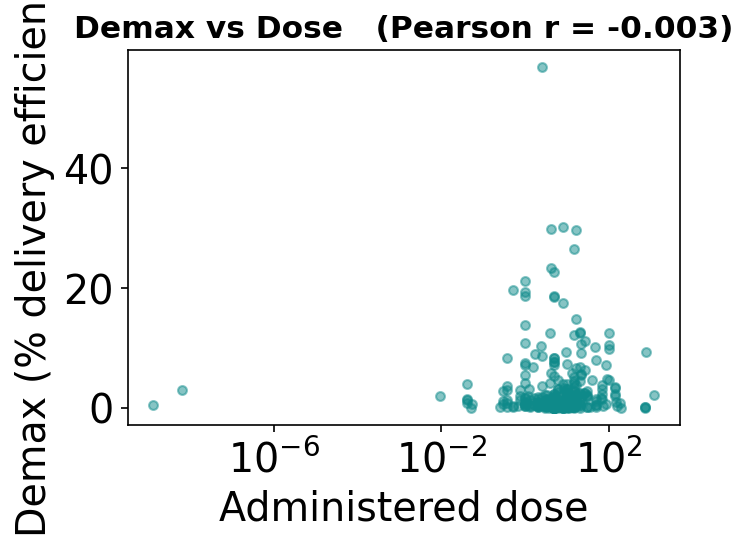

In [ ]:
# Pearson (and Spearman) correlation between Demax and Dose in AI_nano
import pandas as pd
from scipy.stats import pearsonr, spearmanr

dose  = pd.to_numeric(df["Dose"],  errors="coerce")
demax = pd.to_numeric(df["Demax"], errors="coerce")
mask  = dose.notna() & demax.notna()

r_p, p_p = pearsonr(dose[mask],  demax[mask])
r_s, p_s = spearmanr(dose[mask], demax[mask])

print(f"n = {int(mask.sum())}")
print(f"Pearson  r(Dose, Demax) = {r_p:+.3f}   (p = {p_p:.3g})")
print(f"Spearman r(Dose, Demax) = {r_s:+.3f}   (p = {p_s:.3g})")
print(f"Demax range: {demax[mask].min():.3f}–{demax[mask].max():.2f}  (percent delivery efficiency)")

# optional quick visual check
import matplotlib.pyplot as plt
plt.figure(figsize=(5,4))
plt.scatter(dose[mask], demax[mask], s=18, alpha=0.5, color="#0E8A8A")
plt.xscale("log")                     # Dose spans many orders of magnitude
plt.xlabel("Administered dose"); plt.ylabel("Demax (% delivery efficiency)")
plt.title(f"Demax vs Dose   (Pearson r = {r_p:+.3f})")
plt.tight_layout(); plt.show()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
# --- Drop rows with NaN ---
df = df.dropna().reset_index(drop=True)

#--- Impute NaNs (numeric only) instead of dropping ---
# imputer_mean = SimpleImputer(strategy='mean', missing_values=np.nan)
# num_cols = df.select_dtypes(include=[np.number]).columns
# df[num_cols] = imputer_mean.fit_transform(df[num_cols])
# df = df.reset_index(drop=True)


In [ ]:
df['HD_log'] = np.where(df['HD'] > 0, np.log(df['HD']), np.nan)        ###########################
df['HD'] = df['HD_log']                                                  ###########################
df.drop(columns=['HD_log'], inplace=True)                               ##################


In [ ]:
#ktres_cols = ["KTRESrelease", "KTRESmax", "KTRES50", "KTRESn"]
# den = df["Demax"].replace(0, np.nan)
#y = df["Demax"].div(df["KTRESrelease"], axis=0)     ################################
#y = df["Demax"].div(df["KTRESmax"], axis=0)
#y=df["KTRESmax"]
#y=df["KTRES50"]
#y = df["DE24"]
#y = df["DE168"]
y=df['Demax']


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# --- Define all Y candidates ---
#Y_cols = ["KTRESrelease", "KTRESmax", "KTRES50", "KTRESn","Demax"]

# --- Select current target ---
#target_col = "KTRESrelease"              #########################################################################################
#target_col = "Demax"
#target_col = "DE_Tmax_PK"

# --- Split into X and y ---
#X = df.drop(columns=Y_cols)   # remove all Y cols from features
X = df[["Type","TS","HD","Zeta","Charge","Shape", "TM", "CT", "TSz", "TW"]]          #####################################
#X = df[["Type","MAT","TS","CT","TM","Shape","Size","ZP"]]
#y = df[target_col]            # only KTRESrelease as target                          #####################################

# --- Encode non-numeric columns in X ---
label_mappings = {}
text_cols = X.select_dtypes(include=['object', 'category']).columns

le = LabelEncoder()
for col in text_cols:
    X[col] = le.fit_transform(X[col].astype(str))
    label_mappings[col] = dict(zip(le.classes_, le.transform(le.classes_)))

print("Encoded columns:", list(text_cols))
print("X shape:", X.shape)
print("y shape:", y.shape)

# Preview
print("\nSample of X:")
display(X.head())
print("\nSample of y:")
display(y.head())

Encoded columns: ['Type', 'TS', 'Shape', 'TM', 'CT']
X shape: (288, 10)
y shape: (288,)

Sample of X:


,Type,TS,HD,Zeta,Charge,Shape,TM,CT,TSz,TW
0,1,0,4.225373,9.3,0.0,2,3,13,0.175,0.21
1,1,1,5.111988,6.0,0.0,5,4,16,1.100,1.32
2,1,0,5.168209,5.0,0.0,5,4,16,1.100,1.32
3,1,1,4.646312,10.0,0.0,5,4,16,1.100,1.32
4,1,1,4.162003,15.0,0.0,5,4,16,1.100,1.32



Sample of y:


,Demax
0,1.77
1,6.41
2,11.15
3,14.77
4,17.52


n = 288
Pearson  r(Dose, Demax) = -0.001   (p = 0.991)
Spearman r(Dose, Demax) = +0.084   (p = 0.155)
Demax range: 0.008–30.24  (percent delivery efficiency)


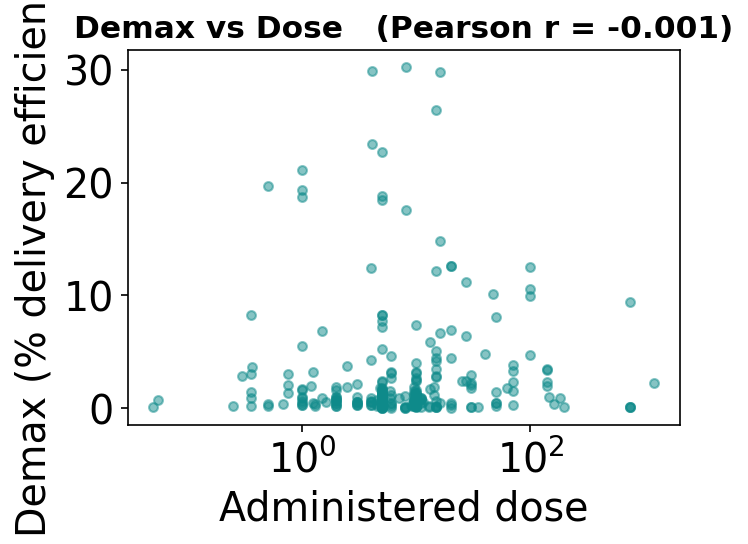

In [ ]:
# Pearson (and Spearman) correlation between Demax and Dose in AI_nano
import pandas as pd
from scipy.stats import pearsonr, spearmanr

dose  = pd.to_numeric(df["Dose"],  errors="coerce")
demax = pd.to_numeric(df["Demax"], errors="coerce")
mask  = dose.notna() & demax.notna()

r_p, p_p = pearsonr(dose[mask],  demax[mask])
r_s, p_s = spearmanr(dose[mask], demax[mask])

print(f"n = {int(mask.sum())}")
print(f"Pearson  r(Dose, Demax) = {r_p:+.3f}   (p = {p_p:.3g})")
print(f"Spearman r(Dose, Demax) = {r_s:+.3f}   (p = {p_s:.3g})")
print(f"Demax range: {demax[mask].min():.3f}–{demax[mask].max():.2f}  (percent delivery efficiency)")

# optional quick visual check
import matplotlib.pyplot as plt
plt.figure(figsize=(5,4))
plt.scatter(dose[mask], demax[mask], s=18, alpha=0.5, color="#0E8A8A")
plt.xscale("log")                     # Dose spans many orders of magnitude
plt.xlabel("Administered dose"); plt.ylabel("Demax (% delivery efficiency)")
plt.title(f"Demax vs Dose   (Pearson r = {r_p:+.3f})")
plt.tight_layout(); plt.show()

In [ ]:
X = pd.DataFrame (X)
Y=y
#Y=pd.DataFrame(Y)
#X=np.log1p(np.asarray(X))
#Y=np.log1p(np.asarray(y)).ravel()                             ###########################

In [ ]:
X.shape

(288, 10)

In [ ]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

# Train/test split
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)
##############################################################
# from sklearn.model_selection import GroupKFold

# # Group labels (must align with X/Y index)
# groups = df.loc[X.index, "TM"]

# # Use up to 5 folds, but not more than the number of CT groups
# n_splits = min(5, groups.nunique())
# gkf = GroupKFold(n_splits=n_splits)

# # Take the first fold as test; remaining folds are train
# train_idx, test_idx = next(gkf.split(X, Y, groups=groups))

# X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
# Y_train, Y_test = Y.iloc[train_idx], Y.iloc[test_idx]
###################################################################


# # Scale X (features)
# X_scaler = MinMaxScaler().fit(X_train)  # e.g., MinMaxScaler(feature_range=(-1, 1))
# X_train_scaled = pd.DataFrame(
#     X_scaler.transform(X_train), index=X.index[train_idx], columns=X.columns
# )
# X_test_scaled = pd.DataFrame(
#     X_scaler.transform(X_test), index=X.index[test_idx], columns=X.columns
# )

# # Scale Y (target) -- regression only
# y_scaler = MinMaxScaler().fit(Y_train.values.reshape(-1, 1))
# Y_train_scaled = y_scaler.transform(Y_train.values.reshape(-1, 1)).ravel()
# Y_test_scaled  = y_scaler.transform(Y_test.values.reshape(-1, 1)).ravel()

In [ ]:
import numpy as np
import pandas as pd
from typing import Iterable, Tuple

def augment_noise(
    X_train: pd.DataFrame,
    Y_train: pd.Series | np.ndarray,
    aug_multiplier: int = 2,
    noise_frac: float = 0.05,
    clip_nonneg_cols: Iterable[str] | None = None,
    cat_strategy: str = "swap",         # {"swap", "resample", "none"}
    cat_swap_p: float = 0.5,
    random_state: int = 42,
    # -------- tail controls --------
    tail: str = "high",                 # {"high","low","both"}
    high_quantile: float = 0.80,        # cutoff for "high" tail
    low_quantile: float = 0.20,         # cutoff for "low" tail
    both_tail_weights: Tuple[float,float] = (0.5, 0.5)  # (low, high) sampling weights when tail="both"
):
    """
    Augment ONLY the selected tail(s) of y.
      - Sample synthetic rows from the chosen tail pool(s).
      - Add small Gaussian jitter to numeric columns.
      - Perturb categoricals by swap/resample within the *same* pool to keep combos realistic.
    """
    rng = np.random.default_rng(random_state)

    # Identify column types
    num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = X_train.columns.difference(num_cols).tolist()

    # y as aligned Series
    y_arr = np.asarray(Y_train).reshape(-1)
    y_ser = pd.Series(y_arr, index=(X_train.index if len(y_arr) == len(X_train) else None))

    n = len(X_train)
    if aug_multiplier <= 1 or n == 0:
        return X_train.copy(), y_ser.copy()

    # --- Build tail pool(s) ---
    q_hi = np.quantile(y_ser, high_quantile)
    q_lo = np.quantile(y_ser, low_quantile)

    if tail == "high":
        pool_idx = np.flatnonzero((y_ser >= q_hi).to_numpy())
        if pool_idx.size == 0:
            raise ValueError("No samples in high tail; lower high_quantile.")
        # All synth from high tail
        base_idx = rng.choice(pool_idx, size=(aug_multiplier-1)*n, replace=True)
        pool_of_each = np.array(["high"] * len(base_idx))
    elif tail == "low":
        pool_idx = np.flatnonzero((y_ser <= q_lo).to_numpy())
        if pool_idx.size == 0:
            raise ValueError("No samples in low tail; raise low_quantile.")
        base_idx = rng.choice(pool_idx, size=(aug_multiplier-1)*n, replace=True)
        pool_of_each = np.array(["low"] * len(base_idx))
    elif tail == "both":
        low_idx  = np.flatnonzero((y_ser <= q_lo).to_numpy())
        high_idx = np.flatnonzero((y_ser >= q_hi).to_numpy())
        if low_idx.size == 0 and high_idx.size == 0:
            raise ValueError("No samples in either tail; adjust quantiles.")
        n_synth = (aug_multiplier-1)*n
        w_low, w_high = both_tail_weights
        w_low = max(w_low, 0.0); w_high = max(w_high, 0.0)
        if w_low + w_high == 0: w_low, w_high = 0.5, 0.5
        choose_high = rng.random(n_synth) < (w_high/(w_low+w_high))
        base_idx = np.empty(n_synth, dtype=int)
        pool_of_each = np.empty(n_synth, dtype=object)
        # sample per chosen pool
        m_high = choose_high
        m_low  = ~choose_high
        if m_high.any():
            if high_idx.size == 0:  # fallback
                base_idx[m_high] = rng.integers(0, n, size=m_high.sum())
            else:
                base_idx[m_high] = rng.choice(high_idx, size=m_high.sum(), replace=True)
            pool_of_each[m_high] = "high"
        if m_low.any():
            if low_idx.size == 0:   # fallback
                base_idx[m_low] = rng.integers(0, n, size=m_low.sum())
            else:
                base_idx[m_low] = rng.choice(low_idx, size=m_low.sum(), replace=True)
            pool_of_each[m_low] = "low"
    else:
        raise ValueError("tail must be one of {'high','low','both'}")

    # --- Build augmented copies from the chosen tails ---
    X_aug = X_train.iloc[base_idx].copy().reset_index(drop=True)
    y_aug = y_ser.iloc[base_idx].reset_index(drop=True)

    # ---- Numeric jitter (use std from the *corresponding pool* if available) ----
    def pool_std(col, which_pool):
        if which_pool == "high":
            mask = (y_ser >= q_hi)
        else:
            mask = (y_ser <= q_lo)
        s = float(X_train.loc[mask, col].std(ddof=0))
        if not np.isfinite(s) or s == 0.0:
            s = float(X_train[col].std(ddof=0))  # fallback to global
        return s if (np.isfinite(s) and s > 0.0) else None

    if num_cols:
        # precompute pool stds
        std_high = {c: pool_std(c, "high") for c in num_cols}
        std_low  = {c: pool_std(c, "low")  for c in num_cols}
        for col in num_cols:
            # pick std per-row based on that row's source pool
            s_high, s_low = std_high[col], std_low[col]
            if s_high is None and s_low is None:
                continue
            s = np.where(pool_of_each == "high",
                         (noise_frac * (s_high if s_high is not None else (s_low or 0.0))),
                         (noise_frac * (s_low  if s_low  is not None else (s_high or 0.0))))
            noise = rng.normal(0.0, s, size=len(X_aug))
            # convert to float to avoid type issues
            X_aug[col] = X_aug[col].to_numpy(dtype=float) + noise

    # Optional: clip non-negatives
    if clip_nonneg_cols:
        for c in set(clip_nonneg_cols).intersection(X_aug.columns):
            if pd.api.types.is_numeric_dtype(X_aug[c]):
                X_aug[c] = X_aug[c].clip(lower=0)

    # ---- Categorical augmentation within the same tail pool ----
    if cat_cols and cat_strategy != "none":
        if cat_strategy == "swap":
            partners = np.empty(len(X_aug), dtype=int)
            # for each synthetic row, pick partner from same pool
            if (pool_of_each == "high").any():
                high_idx = np.flatnonzero((y_ser >= q_hi).to_numpy())
                m = (pool_of_each == "high")
                partners[m] = rng.choice(high_idx if len(high_idx) else np.arange(n), size=m.sum(), replace=True)
            if (pool_of_each == "low").any():
                low_idx = np.flatnonzero((y_ser <= q_lo).to_numpy())
                m = (pool_of_each == "low")
                partners[m] = rng.choice(low_idx if len(low_idx) else np.arange(n), size=m.sum(), replace=True)
            for c in cat_cols:
                orig = X_aug[c].to_numpy(object)
                partner_vals = X_train[c].iloc[partners].to_numpy(object)
                do_swap = rng.random(len(X_aug)) < float(cat_swap_p)
                orig[do_swap] = partner_vals[do_swap]
                if pd.api.types.is_categorical_dtype(X_train[c]):
                    X_aug[c] = pd.Categorical(orig, categories=X_train[c].cat.categories)
                else:
                    X_aug[c] = orig
        elif cat_strategy == "resample":
            for c in cat_cols:
                sampled = []
                for p in pool_of_each:
                    if p == "high":
                        pool = np.flatnonzero((y_ser >= q_hi).to_numpy())
                    else:
                        pool = np.flatnonzero((y_ser <= q_lo).to_numpy())
                    if len(pool) == 0:
                        pool = np.arange(n)
                    sampled.append(X_train[c].iloc[rng.choice(pool)])
                X_aug[c] = np.array(sampled, dtype=object)
        else:
            raise ValueError("cat_strategy must be one of {'swap','resample','none'}")

    # ---- Concatenate & shuffle ----
    X_full = pd.concat([X_train.reset_index(drop=True), X_aug], ignore_index=True)
    y_full = pd.concat([y_ser.reset_index(drop=True), y_aug], ignore_index=True)

    perm = rng.permutation(len(X_full))
    X_full = X_full.iloc[perm].reset_index(drop=True)
    y_full = y_full.iloc[perm].reset_index(drop=True)

    return X_full, y_full


In [ ]:
X_train_aug, Y_train_aug = augment_noise(
    X_train, Y_train,
    aug_multiplier=2,                            # ~2× rows
    noise_frac=0.03,
    #clip_nonneg_cols=['HD','TSz','TW','Dose','BW'],
    cat_strategy='swap', random_state=42,
    tail='both', low_quantile=0.20, high_quantile=0.80,
    both_tail_weights=(0.4, 0.8)                 # 40% low-tail, 60% high-tail
)

# X_train = X_train_aug
# Y_train = Y_train_aug

X_orig = X_train.copy()
y_orig = pd.Series(Y_train).copy()

In [ ]:
#to run the model we will recall the follows:
X_train = X_train_aug
Y_train = Y_train_aug

In [ ]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

def numeric_columns(df):
    return df.select_dtypes(include=[np.number]).columns.tolist()

def categorical_columns(df):
    num = set(numeric_columns(df))
    return [c for c in df.columns if c not in num]

def overlay_hists_per_numeric(X0, X1, cols=None, bins=30, ncols=3, suptitle="Numeric features: original vs augmented"):
    cols = cols or numeric_columns(X0)
    cols = [c for c in cols if c in X0.columns and c in X1.columns]
    if not cols:
        print("[overlay_hists_per_numeric] no numeric columns to plot."); return
    n = len(cols); nrows = math.ceil(n/ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.4*ncols, 3.5*nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, c in zip(axes, cols):
        a = pd.to_numeric(X0[c], errors="coerce").dropna()
        b = pd.to_numeric(X1[c], errors="coerce").dropna()
        if len(a)==0 and len(b)==0:
            ax.set_title(c); ax.text(0.5,0.5,"no data",ha="center",va="center"); ax.axis("off"); continue
        mn = np.nanmin([a.min() if len(a) else np.nan, b.min() if len(b) else np.nan])
        mx = np.nanmax([a.max() if len(a) else np.nan, b.max() if len(b) else np.nan])
        bins_use = np.linspace(mn, mx, bins) if np.isfinite(mn) and np.isfinite(mx) and mn!=mx else bins
        ax.hist(a, bins=bins_use, alpha=0.5, label="original", density=True)
        ax.hist(b, bins=bins_use, alpha=0.5, label="augmented", density=True)
        ax.set_title(c)
        ax.tick_params(axis='x', rotation=20)
    for ax in axes[len(cols):]:
        fig.delaxes(ax)
    handles, labels = axes[0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc="upper right")
    fig.suptitle(suptitle, y=1.02)
    plt.tight_layout(); plt.show()

def bars_per_categorical(X0, X1, cols=None, ncols=3, topn=10, suptitle="Categoricals: original vs augmented"):
    cols = cols or categorical_columns(X0)
    cols = [c for c in cols if c in X0.columns and c in X1.columns]
    if not cols:
        print("[bars_per_categorical] no categorical columns to plot."); return
    n = len(cols); nrows = math.ceil(n/ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2*ncols, 4.2*nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, c in zip(axes, cols):
        s0 = X0[c].astype("string").str.strip().fillna("NA").replace("", "NA")
        s1 = X1[c].astype("string").str.strip().fillna("NA").replace("", "NA")
        vc0 = s0.value_counts().head(topn)
        vc1 = s1.value_counts().head(topn)
        cats = list(dict.fromkeys(list(vc0.index)+list(vc1.index)))  # preserve order
        a = [vc0.get(k, 0) for k in cats]
        b = [vc1.get(k, 0) for k in cats]
        x = np.arange(len(cats)); w = 0.4
        ax.bar(x-w/2, a, width=w, label="original")
        ax.bar(x+w/2, b, width=w, label="augmented")
        ax.set_title(c); ax.set_xticks(x); ax.set_xticklabels(cats, rotation=30, ha="right")
        ax.set_ylabel("count")
    for ax in axes[len(cols):]:
        fig.delaxes(ax)
    handles, labels = axes[0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc="upper right")
    fig.suptitle(suptitle, y=1.02)
    plt.tight_layout(); plt.show()

def y_distribution(y0, y1, bins=40, title="Target Y: original vs augmented"):
    y0 = pd.to_numeric(pd.Series(y0), errors="coerce").dropna()
    y1 = pd.to_numeric(pd.Series(y1), errors="coerce").dropna()
    mn = min(y0.min(), y1.min()); mx = max(y0.max(), y1.max())
    bins_use = np.linspace(mn, mx, bins) if mn != mx else bins
    plt.figure(figsize=(6,4))
    plt.hist(y0, bins=bins_use, alpha=0.5, density=True, label="original")
    plt.hist(y1, bins=bins_use, alpha=0.5, density=True, label="augmented")
    plt.xlabel("Y"); plt.ylabel("density"); plt.title(title); plt.legend(); plt.tight_layout(); plt.show()

def pca_scatter(X0, X1, title="PCA(2D): original vs augmented"):
    # numeric-only, standardize on original to keep scale comparable
    num_cols = numeric_columns(X0)
    if not num_cols:
        print("[pca_scatter] no numeric columns."); return
    A0 = X0[num_cols].apply(pd.to_numeric, errors="coerce").fillna(0.0).to_numpy()
    A1 = X1[num_cols].apply(pd.to_numeric, errors="coerce").fillna(0.0).to_numpy()
    scaler = StandardScaler().fit(A0)
    A0z = scaler.transform(A0)
    A1z = scaler.transform(A1)
    pca = PCA(n_components=2, random_state=0).fit(A0z)
    P0 = pca.transform(A0z)
    P1 = pca.transform(A1z)
    plt.figure(figsize=(6,5))
    plt.scatter(P0[:,0], P0[:,1], s=10, alpha=0.5, label="original")
    plt.scatter(P1[:,0], P1[:,1], s=10, alpha=0.5, label="augmented")
    plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title(title); plt.legend(); plt.tight_layout(); plt.show()


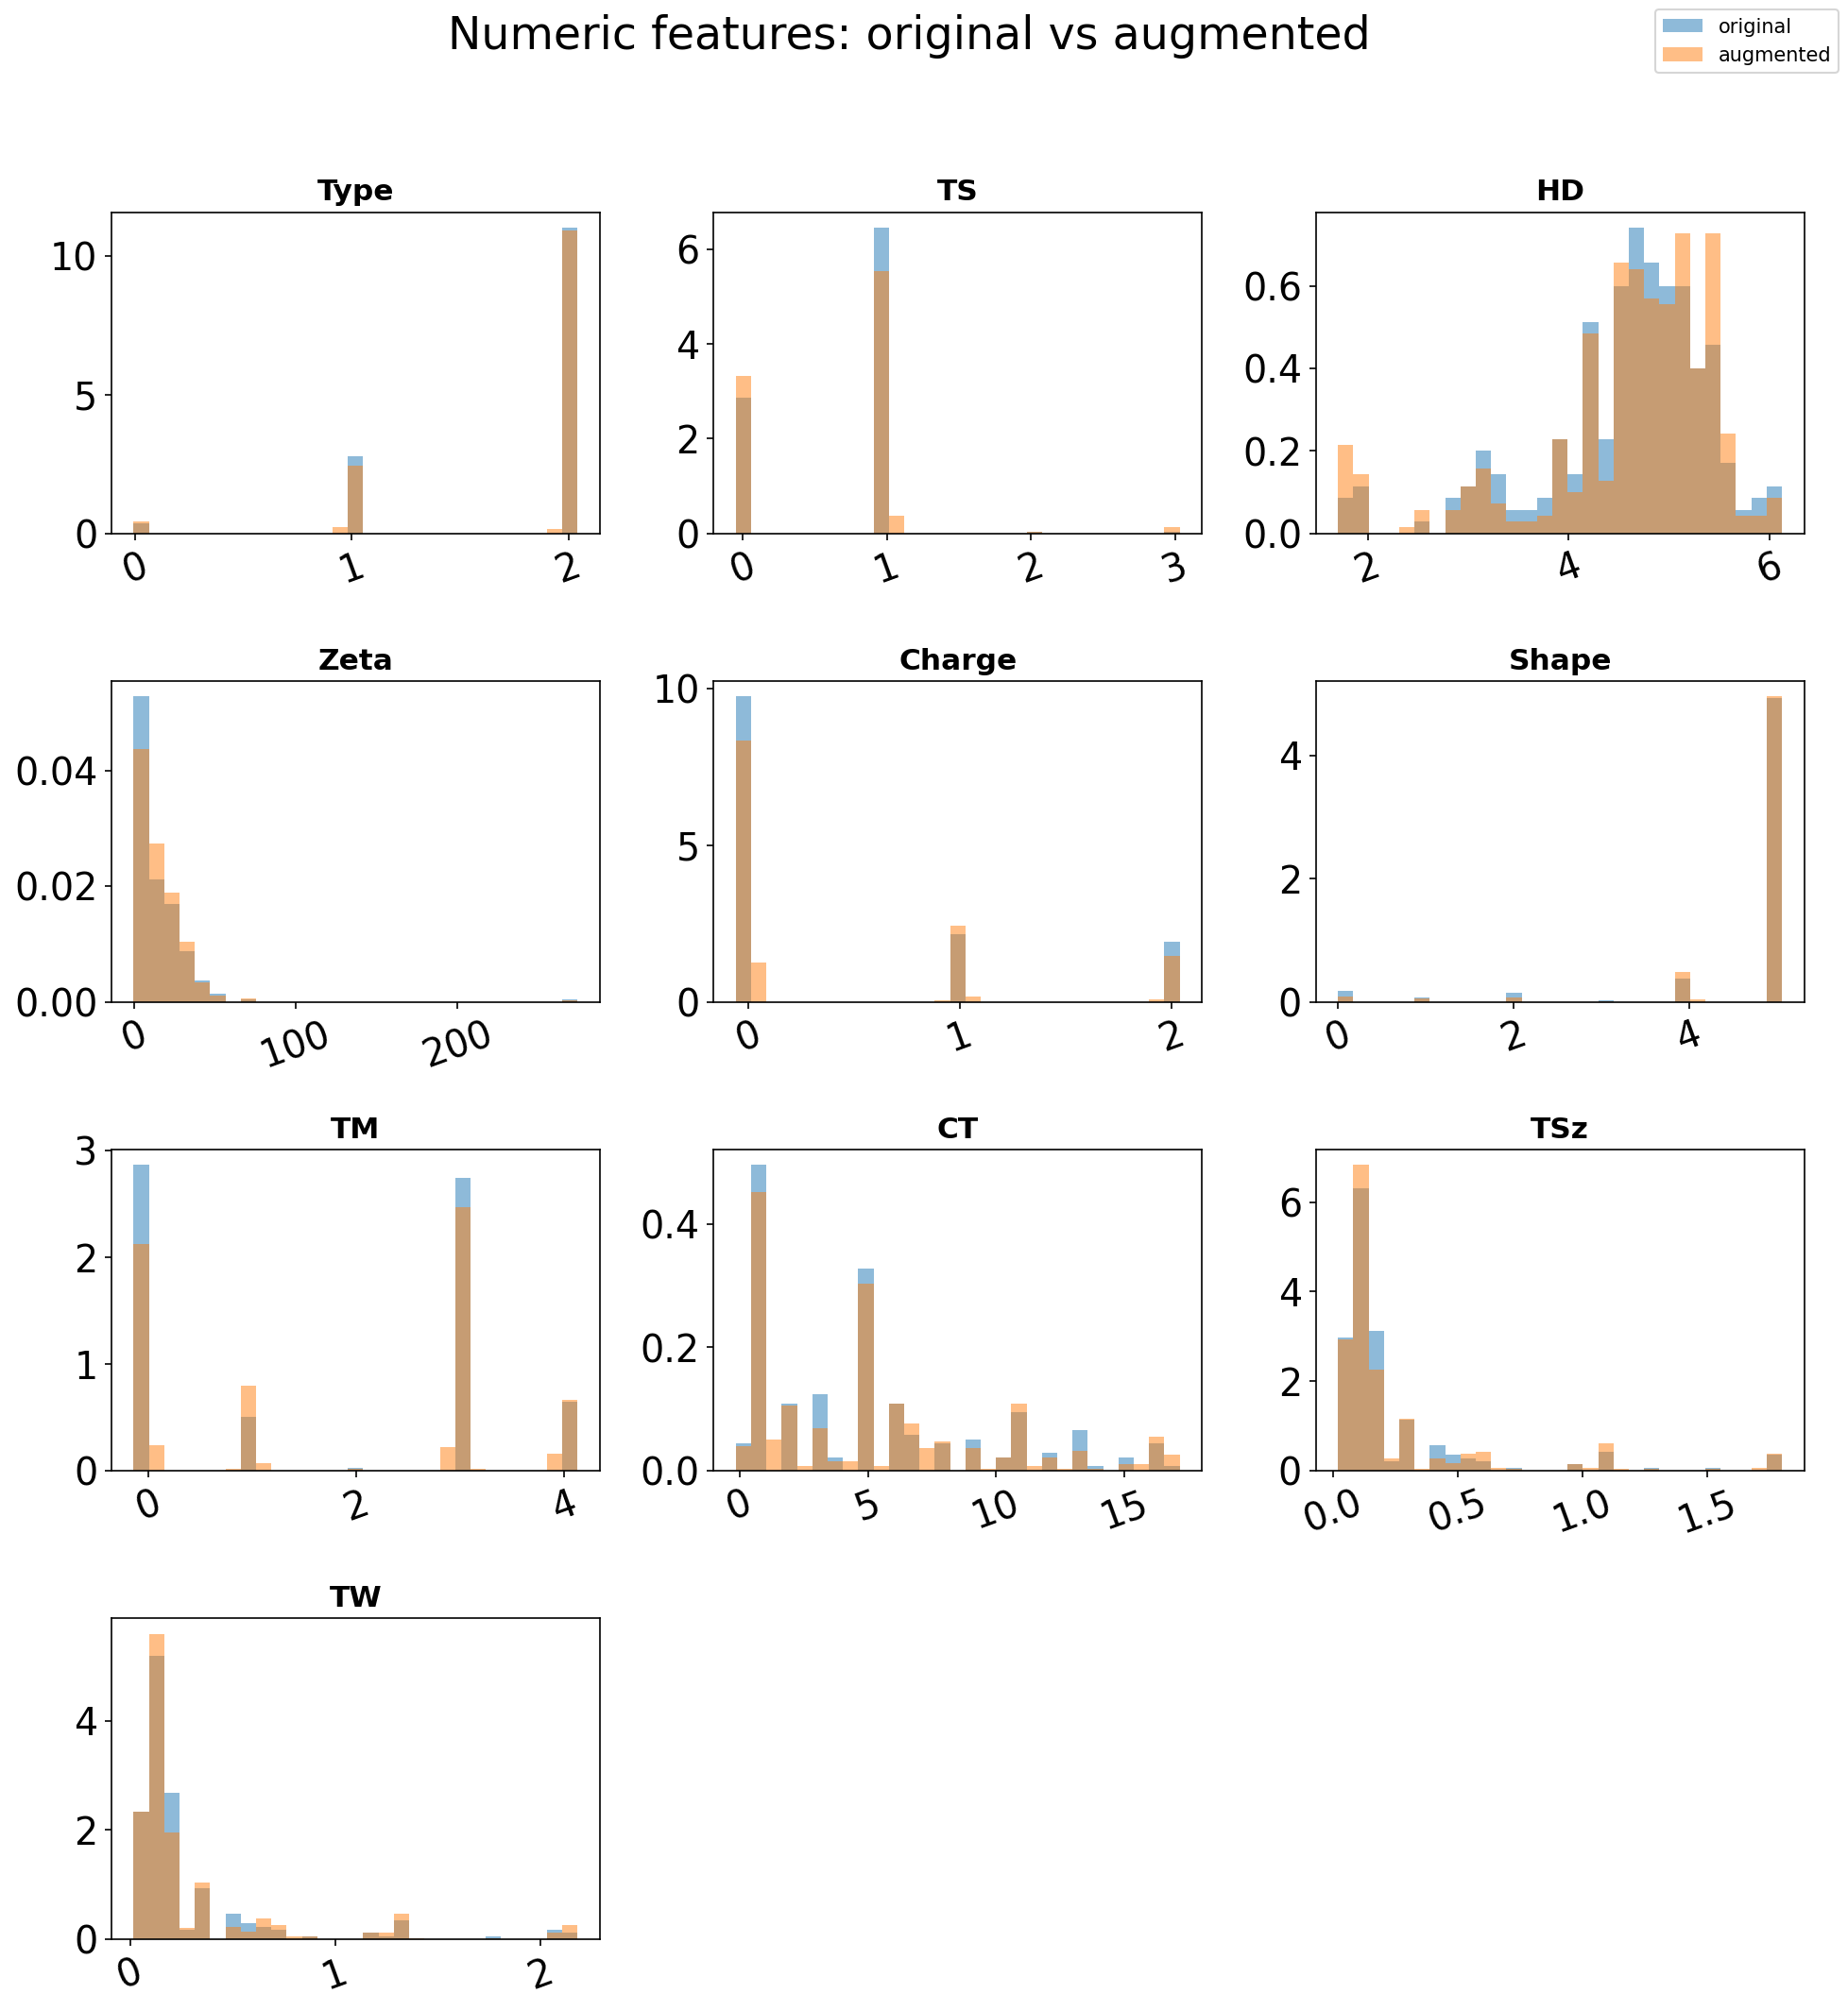

[bars_per_categorical] no categorical columns to plot.


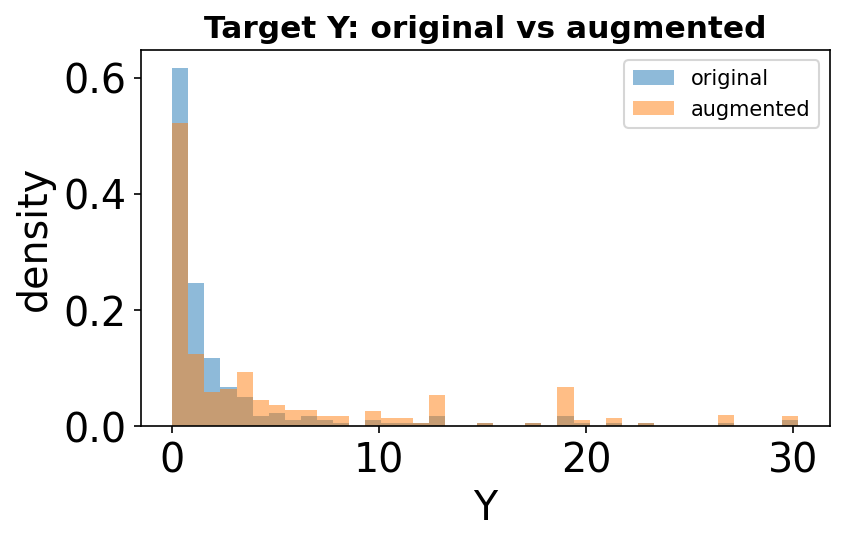

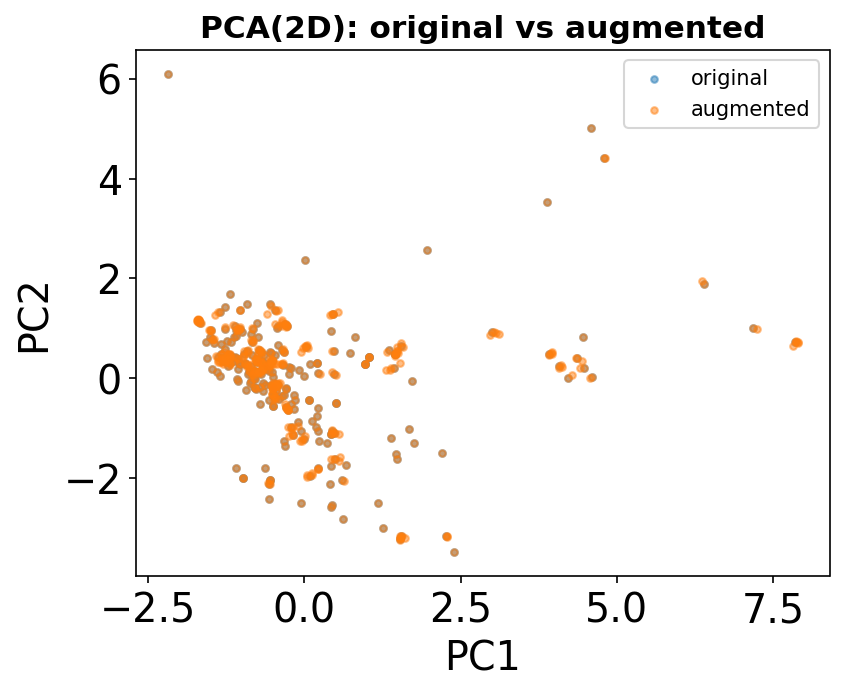

In [ ]:
# Numeric overlays
overlay_hists_per_numeric(X_orig, X_train_aug)

# Categorical comparisons (only if you have categorical columns)
bars_per_categorical(X_orig, X_train_aug)

# Target distribution
y_distribution(y_orig, Y_train_aug)

# 2D view of feature space
pca_scatter(X_orig, X_train_aug)



Explained variance ratio (PC1, PC2): [0.23424161 0.15072138]


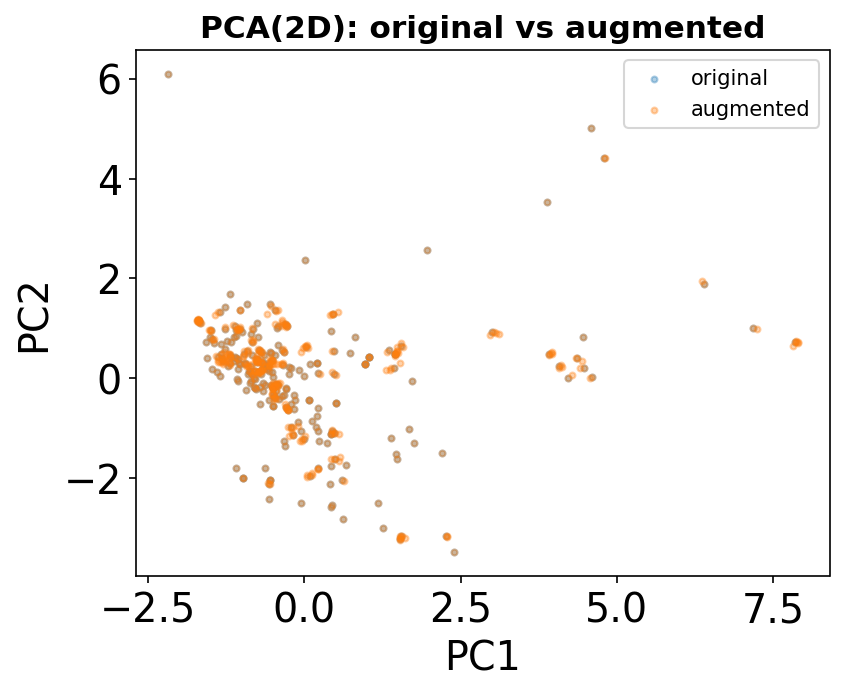

NN distance aug→orig: median=0.022, 95th=0.145
  feature  mean_orig   std_orig   mean_aug    std_aug     Δmean      Δstd
0    Type   1.752174   0.489514   1.751951   0.497930 -0.000223  0.008416
1      TS   0.708696   0.492222   0.675544   0.554043 -0.033152  0.061822
2      HD   4.568910   0.851282   4.573849   0.945734  0.004939  0.094452
3    Zeta  13.917217  21.779822  14.862253  17.954543  0.945036 -3.825279
4  Charge   0.434783   0.725462   0.419987   0.685466 -0.014796 -0.039996
5   Shape   4.643478   1.079312   4.742538   0.842083  0.099059 -0.237229
6      TM   1.678261   1.566839   1.811547   1.547679  0.133286 -0.019160
7      CT   5.013043   4.294284   5.209616   4.459426  0.196572  0.165142
8     TSz   0.240026   0.329534   0.260736   0.361629  0.020710  0.032096
9      TW   0.288391   0.391836   0.314901   0.433144  0.026510  0.041308


In [ ]:
X_aug=X_train
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

# numeric-only arrays (same as you used for PCA)
num_cols = X_orig.select_dtypes(include=[np.number]).columns.tolist()
A0 = X_orig[num_cols].apply(pd.to_numeric, errors="coerce").fillna(0.0).to_numpy()
A1 = X_aug[num_cols].apply(pd.to_numeric, errors="coerce").fillna(0.0).to_numpy()

# standardize on original, project to 2D for nice overlays + variance explained
scaler = StandardScaler().fit(A0)
A0z, A1z = scaler.transform(A0), scaler.transform(A1)
pca = PCA(n_components=2, random_state=0).fit(A0z)
print("Explained variance ratio (PC1, PC2):", pca.explained_variance_ratio_)

# 1) density contours over scatter (helps see if aug thickens tails)
P0, P1 = pca.transform(A0z), pca.transform(A1z)
plt.figure(figsize=(6,5))
plt.scatter(P0[:,0], P0[:,1], s=8, alpha=0.35, label="original")
plt.scatter(P1[:,0], P1[:,1], s=8, alpha=0.35, label="augmented")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("PCA(2D): original vs augmented"); plt.legend()
plt.tight_layout(); plt.show()

# 2) nearest-neighbor overlap: how far augmented points are from original cloud
nbrs = NearestNeighbors(n_neighbors=1).fit(A0z)
d_aug_to_orig = nbrs.kneighbors(A1z, return_distance=True)[0].ravel()
print(f"NN distance aug→orig: median={np.median(d_aug_to_orig):.3f}, 95th={np.percentile(d_aug_to_orig,95):.3f}")

# 3) per-feature drift table (mean/std shift)
def mean_std(x): return np.mean(x), np.std(x, ddof=1)
rows = []
for c in num_cols:
    a = pd.to_numeric(X_orig[c], errors="coerce").dropna().to_numpy()
    b = pd.to_numeric(X_aug[c],  errors="coerce").dropna().to_numpy()
    if len(a)>1 and len(b)>1:
        ma, sa = mean_std(a); mb, sb = mean_std(b)
        rows.append([c, ma, sa, mb, sb, mb-ma, sb-sa])
df_drift = pd.DataFrame(rows, columns=["feature","mean_orig","std_orig","mean_aug","std_aug","Δmean","Δstd"])
print(df_drift.head(12))


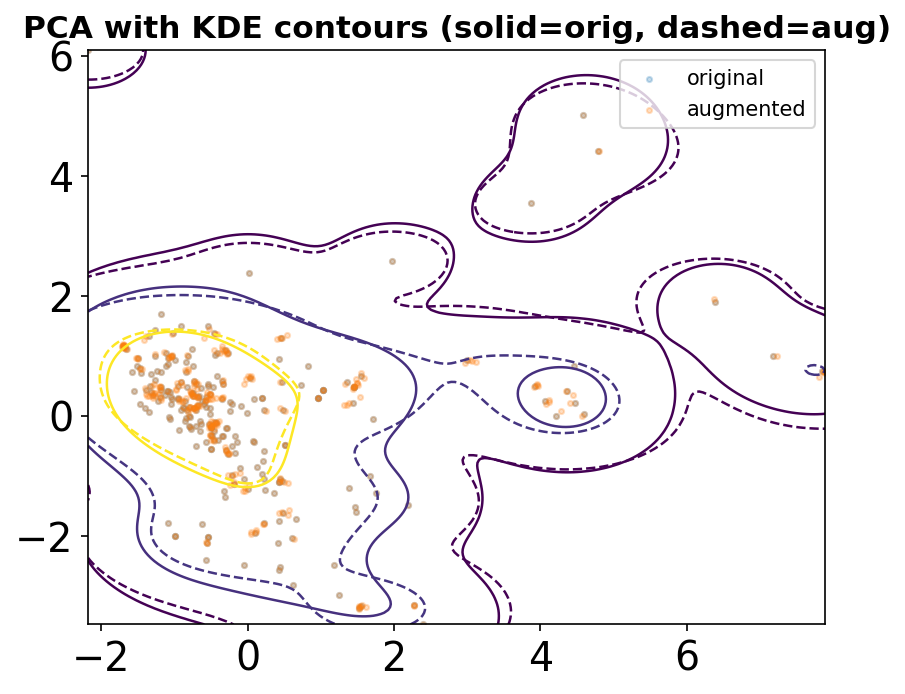

In [ ]:
from scipy.stats import gaussian_kde

def kde_contour(points, levels=(0.5, 0.8, 0.95), gridsize=200):
    x, y = points[:,0], points[:,1]
    xx, yy = np.meshgrid(np.linspace(x.min(), x.max(), gridsize),
                         np.linspace(y.min(), y.max(), gridsize))
    kde = gaussian_kde(np.vstack([x, y]))
    zz = kde(np.vstack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    return xx, yy, zz

xx, yy, z0 = kde_contour(P0)
xx, yy, z1 = kde_contour(P1)

plt.figure(figsize=(6,5))
plt.contour(xx, yy, z0, levels=np.quantile(z0, [0.5, 0.8, 0.95]), linestyles="solid", linewidths=1.2)
plt.contour(xx, yy, z1, levels=np.quantile(z1, [0.5, 0.8, 0.95]), linestyles="dashed", linewidths=1.2)
plt.scatter(P0[:,0], P0[:,1], s=6, alpha=0.25, label="original")
plt.scatter(P1[:,0], P1[:,1], s=6, alpha=0.25, label="augmented")
plt.legend(); plt.title("PCA with KDE contours (solid=orig, dashed=aug)"); plt.tight_layout(); plt.show()


In [ ]:
#to run the model we will recall the follows:
X_train = X_train_aug
Y_train = Y_train_aug

In [ ]:
# --- Scale X (features) using TRAIN only ---
X_scaler = StandardScaler().fit(X_train)
X_train_std = pd.DataFrame(X_scaler.transform(X_train),
                           columns=X.columns)
X_test_std  = pd.DataFrame(X_scaler.transform(X_test),
                           columns=X.columns)

# --- Scale Y (target) -- regression only ---
# y_scaler = StandardScaler().fit(Y_train.values.reshape(-1, 1))
# Y_train_std = y_scaler.transform(Y_train.values.reshape(-1, 1)).ravel()
# Y_test_std  = y_scaler.transform(Y_test.values.reshape(-1, 1)).ravel()

y_scaler = StandardScaler().fit(Y_train.values.reshape(-1, 1))
Y_train_std = y_scaler.transform(Y_train.values.reshape(-1, 1)).ravel()
Y_test_std  = y_scaler.transform(Y_test.values.reshape(-1, 1)).ravel()

In [ ]:
X_train=X_train_std
X_test=X_test_std
Y_train=Y_train_std
Y_test=Y_test_std

In [ ]:
#define the root mean squared error
def rmse(score):
    rmse = np.sqrt(-score)
    print(f'rmse= {"{:.2f}".format(rmse)}')

In [ ]:
from sklearn.model_selection import train_test_split
#X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.1, random_state=42)

In [ ]:
from sklearn.model_selection import KFold

# KFold with shuffle=True and fixed random_state ensures reproducible
# GridSearchCV results across runs — prevents XGBoost/RF ranking from
# changing between executions due to different fold assignments
kf = KFold(n_splits=5, shuffle=True, random_state=42)


 Lasso หลังจากที่ tune แล้ว บน cross-validation และ test set

In [ ]:
from sklearn.ensemble import BaggingRegressor

In [ ]:
# Linear Regression: no hyperparameters to tune via GridSearchCV
lr_grid = LinearRegression(n_jobs=-1)


In [ ]:
linearbag = BaggingRegressor(estimator=lr_grid, random_state=42)
linearbag.fit(X_train, Y_train)
print('linear bagging regressor (training score)', linearbag.score(X_train, Y_train))
print('linear bagging regressor (testing score)',  linearbag.score(X_test, Y_test))


linear bagging regressor (training score) 0.20048021538738725
linear bagging regressor (testing score) 0.16845083564112784


In [ ]:
ylinear_pred = linearbag.predict(X_test)
MAE_linear=mean_absolute_error(Y_test,ylinear_pred)
MSE_linear=mean_squared_error(Y_test,ylinear_pred)
RMSE_linear= math.sqrt(MSE_linear)
print("MAE _linearbag:",MAE_linear)
print("MSE_linearbag:", MSE_linear)
print("RMSE_linearbag:",RMSE_linear)

MAE _linearbag: 0.5894280294811902
MSE_linearbag: 0.5618637231357654
RMSE_linearbag: 0.7495756954009151


In [ ]:
tree = DecisionTreeRegressor(random_state=42)

# Narrow grid: tune tree structure parameters only
tree_params = {'max_depth'       : range(1, 10),
               'min_samples_leaf': [1, 3, 5, 10]}

tree_grid = GridSearchCV(tree, tree_params,
                          cv=kf, n_jobs=-1, verbose=False)
tree_grid.fit(X_train, Y_train)
print("Best params:", tree_grid.best_params_)
print("Best CV R²:", round(tree_grid.best_score_, 4))


Best params: {'max_depth': 8, 'min_samples_leaf': 3}
Best CV R²: 0.3521


In [ ]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# After: tree_grid.fit(X_train, Y_train)
print("Best params:", tree_grid.best_params_)
print("Best CV score (mean val R^2):", tree_grid.best_score_)

# Evaluate on the test set
best_tree = tree_grid.best_estimator_
y_pred = best_tree.predict(X_test)

r2   = r2_score(Y_test, y_pred)
mse = mean_squared_error(Y_test, y_pred)
rmse = np.sqrt(mse)
mae  = mean_absolute_error(Y_test, y_pred)

print(f"Test R^2:  {r2:.4f}")
print(f"Test RMSE: {rmse:.4f}")
print(f"Test MAE:  {mae:.4f}")

Best params: {'max_depth': 8, 'min_samples_leaf': 3}
Best CV score (mean val R^2): 0.35212488084388527
Test R^2:  0.1976
Test RMSE: 0.7363
Test MAE:  0.4348


In [ ]:
scores = cross_val_score(tree_grid, X_train, Y_train, cv = kf)
scores

array([ 0.57140309, -0.102676  , -0.04552166,  0.30514967,  0.22793157])

In [ ]:
np.mean(scores)

np.float64(0.19125733270670947)

In [ ]:
# Step 2: BaggingRegressor with best_estimator_ from GridSearchCV
treebag = BaggingRegressor(estimator=tree_grid.best_estimator_, random_state=42)
treebag.fit(X_train, Y_train)
print('tree bagging regressor (training score)', treebag.score(X_train, Y_train))
print('tree bagging regressor (testing score)',  treebag.score(X_test, Y_test))


tree bagging regressor (training score) 0.7596301976465125
tree bagging regressor (testing score) 0.42054051515923074


In [ ]:
# Importing the function
import math
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
ytree_pred = treebag.predict(X_test)
MAE_tree=mean_absolute_error(Y_test,ytree_pred)
MSE_tree=mean_squared_error(Y_test,ytree_pred)
RMSE_tree= math.sqrt(MSE_tree)
print("MAE _treebag:",MAE_tree)
print("MSE_tree:", MSE_tree)
print("RMSE_treebag:",RMSE_tree)

MAE _treebag: 0.3769143295694277
MSE_tree: 0.3915309851943494
RMSE_treebag: 0.6257243683878305


In [ ]:
forest = RandomForestRegressor(random_state=42)

# Narrow grid: tune tree structure (no n_estimators — redundant with BaggingRegressor)
forest_params = {'max_depth'        : [3, 5, 10, None],
                 'min_samples_split': [2, 5, 10],
                 'max_features'     : ['sqrt', 'log2']}

forest_grid = GridSearchCV(forest, forest_params,
                            cv=kf, n_jobs=-1, verbose=False)
forest_grid.fit(X_train, Y_train)
print("Best params:", forest_grid.best_params_)
print("Best CV R²:", round(forest_grid.best_score_, 4))


Best params: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 2}
Best CV R²: 0.6143


In [ ]:
# Step 2: BaggingRegressor with best_estimator_ from GridSearchCV
forestbag = BaggingRegressor(estimator=forest_grid.best_estimator_, random_state=42)
forestbag.fit(X_train, Y_train)
print('forest bagging regressor (training score)', forestbag.score(X_train, Y_train))
print('forest bagging regressor (testing score)',  forestbag.score(X_test, Y_test))


forest bagging regressor (training score) 0.82845898055356
forest bagging regressor (testing score) 0.6323491586301502


In [ ]:
yforest_pred = forestbag.predict(X_test)
MAE_forest=mean_absolute_error(Y_test,yforest_pred)
MSE_forest=mean_squared_error(Y_test,yforest_pred)
RMSE_forest= math.sqrt(MSE_forest)
print("MAE _knnbag:",MAE_forest)
print("MSE_knnbag:", MSE_forest)
print("RMSE_knnbag:",RMSE_forest)

MAE _knnbag: 0.35022143514053544
MSE_knnbag: 0.2484154628491829
RMSE_knnbag: 0.49841294410276193


In [ ]:
# X is already StandardScaled (see §StandardScaler above).
# A Pipeline with StandardScaler would double-scale → distort KNN distances.
# We tune n_neighbors and weights directly on scaled X_train.
knn_params = {'n_neighbors': range(1, 20),
              'weights'     : ['uniform', 'distance']}
knn_grid = GridSearchCV(KNeighborsRegressor(n_jobs=-1),
                        knn_params, cv=kf, n_jobs=-1, verbose=False)
knn_grid.fit(X_train, Y_train)
print("Best params:", knn_grid.best_params_)
print("Best CV score (R²):", round(knn_grid.best_score_, 4))


Best params: {'n_neighbors': 3, 'weights': 'distance'}
Best CV score (R²): 0.8856


In [ ]:
# Step 2: BaggingRegressor with best_estimator_ from GridSearchCV
knnbag = BaggingRegressor(estimator=knn_grid.best_estimator_, random_state=42)
knnbag.fit(X_train, Y_train)
print('knn bagging regressor (training score)', knnbag.score(X_train, Y_train))
print('knn bagging regressor (testing score)',  knnbag.score(X_test, Y_test))


knn bagging regressor (training score) 0.9739611569120313
knn bagging regressor (testing score) 0.16231918211451024


In [ ]:
yknn_pred = knnbag.predict(X_test)
MAE_knn=mean_absolute_error(Y_test,yknn_pred)
MSE_knn=mean_squared_error(Y_test,yknn_pred)
RMSE_knn= math.sqrt(MSE_knn)
print("MAE _knnbag:",MAE_knn)
print("MSE_knnbag:", MSE_knn)
print("RMSE_knnbag:",RMSE_knn)

MAE _knnbag: 0.4397730944452213
MSE_knnbag: 0.5660067778426993
RMSE_knnbag: 0.7523342195079918


In [ ]:
xgb = XGBRegressor(random_state=42, verbosity=0)

# Narrow grid — 3 parameters only (no n_estimators/subsample/colsample_bytree)
# These are excluded because BaggingRegressor already does bootstrap resampling.
# Adding internal XGBoost subsampling creates redundant randomness and
# can cause XGBoost to underperform relative to Random Forest.
xgb_params = {'min_child_weight': np.arange(0.5, 5, 0.5),
              'max_depth'       : [2, 5, 10, 20],
              'gamma'           : [0, 2, 5, 10]}

xgb_grid = GridSearchCV(xgb, param_grid=xgb_params,
                         cv=kf, n_jobs=-1, verbose=False)
xgb_grid.fit(X_train, Y_train)
print("Best params:", xgb_grid.best_params_)
print("Best CV R²:", round(xgb_grid.best_score_, 4))


Best params: {'gamma': 0, 'max_depth': 5, 'min_child_weight': np.float64(3.5)}
Best CV R²: 0.7086


In [ ]:
# Step 2: BaggingRegressor with best_estimator_ from GridSearchCV
# The narrow grid (max_depth, min_child_weight, gamma) does not include
# subsampling parameters, so best_estimator_ will not cause redundant randomness
xgbbag = BaggingRegressor(estimator=xgb_grid.best_estimator_, random_state=42)
xgbbag.fit(X_train, Y_train)
print('xgb bagging regressor (training score)', xgbbag.score(X_train, Y_train))
print('xgb bagging regressor (testing score)',  xgbbag.score(X_test, Y_test))


xgb bagging regressor (training score) 0.9383444755106702
xgb bagging regressor (testing score) 0.6135839802348428


  feature  mean_abs_shap       std
0      TS       0.110819  0.019068
1  Charge       0.109328  0.028064
2     TSz       0.085687  0.021165
3    Type       0.081562  0.007399
4      TW       0.077480  0.015611
5      CT       0.075571  0.009396
6      HD       0.058433  0.009418
7      TM       0.051759  0.016020
8   Shape       0.049067  0.016704
9    Zeta       0.045341  0.010983


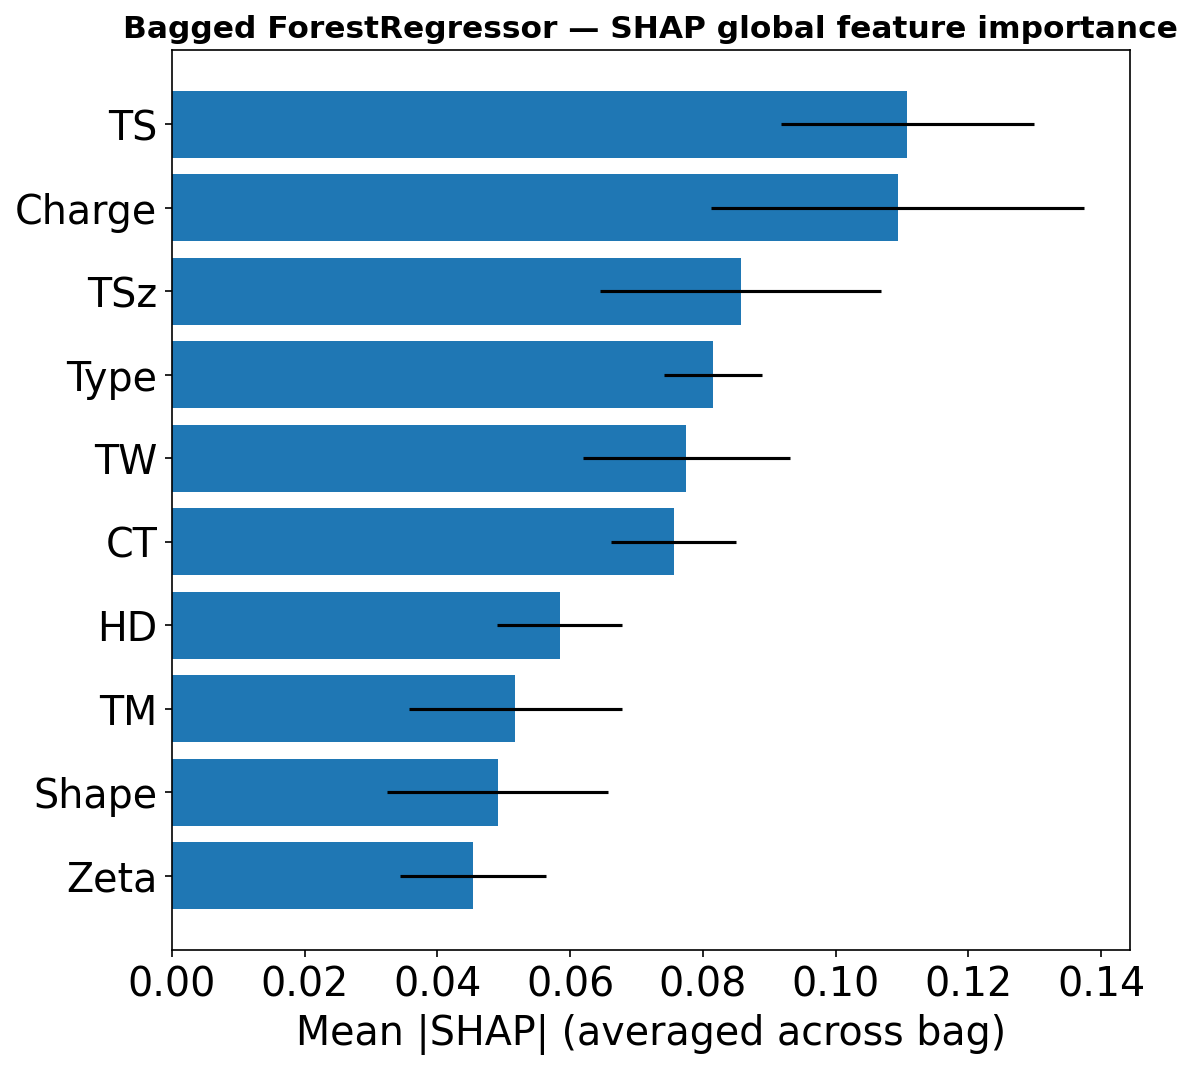

In [ ]:
# SHAP global importance for a BaggingRegressor of XGBRegressor
# (averages mean |SHAP| across estimators; also gives SD)

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

# 1) Feature names from X_test (preferred) or fallback
feat_names = X_test.columns.tolist() if hasattr(X_test, "columns") else [f"f{i}" for i in range(X_test.shape[1])]

def mean_abs_shap_for_estimator(est, X):
    """Return per-feature mean |SHAP| for one XGBRegressor."""
    try:
        expl = shap.TreeExplainer(est)
        sv = expl.shap_values(X, check_additivity=False)
    except Exception:
        # Fallback for newer/other SHAP versions
        expl = shap.Explainer(est)
        sv = expl(X).values

    # Regression -> array; multiclass -> list of arrays
    if isinstance(sv, list):
        # Sum absolute SHAP across outputs (classes)
        vals = np.sum([np.abs(v) for v in sv], axis=0)  # shape: (n_samples, n_features)
    else:
        vals = np.abs(sv)  # shape: (n_samples, n_features)

    return vals.mean(axis=0)  # (n_features,)

# 2) Aggregate across all bag members
per_est = [mean_abs_shap_for_estimator(est, X_test) for est in forestbag.estimators_]
per_est = np.vstack(per_est)  # (n_estimators, n_features)

mean_imp = per_est.mean(axis=0)
std_imp  = per_est.std(axis=0)

shap_df = (
    pd.DataFrame({"feature": feat_names, "mean_abs_shap": mean_imp, "std": std_imp})
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

print(shap_df.head(20))

# 3) (Optional) quick bar plot of top-k
topk = 10
plot_df = shap_df.head(topk).iloc[::-1]
plt.figure(figsize=(8, 0.6*topk + 1.5))
plt.barh(plot_df["feature"], plot_df["mean_abs_shap"], xerr=plot_df["std"])
plt.xlabel("Mean |SHAP| (averaged across bag)")
plt.title("Bagged ForestRegressor — SHAP global feature importance")
plt.tight_layout()
plt.show()


In [ ]:
yxgb_pred = xgbbag.predict(X_test)
MAE_xgb=mean_absolute_error(Y_test,yxgb_pred)
MSE_xgb=mean_squared_error(Y_test,yxgb_pred)
RMSE_xgb= math.sqrt(MSE_xgb)
print("MAE _xgbbag:",MAE_xgb)
print("MSE_xgbbag:", MSE_xgb)
print("RMSE_xgbbag:",RMSE_xgb)

MAE _xgbbag: 0.3432285484806723
MSE_xgbbag: 0.26109477689385907
RMSE_xgbbag: 0.510974340739199


In [ ]:
#Hyperparameter tuning
param_grid = {
    'hidden_layer_sizes': [(150,100,50), (120,80,40), (100,50,30)],
    'max_iter': [50, 100, 150],
    'activation': ['tanh', 'relu','adam'],
    'solver': ['sgd', 'adam'],
    'alpha': [0.0001, 0.05],
    'learning_rate': ['constant','adaptive'],
}

In [ ]:
# MLP hyperparameter tuning
# Note: 'activation' must be one of {'identity','logistic','tanh','relu'}
# 'adam' is a solver, not an activation function (removed from reference to fix bug)
from sklearn.neural_network import MLPRegressor

param_grid = {
    'hidden_layer_sizes': [(150, 100, 50), (120, 80, 40), (100, 50, 30)],
    'activation'        : ['tanh', 'relu'],
    'solver'            : ['sgd', 'adam'],
    'alpha'             : [0.0001, 0.05],
    'learning_rate'     : ['constant', 'adaptive'],
    'max_iter'          : [100, 200],
}


In [ ]:
from sklearn.neural_network import MLPRegressor

nn = MLPRegressor(random_state=42)
grid = GridSearchCV(nn, param_grid, n_jobs=-1, cv=kf)
grid.fit(X_train, Y_train)
print("Best params:", grid.best_params_)
print("Best CV score (R²):", round(grid.best_score_, 4))


Best params: {'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (150, 100, 50), 'learning_rate': 'constant', 'max_iter': 200, 'solver': 'adam'}
Best CV score (R²): 0.8786


In [ ]:
# Step 2: BaggingRegressor with best_estimator_ from MLP GridSearchCV
MLPbag = BaggingRegressor(estimator=grid.best_estimator_, random_state=42)
MLPbag.fit(X_train, Y_train)
print('MLP bagging regressor (training score)', MLPbag.score(X_train, Y_train))
print('MLP bagging regressor (testing score)',  MLPbag.score(X_test, Y_test))


MLP bagging regressor (training score) 0.9592711341582357
MLP bagging regressor (testing score) 0.14812025558132125


In [ ]:
ymlp_pred = MLPbag.predict(X_test)
MAE_mlp=mean_absolute_error(Y_test,ymlp_pred)
MSE_mlp=mean_squared_error(Y_test,ymlp_pred)
RMSE_mlp= math.sqrt(MSE_mlp)
print("MAE _MLPbag:",MAE_mlp)
print("MSE_MLPbag:", MSE_mlp)
print("RMSE_MLPbag:",RMSE_mlp)

MAE _MLPbag: 0.5281690274785394
MSE_MLPbag: 0.5756007526410741
RMSE_MLPbag: 0.7586835655535673


In [ ]:
# =========================================================
# HYPERPARAMETER OPTIMISATION SUMMARY
# =========================================================
import pandas as pd
import numpy as np

PARAM_GRID = {
    'Decision Tree'  : {'max_depth'        : list(range(1, 10)),
                        'min_samples_leaf' : [1, 3, 5, 10]},
    'Random Forest'  : {'max_depth'        : [3, 5, 10, None],
                        'min_samples_split': [2, 5, 10],
                        'max_features'     : ['sqrt', 'log2']},
    'KNN'            : {'n_neighbors'      : list(range(1, 20)),
                        'weights'          : ['uniform', 'distance']},
    'XGBoost'        : {'min_child_weight' : list(np.arange(0.5, 5, 0.5)),
                        'max_depth'        : [2, 5, 10, 20],
                        'gamma'            : [0, 2, 5, 10]},
    'MLP'            : {'hidden_layer_sizes': [(150,100,50),(120,80,40),(100,50,30)],
                        'activation'        : ['tanh','relu'],
                        'solver'            : ['sgd','adam'],
                        'alpha'             : [0.0001, 0.05],
                        'learning_rate'     : ['constant','adaptive'],
                        'max_iter'          : [100, 200]},
}

grid_objects = {
    'Decision Tree': tree_grid,
    'Random Forest': forest_grid,
    'KNN'          : knn_grid,
    'XGBoost'      : xgb_grid,
    'MLP'          : grid,
}

rows = []
for name, g in grid_objects.items():
    bp     = g.best_params_
    n_cand = len(g.cv_results_['params'])
    for param, values in PARAM_GRID[name].items():
        rows.append({
            'Model'           : name,
            'Hyperparameter'  : param,
            'Values searched' : str(values),
            'n values'        : len(values),
            'Optimized value' : bp.get(param, '—'),
        })

hp_df = pd.DataFrame(rows)
hp_df.to_csv('hyperparameter_summary.csv', index=False)

print("=" * 75)
print("  HYPERPARAMETER OPTIMISATION SUMMARY (GridSearchCV, 5-fold CV)")
print("=" * 75)
for model_name, grp in hp_df.groupby('Model', sort=False):
    n_cand = grid_objects[model_name].cv_results_['params'].__len__()
    cv_score = round(grid_objects[model_name].best_score_, 4)
    print(f"\n  {model_name}  ({n_cand} candidates | Best CV R² = {cv_score})")
    print(f"  {'Hyperparameter':<22} {'Values searched':<42} Optimized")
    print(f"  {'-'*72}")
    for _, row in grp.iterrows():
        print(f"  {row['Hyperparameter']:<22} "
              f"{str(row['Values searched']):<42} "
              f"{row['Optimized value']}")

print("\n" + "=" * 75)
print("Saved: hyperparameter_summary.csv")


  HYPERPARAMETER OPTIMISATION SUMMARY (GridSearchCV, 5-fold CV)

  Decision Tree  (36 candidates | Best CV R² = 0.3521)
  Hyperparameter         Values searched                            Optimized
  ------------------------------------------------------------------------
  max_depth              [1, 2, 3, 4, 5, 6, 7, 8, 9]                8
  min_samples_leaf       [1, 3, 5, 10]                              3

  Random Forest  (24 candidates | Best CV R² = 0.6143)
  Hyperparameter         Values searched                            Optimized
  ------------------------------------------------------------------------
  max_depth              [3, 5, 10, None]                           None
  min_samples_split      [2, 5, 10]                                 2
  max_features           ['sqrt', 'log2']                           sqrt

  KNN  (38 candidates | Best CV R² = 0.8856)
  Hyperparameter         Values searched                            Optimized
  ------------------------------------

Final bagging regressor performance (tuned hyperparameters):
            Model    Train     Test
    Random Forest 0.828459 0.632349
          XGBoost 0.938344 0.613584
    Decision Tree 0.759630 0.420541
Linear Regression 0.200480 0.168451
              MLP 0.959271 0.148120

XGB-bag feature importance (final tuned model):
Feature  Importance
     CT    1.043378
     TS    0.781506
 Charge    0.565898
   Zeta    0.555253
     TM    0.455250
   Type    0.392858
  Shape    0.371860
     HD    0.272612
     TW    0.269843
    TSz    0.257584

Final XGB-bag test performance (original DEmax units):
  R²   = 0.614
  MAE  = 2.372
  RMSE = 3.531


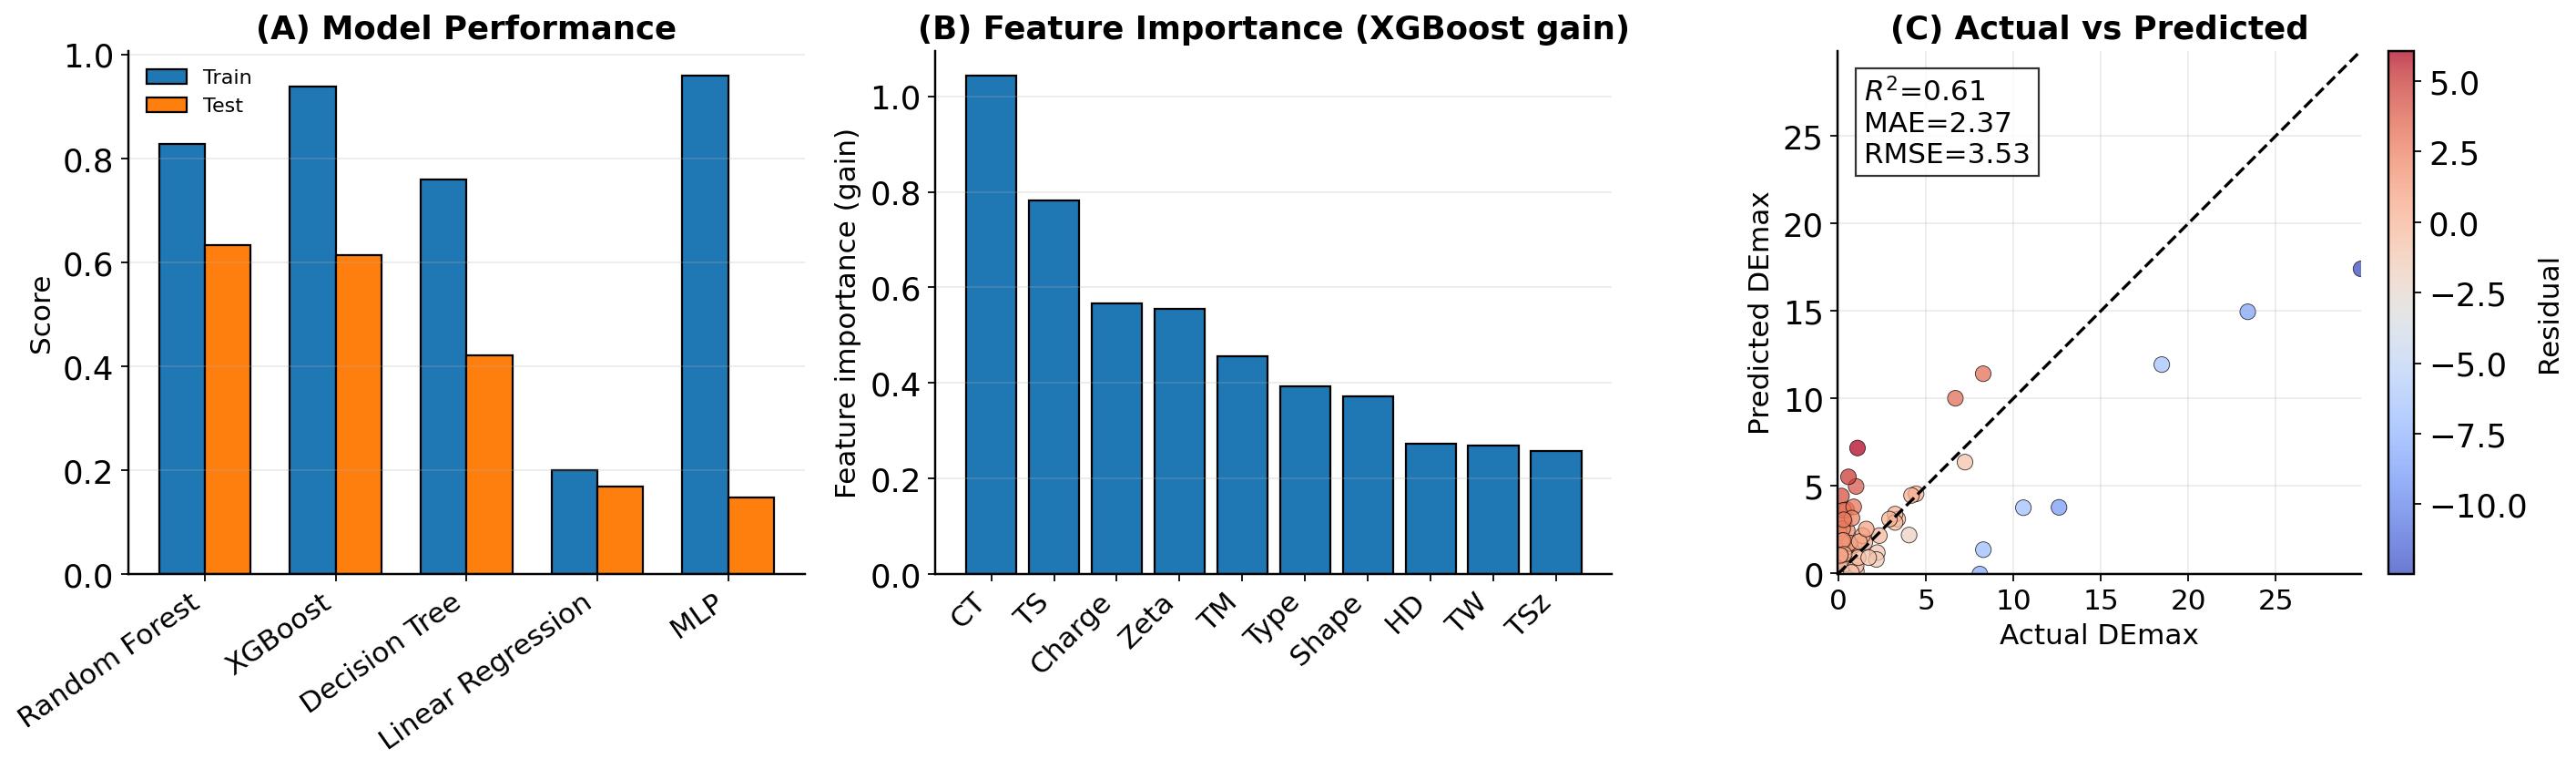

In [ ]:
# =========================================================
# FINAL BAGGING REGRESSOR PERFORMANCE (single-target, DEmax)
# — computed with the tuned hyperparameters from the
#   GridSearchCV summary above —
# Insert this cell right after "HYPERPARAMETER OPTIMISATION
# SUMMARY" and before "MAIN LOOP — all targets × all models".
#
# NOTE: at this point in the notebook, X_train/X_test/Y_train/
# Y_test have already been reassigned to their STANDARDIZED
# versions (see the cell with `X_train=X_train_std ... Y_test=
# Y_test_std`), which is what linearbag/treebag/forestbag/
# xgbbag/MLPbag were fit on. This cell inverse-transforms Y
# back to original DEmax units using the SAME y_scaler already
# fit earlier, so R²/MAE/RMSE below are on the real DEmax scale
# -- not the standardized one.
# =========================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# =========================================================
# MODEL PERFORMANCE (Train/Test R² -- scale-invariant, so this
# is valid whether computed on scaled or original Y; using the
# scaled X_train/Y_train/X_test/Y_test already in scope)
# =========================================================
models = {
    "Linear Regression": linearbag,
    "Decision Tree": treebag,
    "Random Forest": forestbag,
    "XGBoost": xgbbag,
    "MLP": MLPbag,
}

score_rows = []
for name, model in models.items():
    score_rows.append({
        "Model": name,
        "Train": model.score(X_train, Y_train),
        "Test": model.score(X_test, Y_test),
    })

score_df = pd.DataFrame(score_rows).sort_values("Test", ascending=False)
print("Final bagging regressor performance (tuned hyperparameters):")
print(score_df.to_string(index=False))

# =========================================================
# FEATURE IMPORTANCE (XGB-bag, averaged across bagged estimators)
# =========================================================
# fi = np.mean(
#     [est.feature_importances_ for est in xgbbag.estimators_],
#     axis=0
# )
fi = (pd.Series(xgb_grid.best_estimator_.get_booster().get_score(importance_type="gain"))               #####################
        .reindex(X_train.columns).fillna(0.0).values)  # single-booster gain (= Fig 5A/Table S7)        #####################
fi_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": fi,
}).sort_values("Importance", ascending=False)
top_imp = fi_df.head(10)
print("\nXGB-bag feature importance (final tuned model):")
print(fi_df.to_string(index=False))

# =========================================================
# ACTUAL VS PREDICTED — on ORIGINAL DEmax units
# (inline inverse-transform using the y_scaler already fit
# earlier on the pre-scaling Y_train; do NOT re-fit y_scaler
# here, or the inverse-transform will be wrong)
# =========================================================
y_pred_scaled = xgbbag.predict(X_test)

actual    = y_scaler.inverse_transform(
    np.asarray(Y_test).reshape(-1, 1)).ravel()
predicted = y_scaler.inverse_transform(
    np.asarray(y_pred_scaled).reshape(-1, 1)).ravel()
residuals = predicted - actual

r2   = r2_score(actual, predicted)
mae  = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print(f"\nFinal XGB-bag test performance (original DEmax units):")
print(f"  R²   = {r2:.3f}")
print(f"  MAE  = {mae:.3f}")
print(f"  RMSE = {rmse:.3f}")

lims = [min(actual.min(), predicted.min()), max(actual.max(), predicted.max())]

# =========================================================
# FIGURE (3 PANELS)
# =========================================================
plt.rcParams.update({
    "figure.dpi": 160, "savefig.dpi": 600,
    "font.family": "DejaVu Sans", "font.size": 14,
    "axes.titlesize": 16, "axes.labelsize": 14,
    "xtick.labelsize": 14, "ytick.labelsize": 16,
    "axes.linewidth": 1.1, "pdf.fonttype": 42,
})

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# (A) Model performance
ax1 = axes[0]
x = np.arange(len(score_df))
w = 0.35
ax1.bar(x - w/2, score_df["Train"], width=w, label="Train", edgecolor="black")
ax1.bar(x + w/2, score_df["Test"],  width=w, label="Test",  edgecolor="black")
ax1.set_xticks(x)
ax1.set_xticklabels(score_df["Model"], rotation=35, ha="right")
ax1.set_title("(A) Model Performance")
ax1.set_ylabel("Score")
ax1.legend(frameon=False)
ax1.grid(axis="y", alpha=0.25)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

# (B) Feature importance
ax2 = axes[1]
ax2.bar(np.arange(len(top_imp)), top_imp["Importance"], edgecolor="black")
ax2.set_xticks(np.arange(len(top_imp)))
ax2.set_xticklabels(top_imp["Feature"], rotation=45, ha="right")
ax2.set_title("(B) Feature Importance (XGBoost gain)")
ax2.set_ylabel("Feature importance (gain)")
ax2.grid(axis="y", alpha=0.25)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

# (C) Actual vs predicted (original DEmax units)
ax3 = axes[2]
sc = ax3.scatter(actual, predicted, c=residuals, cmap="coolwarm",
                  s=60, alpha=0.75, edgecolor="black", linewidth=0.4)
ax3.plot(lims, lims, "--", color="black")
ax3.set_xlim(lims); ax3.set_ylim(lims)
ax3.set_aspect("equal", adjustable="box")
ax3.set_title("(C) Actual vs Predicted")
ax3.set_xlabel("Actual DEmax")
ax3.set_ylabel("Predicted DEmax")
ax3.text(0.05, 0.95, f"$R^2$={r2:.2f}\nMAE={mae:.2f}\nRMSE={rmse:.2f}",
          transform=ax3.transAxes, va="top",
          bbox=dict(facecolor="white", edgecolor="black", alpha=0.8))
ax3.grid(alpha=0.25)
ax3.spines["top"].set_visible(False)
ax3.spines["right"].set_visible(False)
cbar = fig.colorbar(sc, ax=ax3, fraction=0.046, pad=0.04)
cbar.set_label("Residual")

plt.tight_layout()
plt.savefig("Fig_final_bagging_summary_3panel.png", bbox_inches="tight")
plt.savefig("Fig_final_bagging_summary_3panel.pdf", bbox_inches="tight")
plt.show()

Raw rows: 378
After dropna(): 288
After HD log-transform (dropping any HD<=0): 288

Train n=230, Test n=58
DE24   (col=DE24):  test R² = 0.693
DEt2   (col=DE168):  test R² = 0.558
DEmax  (col=Demax):  test R² = 0.684

Final AUC comparison (n=58):
  R² = 0.6303  MAE = 275.7701  RMSE = 397.1934
  Bias = 31.5345  LoA = [-751.2850, 814.3540]


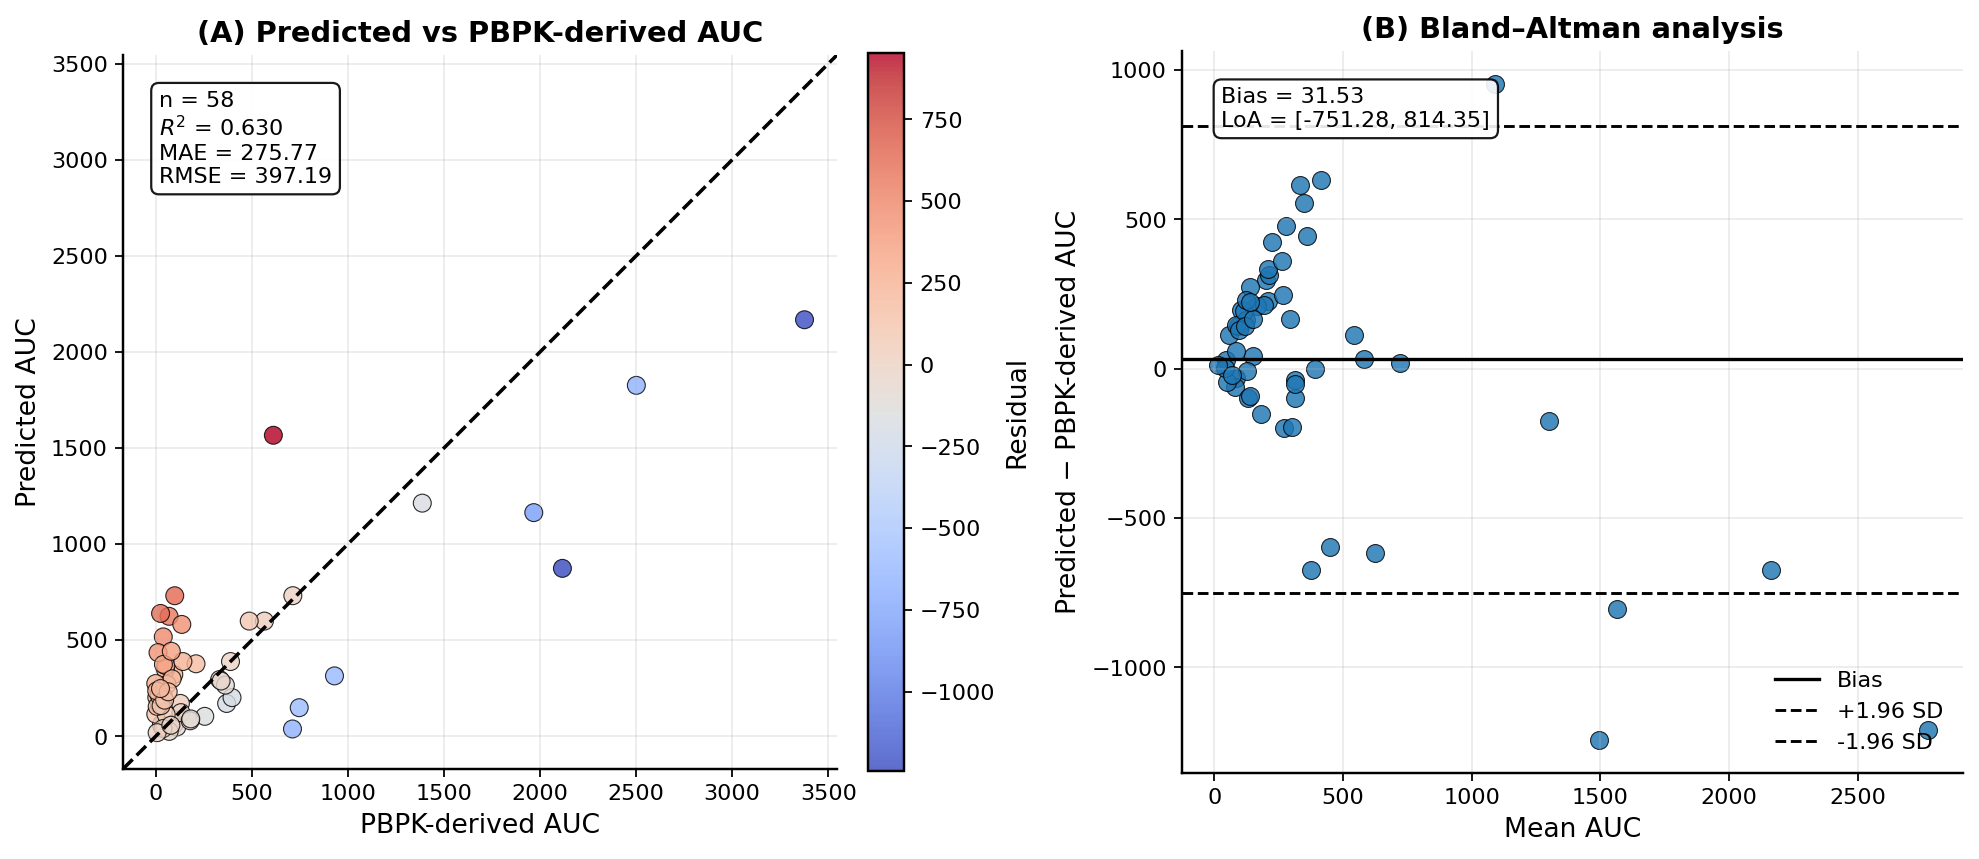


Saved: AUC_prediction_publication.png
Saved: AUC_prediction_publication.pdf


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import BaggingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# =========================================================
# CONFIG
# =========================================================
PATH = f"{DATA_DIR}/AI_nano.xlsx"
#df = pd.read_excel(f"{DATA_DIR}/AI_nano.xlsx")
EPS = 1e-9
EPS_SMALL = 1e-12
SEED = 42
HORIZON = 168.0  # matches "DE168" anchor; use 128.0 if your data uses DE128 instead

FEATURE_COLS = ["Type", "TS", "HD", "Zeta", "Charge", "Shape", "TM", "CT", "TSz", "TW"]
TARGET_COLS = {"DE24": "DE24", "DEt2": "DE168", "DEmax": "Demax"}

# tuned XGBoost hyperparameters (same as used for the multi-target bagging
# regressors elsewhere in this project -- gamma=0, max_depth=5, min_child_weight=4.5)
XGB_PARAMS = dict(gamma=0, max_depth=5, min_child_weight=4.5, random_state=SEED)

OUT_PNG = "AUC_prediction_publication.png"
OUT_PDF = "AUC_prediction_publication.pdf"

# =========================================================
# HELPERS
# =========================================================
def auc_piecewise(t_end, t_peak, de_max, k_decay, eps=1e-12):
    t_end = float(t_end)
    k = max(float(k_decay), eps)
    t_peak = max(float(t_peak), eps)
    de_max = max(float(de_max), eps)
    auc_rise = 0.5 * t_peak * de_max
    auc_decay = (de_max / k) * (1.0 - np.exp(-k * (t_end - t_peak)))
    return auc_rise + auc_decay


def auc_from_anchors(DE24, DEt2, DEmax, horizon):
    DE24 = np.asarray(DE24, dtype=float)
    DEt2 = np.asarray(DEt2, dtype=float)
    DEmax = np.asarray(DEmax, dtype=float)

    DE24 = np.maximum(DE24, EPS)
    DEt2 = np.maximum(DEt2, EPS)
    DEmax = np.maximum(DEmax, DE24)

    denom = max(float(horizon) - 24.0, EPS)
    k = (np.log(DE24) - np.log(DEt2)) / denom
    k = np.maximum(k, EPS_SMALL)

    t_peak = 24.0 - np.log(DEmax / DE24) / k
    t_peak = np.clip(t_peak, 0.0, float(horizon))

    auc = np.array([
        auc_piecewise(horizon, t_peak[i], DEmax[i], k[i], eps=EPS_SMALL)
        for i in range(len(DE24))
    ])
    return auc


def fit_predict_anchor(X_train, X_test, y_train, y_test):
    """Fit a bagged-XGBoost regressor for one PK anchor and return
    predictions + ground truth, both back on the ORIGINAL (unscaled) units."""
    x_scaler = StandardScaler().fit(X_train)
    X_train_s = pd.DataFrame(x_scaler.transform(X_train), columns=X_train.columns, index=X_train.index)
    X_test_s = pd.DataFrame(x_scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

    y_scaler = StandardScaler().fit(y_train.values.reshape(-1, 1))
    y_train_s = y_scaler.transform(y_train.values.reshape(-1, 1)).ravel()

    model = BaggingRegressor(estimator=XGBRegressor(**XGB_PARAMS), random_state=SEED)
    model.fit(X_train_s, y_train_s)

    pred_s = model.predict(X_test_s)
    pred = y_scaler.inverse_transform(pred_s.reshape(-1, 1)).ravel()

    return pred, y_test.values, model


# =========================================================
# LOAD + CLEAN DATA (matches the notebook's own pipeline exactly:
# full dropna() across all columns, THEN log-transform HD)
# =========================================================
df = pd.read_excel(PATH)
print("Raw rows:", len(df))

df = df.dropna().reset_index(drop=True)
print("After dropna():", len(df))

df["HD"] = np.where(df["HD"] > 0, np.log(df["HD"]), np.nan)
df = df.dropna(subset=["HD"]).reset_index(drop=True)
print("After HD log-transform (dropping any HD<=0):", len(df))

# =========================================================
# ENCODE CATEGORICAL FEATURES
# =========================================================
X_full = df[FEATURE_COLS].copy()
for col in X_full.select_dtypes(include=["object", "category"]).columns:
    X_full[col] = LabelEncoder().fit_transform(X_full[col].astype(str))

# =========================================================
# ONE SHARED TRAIN/TEST SPLIT -- so DE24/DE168/DEmax predictions for the
# test set all correspond to the SAME 58 nanoparticles, not three
# independently-shuffled splits
# =========================================================
idx_train, idx_test = train_test_split(
    df.index, test_size=0.2, random_state=SEED
)
X_train, X_test = X_full.loc[idx_train], X_full.loc[idx_test]
print(f"\nTrain n={len(idx_train)}, Test n={len(idx_test)}")

# =========================================================
# FIT ONE MODEL PER ANCHOR, PREDICT ON THE SAME TEST SET
# =========================================================
results = {}
for anchor_name, col in TARGET_COLS.items():
    y_train = df.loc[idx_train, col]
    y_test = df.loc[idx_test, col]
    pred, true, _ = fit_predict_anchor(X_train, X_test, y_train, y_test)
    results[anchor_name] = {"true": true, "pred": pred}
    print(f"{anchor_name:6s} (col={col}):  "
          f"test R\u00b2 = {r2_score(true, pred):.3f}")

# =========================================================
# COMPUTE AUC: experimental (true anchors) vs ML-predicted (predicted anchors)
# =========================================================
AUC_exp = auc_from_anchors(
    results["DE24"]["true"], results["DEt2"]["true"], results["DEmax"]["true"], HORIZON
)
AUC_pred = auc_from_anchors(
    results["DE24"]["pred"], results["DEt2"]["pred"], results["DEmax"]["pred"], HORIZON
)

mask = np.isfinite(AUC_exp) & np.isfinite(AUC_pred)
x = AUC_exp[mask]
y = AUC_pred[mask]

if len(x) == 0:
    raise ValueError("No valid rows for AUC comparison.")

residual = y - x
mean_auc = 0.5 * (x + y)

mae = mean_absolute_error(x, y)
rmse = np.sqrt(np.mean((y - x) ** 2))
r2 = r2_score(x, y) if len(x) >= 2 else np.nan

bias = residual.mean()
sd = residual.std(ddof=1) if len(residual) > 1 else 0.0
loa_upper = bias + 1.96 * sd
loa_lower = bias - 1.96 * sd

print(f"\nFinal AUC comparison (n={len(x)}):")
print(f"  R\u00b2 = {r2:.4f}  MAE = {mae:.4f}  RMSE = {rmse:.4f}")
print(f"  Bias = {bias:.4f}  LoA = [{loa_lower:.4f}, {loa_upper:.4f}]")

# =========================================================
# PUBLICATION STYLE
# =========================================================
plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 1.1,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# =========================================================
# TWO-PANEL FIGURE
# =========================================================
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.5))

# ---------------------------------------------------------
# PANEL A: Predicted vs Experimental AUC
# ---------------------------------------------------------
ax = axes[0]
sc = ax.scatter(x, y, c=residual, cmap="coolwarm", s=65, alpha=0.82,
                 edgecolor="black", linewidth=0.5)

lims = [min(x.min(), y.min()), max(x.max(), y.max())]
pad = 0.05 * (lims[1] - lims[0])
lims = [lims[0] - pad, lims[1] + pad]
ax.plot(lims, lims, "--", color="black", linewidth=1.6)

ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("PBPK-derived AUC")
ax.set_ylabel("Predicted AUC")
ax.set_title("(A) Predicted vs PBPK-derived AUC")

metric_text = (
    f"n = {len(x)}\n"
    f"$R^2$ = {r2:.3f}\n"
    f"MAE = {mae:.2f}\n"
    f"RMSE = {rmse:.2f}"
)
ax.text(0.05, 0.95, metric_text, transform=ax.transAxes, va="top", ha="left",
         fontsize=10, bbox=dict(boxstyle="round,pad=0.35", facecolor="white",
                                 edgecolor="black", alpha=0.9))

cbar = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Residual")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(alpha=0.25)

# ---------------------------------------------------------
# PANEL B: Bland-Altman Plot
# ---------------------------------------------------------
ax = axes[1]
ax.scatter(mean_auc, residual, s=65, alpha=0.82, edgecolor="black", linewidth=0.5)
ax.axhline(bias, color="black", linewidth=1.5, label="Bias")
ax.axhline(loa_upper, color="black", linestyle="--", linewidth=1.3, label="+1.96 SD")
ax.axhline(loa_lower, color="black", linestyle="--", linewidth=1.3, label="-1.96 SD")

ax.set_xlabel("Mean AUC")
ax.set_ylabel("Predicted \u2212 PBPK-derived AUC")
ax.set_title("(B) Bland\u2013Altman analysis")

ax.text(0.05, 0.95, f"Bias = {bias:.2f}\nLoA = [{loa_lower:.2f}, {loa_upper:.2f}]",
         transform=ax.transAxes, va="top", ha="left", fontsize=10,
         bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor="black", alpha=0.9))
ax.legend(frameon=False, loc="lower right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(alpha=0.25)

# =========================================================
# SAVE
# =========================================================
plt.tight_layout()
plt.savefig(OUT_PNG, bbox_inches="tight")
plt.savefig(OUT_PDF, bbox_inches="tight")
plt.show()

print(f"\nSaved: {OUT_PNG}")
print(f"Saved: {OUT_PDF}")

---
## Multi-Target Evaluation — Table 2

Train all ML models on each PBPK target variable:
- **KTRESrelease** (KTRES_rel) — release rate constant
- **KTRESn** (KTRES_n) — Hill coefficient
- **KTRESmax** (KTRES_max) — maximum release
- **KTRES50** (KTRES_50) — half-maximal concentration
- **Demax** (DEmax) — maximum cellular uptake
- **DE24** (DE24) — delivery efficiency at 24 h
- **DE168** (DE_t2) — delivery efficiency at 168 h

For each target × model: Test R², Test RMSE, CV R² (mean ± SD), CV RMSE


In [ ]:
# =========================================================
# MULTI-TARGET PIPELINE — TABLE 2
# =========================================================
import warnings, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, BaggingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
warnings.filterwarnings('ignore')

# ── Target columns (verified against AI_nano.xlsx) ────────────
TARGET_COLS = {
    'KTRES_rel' : 'KTRESrelease',   # release rate constant (0–14)
    'KTRES_n'   : 'KTRESn',         # Hill coefficient (0.01–10)
    'KTRES_max' : 'KTRESmax',       # maximum release (0.001–25)
    'KTRES_50'  : 'KTRES50',        # half-maximal concentration (0–180)
    'DEmax'     : 'Demax',          # max cellular uptake % (0.008–56.89)
    'DE24'      : 'DE24',           # delivery efficiency at 24h
    'DE_t2'     : 'DE168',          # delivery efficiency at 168h
}

print("Targets verified in AI_nano.xlsx:")
for k,v in TARGET_COLS.items():
    s = df[v]
    print(f"  {k:<12} ({v:<14}) "
          f"n={s.notna().sum()}  range=[{s.min():.3f}, {s.max():.3f}]  "
          f"mean={s.mean():.3f}  std={s.std():.3f}")


Targets verified in AI_nano.xlsx:
  KTRES_rel    (KTRESrelease  ) n=288  range=[0.001, 14.000]  mean=1.114  std=2.194
  KTRES_n      (KTRESn        ) n=288  range=[0.010, 10.000]  mean=2.557  std=2.248
  KTRES_max    (KTRESmax      ) n=288  range=[0.001, 25.000]  mean=1.365  std=3.545
  KTRES_50     (KTRES50       ) n=288  range=[0.001, 180.000]  mean=26.740  std=34.139
  DEmax        (Demax         ) n=288  range=[0.008, 30.240]  mean=2.754  std=5.166
  DE24         (DE24          ) n=288  range=[0.008, 26.870]  mean=2.151  std=4.156
  DE_t2        (DE168         ) n=288  range=[0.003, 15.380]  mean=1.161  std=2.382


In [ ]:
# ── Feature set (verified against AI_nano.xlsx) ───────────────
# All 12 features: physicochemical + biological context
# Dose and BW added — both complete (n=378, no missing)
FEATURE_COLS = ["Type","TS","HD","Zeta","Charge","Shape",
                "TM","CT","TSz","TW","Dose","BW"]

def prepare_Xy(df, target_col, feature_cols):
    """
    Prepare X, y for a given target:
    - Drop rows with NaN in any feature or target
    - Log-transform HD (in-place)
    - LabelEncode categorical features
    Returns: X (DataFrame), y (Series)
    """
    cols = feature_cols + [target_col]
    df_clean = df[cols].dropna().reset_index(drop=True)

    X = df_clean[feature_cols].copy()
    y = df_clean[target_col].copy()

    # Log-transform HD
    if 'HD' in X.columns:
        X['HD'] = np.where(X['HD'] > 0, np.log(X['HD']), np.nan)
        mask = X['HD'].notna()
        X = X[mask].reset_index(drop=True)
        y = y[mask].reset_index(drop=True)

    # Label encode categorical columns
    for col in X.select_dtypes(include=['object','category']).columns:
        le = LabelEncoder()
        X[col] = le.fit_transform(X[col].astype(str))

    return X, y

# ── KFold ─────────────────────────────────────────────────────
kf_mt = KFold(n_splits=5, shuffle=True, random_state=42)

# Check data size after dropna
X_test_size, y_test_size = prepare_Xy(df, 'Demax', FEATURE_COLS)
print(f"Features: {FEATURE_COLS}")
print(f"n after dropna (Demax): {len(X_test_size)} rows")
print(f"(From {len(df)} raw rows — {len(df)-len(X_test_size)} dropped due to NaN in features)")


Features: ['Type', 'TS', 'HD', 'Zeta', 'Charge', 'Shape', 'TM', 'CT', 'TSz', 'TW', 'Dose', 'BW']
n after dropna (Demax): 288 rows
(From 288 raw rows — 0 dropped due to NaN in features)


In [ ]:
# ── Model definitions with validated hyperparameters ─────────
# Hyperparameters from GridSearchCV in the single-target pipeline above
# Applied consistently across all targets for fair comparison
def build_models():
    return {
        'Linear Regression': BaggingRegressor(
            estimator=LinearRegression(), random_state=42),
        'Random Forest'    : BaggingRegressor(
            estimator=RandomForestRegressor(
                max_depth=None, max_features='sqrt',
                min_samples_split=2, random_state=42),
            random_state=42),
        'KNN'              : BaggingRegressor(
            estimator=KNeighborsRegressor(
                n_neighbors=1, weights='uniform'),
            random_state=42),
        'XGBoost'          : BaggingRegressor(
            estimator=XGBRegressor(
                gamma=0, max_depth=5, min_child_weight=4.5,
                random_state=42, verbosity=0),
            random_state=42),
        'MLP'              : BaggingRegressor(
            estimator=MLPRegressor(
                hidden_layer_sizes=(150,100,50),
                activation='tanh', solver='sgd',
                alpha=0.0001, learning_rate='constant',
                max_iter=200, random_state=42),
            random_state=42),
    }

print("Models defined:")
for name in build_models():
    print(f"  - {name}")
print()
print("Note: XGBoost uses gamma=0, max_depth=5, min_child_weight=4.5")
print("      (validated parameters from GridSearchCV — narrow grid)")


Models defined:
  - Linear Regression
  - Random Forest
  - KNN
  - XGBoost
  - MLP

Note: XGBoost uses gamma=0, max_depth=5, min_child_weight=4.5
      (validated parameters from GridSearchCV — narrow grid)


In [ ]:
# =========================================================
# MAIN LOOP — all targets × all models
# =========================================================
all_results = []

for target_name, target_col in TARGET_COLS.items():
    print(f"\n{'='*65}")
    print(f"  Target: {target_name}  (column: {target_col})")
    print(f"{'='*65}")

    # 1. Prepare X, y
    X_t, y_t = prepare_Xy(df, target_col, FEATURE_COLS)
    n = len(X_t)
    print(f"  n = {n} rows after dropna + log-HD")

    # 2. Train / test split
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_t, y_t, test_size=0.2, random_state=42)

    # 3. Augment training data (tail-focused, 2×)
    X_tr_aug, y_tr_aug = augment_noise(
        X_tr, y_tr,
        aug_multiplier=2, noise_frac=0.03,
        cat_strategy='swap', random_state=42,
        tail='both', low_quantile=0.20, high_quantile=0.80,
        both_tail_weights=(0.4, 0.8))

    # 4. Scale X (fit on augmented train only)
    xs = StandardScaler().fit(X_tr_aug)
    X_tr_s = pd.DataFrame(xs.transform(X_tr_aug), columns=FEATURE_COLS)
    X_te_s = pd.DataFrame(xs.transform(X_te),     columns=FEATURE_COLS)

    # 5. Scale Y (fit on augmented train only)
    ys = StandardScaler().fit(y_tr_aug.values.reshape(-1,1))
    y_tr_s = ys.transform(y_tr_aug.values.reshape(-1,1)).ravel()
    y_te_s = ys.transform(y_te.values.reshape(-1,1)).ravel()

    # 6. Train each model
    print(f"  {'Model':<22} {'Test R²':>8} {'Test RMSE':>10} {'CV R²':>14} {'CV RMSE':>12}")
    print(f"  {'-'*68}")

    models = build_models()
    for model_name, model in models.items():
        try:
            # Train
            model.fit(X_tr_s, y_tr_s)

            # Test set (inverse-transform to original scale)
            y_pred   = ys.inverse_transform(
                model.predict(X_te_s).reshape(-1,1)).ravel()
            y_true   = ys.inverse_transform(
                y_te_s.reshape(-1,1)).ravel()

            test_r2   = r2_score(y_true, y_pred)
            test_rmse = np.sqrt(mean_squared_error(y_true, y_pred))

            # 5-fold CV on scaled train data
            cv_r2   = cross_val_score(
                model, X_tr_s, y_tr_s, cv=kf_mt, scoring='r2')
            cv_rmse_raw = cross_val_score(
                model, X_tr_s, y_tr_s, cv=kf_mt,
                scoring='neg_mean_squared_error')
            cv_rmse = np.sqrt(-cv_rmse_raw)

            cv_r2_str = f"{cv_r2.mean():.3f}±{cv_r2.std():.3f}"
            cv_rm_str = f"{cv_rmse.mean():.3f}±{cv_rmse.std():.3f}"

            print(f"  {model_name:<22} {test_r2:>8.3f} {test_rmse:>10.3f} "
                  f"{cv_r2_str:>14} {cv_rm_str:>12}")

            all_results.append({
                'Target'      : target_name,
                'Model'       : model_name,
                'n'           : n,
                'Test R²'     : round(test_r2,  4),
                'Test RMSE'   : round(test_rmse, 4),
                'CV R² mean'  : round(cv_r2.mean(),  4),
                'CV R² SD'    : round(cv_r2.std(),   4),
                'CV RMSE mean': round(cv_rmse.mean(), 4),
                'CV RMSE SD'  : round(cv_rmse.std(),  4),
            })

        except Exception as e:
            print(f"  {model_name:<22} ERROR: {e}")

results_df = pd.DataFrame(all_results)
results_df.to_csv('Table2_multitarget_results.csv', index=False)
print("\nSaved: Table2_multitarget_results.csv")



  Target: KTRES_rel  (column: KTRESrelease)
  n = 288 rows after dropna + log-HD
  Model                   Test R²  Test RMSE          CV R²      CV RMSE
  --------------------------------------------------------------------
  Linear Regression        -0.087      2.455    0.014±0.178  0.987±0.094
  Random Forest             0.260      2.026    0.577±0.060  0.645±0.029
  KNN                      -0.025      2.384    0.755±0.108  0.480±0.116
  XGBoost                   0.304      1.965    0.702±0.083  0.536±0.065
  MLP                       0.011      2.342    0.231±0.091  0.873±0.062

  Target: KTRES_n  (column: KTRESn)
  n = 288 rows after dropna + log-HD
  Model                   Test R²  Test RMSE          CV R²      CV RMSE
  --------------------------------------------------------------------
  Linear Regression        -0.720      2.337   -0.019±0.074  0.999±0.026
  Random Forest            -0.113      1.880    0.440±0.032  0.741±0.018
  KNN                      -0.709      2.329 

In [ ]:
# =========================================================
# TABLE 2 — Publication-ready summary
# =========================================================
print("\n" + "="*95)
print("  TABLE 2. Predictive Performance of ML Models across PBPK Target Variables")
print("  Metrics: Test set R² / RMSE  |  5-fold CV R² (mean±SD) / RMSE (mean±SD)")
print("="*95)
print(f"  {'Target':<12} {'Model':<22} {'Test R²':>8} {'Test RMSE':>10} "
      f"{'CV R² mean±SD':>16} {'CV RMSE mean±SD':>17}")
print(f"  {'-'*88}")

for target in TARGET_COLS.keys():
    sub = results_df[results_df['Target']==target].sort_values('Test R²',ascending=False)
    first = True
    for _, row in sub.iterrows():
        cv_r2_str   = f"{row['CV R² mean']:.3f}±{row['CV R² SD']:.3f}"
        cv_rmse_str = f"{row['CV RMSE mean']:.3f}±{row['CV RMSE SD']:.3f}"
        tgt = target if first else ''
        best_flag = ' ★' if first else ''
        print(f"  {tgt:<12} {row['Model']:<22}{best_flag} "
              f"{row['Test R²']:>8.3f} {row['Test RMSE']:>10.3f} "
              f"{cv_r2_str:>16} {cv_rmse_str:>17}")
        first = False
    print()

print("="*95)
print("★ = best model per target by Test R²")



  TABLE 2. Predictive Performance of ML Models across PBPK Target Variables
  Metrics: Test set R² / RMSE  |  5-fold CV R² (mean±SD) / RMSE (mean±SD)
  Target       Model                   Test R²  Test RMSE    CV R² mean±SD   CV RMSE mean±SD
  ----------------------------------------------------------------------------------------
  KTRES_rel    XGBoost                ★    0.304      1.965      0.702±0.083       0.536±0.065
               Random Forest             0.260      2.026      0.577±0.060       0.645±0.029
               MLP                       0.011      2.342      0.231±0.091       0.873±0.062
               KNN                      -0.025      2.385      0.755±0.108       0.480±0.116
               Linear Regression        -0.087      2.455      0.014±0.177       0.987±0.094

  KTRES_n      Random Forest          ★   -0.114      1.880      0.440±0.032       0.741±0.018
               XGBoost                  -0.129      1.893      0.543±0.059       0.667±0.022
         

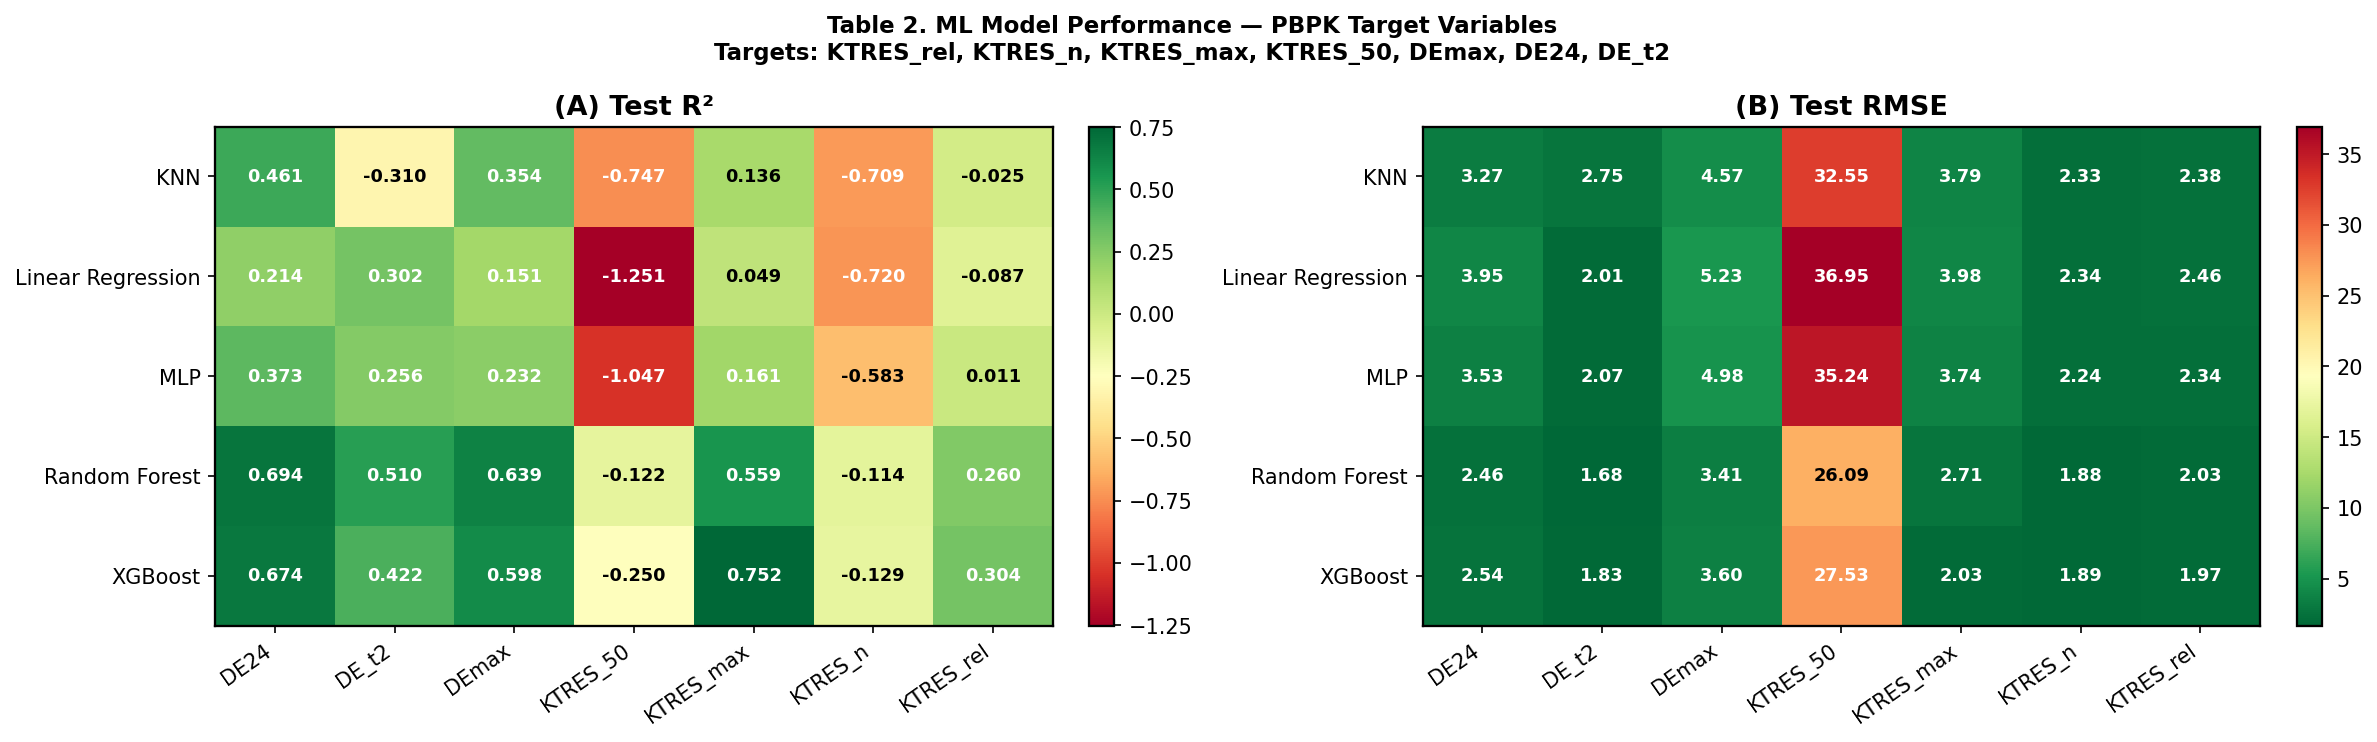


Best model per target (by Test R²):
  Target       Best Model              Test R²  Test RMSE            CV R²
  ------------------------------------------------------------------------
  KTRES_rel    XGBoost                   0.304      1.965      0.702±0.083
  KTRES_n      Random Forest            -0.114      1.880      0.440±0.032
  KTRES_max    XGBoost                   0.752      2.033      0.549±0.104
  KTRES_50     Random Forest            -0.122     26.087      0.525±0.065
  DEmax        Random Forest             0.639      3.413      0.514±0.165
  DE24         Random Forest             0.694      2.465      0.567±0.176
  DE_t2        Random Forest             0.510      1.681      0.476±0.241

Test R² range : -1.251 to 0.752
CV   R² range : -0.019 to 0.886

Saved: Fig_Table2_heatmap.png


In [ ]:
# =========================================================
# FIGURE — Heatmap of Test R² and Test RMSE
# =========================================================
mpl.rcParams.update({'figure.dpi':150,'savefig.dpi':300,
    'font.family':'DejaVu Sans','font.size':10})

pivot_r2   = results_df.pivot(index='Model', columns='Target', values='Test R²')
pivot_rmse = results_df.pivot(index='Model', columns='Target', values='Test RMSE')

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, data, title, cmap in [
    (axes[0], pivot_r2,   'Test R²',   'RdYlGn'),
    (axes[1], pivot_rmse, 'Test RMSE', 'RdYlGn_r'),
]:
    vals = data.values.astype(float)
    im = ax.imshow(vals, cmap=cmap, aspect='auto',
                   vmin=np.nanmin(vals), vmax=np.nanmax(vals))
    ax.set_xticks(range(len(data.columns)))
    ax.set_xticklabels(data.columns, rotation=35, ha='right', fontsize=10)
    ax.set_yticks(range(len(data.index)))
    ax.set_yticklabels(data.index, fontsize=10)
    panel = '(A)' if ax is axes[0] else '(B)'
    ax.set_title(f'{panel} {title}', fontweight='bold')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    for i in range(len(data.index)):
        for j in range(len(data.columns)):
            val = vals[i,j]
            if not np.isnan(val):
                fmt = '.3f' if 'R²' in title else '.2f'
                ax.text(j, i, f'{val:{fmt}}', ha='center', va='center',
                        fontsize=8.5, fontweight='bold',
                        color='black' if 0.3<(val-np.nanmin(vals))/(np.nanmax(vals)-np.nanmin(vals)+1e-9)<0.7 else 'white')

fig.suptitle('Table 2. ML Model Performance — PBPK Target Variables\n'
             'Targets: KTRES_rel, KTRES_n, KTRES_max, KTRES_50, DEmax, DE24, DE_t2',
             fontweight='bold', fontsize=11)
plt.tight_layout()
plt.savefig('Fig_Table2_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

# ── Best model per target ─────────────────────────────────────
print("\nBest model per target (by Test R²):")
print(f"  {'Target':<12} {'Best Model':<22} {'Test R²':>8} {'Test RMSE':>10} {'CV R²':>16}")
print(f"  {'-'*72}")
for target in TARGET_COLS.keys():
    sub = results_df[results_df['Target']==target]
    if sub.empty: continue
    best = sub.loc[sub['Test R²'].idxmax()]
    cv_str = f"{best['CV R² mean']:.3f}±{best['CV R² SD']:.3f}"
    print(f"  {target:<12} {best['Model']:<22} "
          f"{best['Test R²']:>8.3f} {best['Test RMSE']:>10.3f} {cv_str:>16}")

print()
r2_vals = results_df['Test R²']
cv_vals = results_df['CV R² mean']
print(f"Test R² range : {r2_vals.min():.3f} to {r2_vals.max():.3f}")
print(f"CV   R² range : {cv_vals.min():.3f} to {cv_vals.max():.3f}")
print("\nSaved: Fig_Table2_heatmap.png")


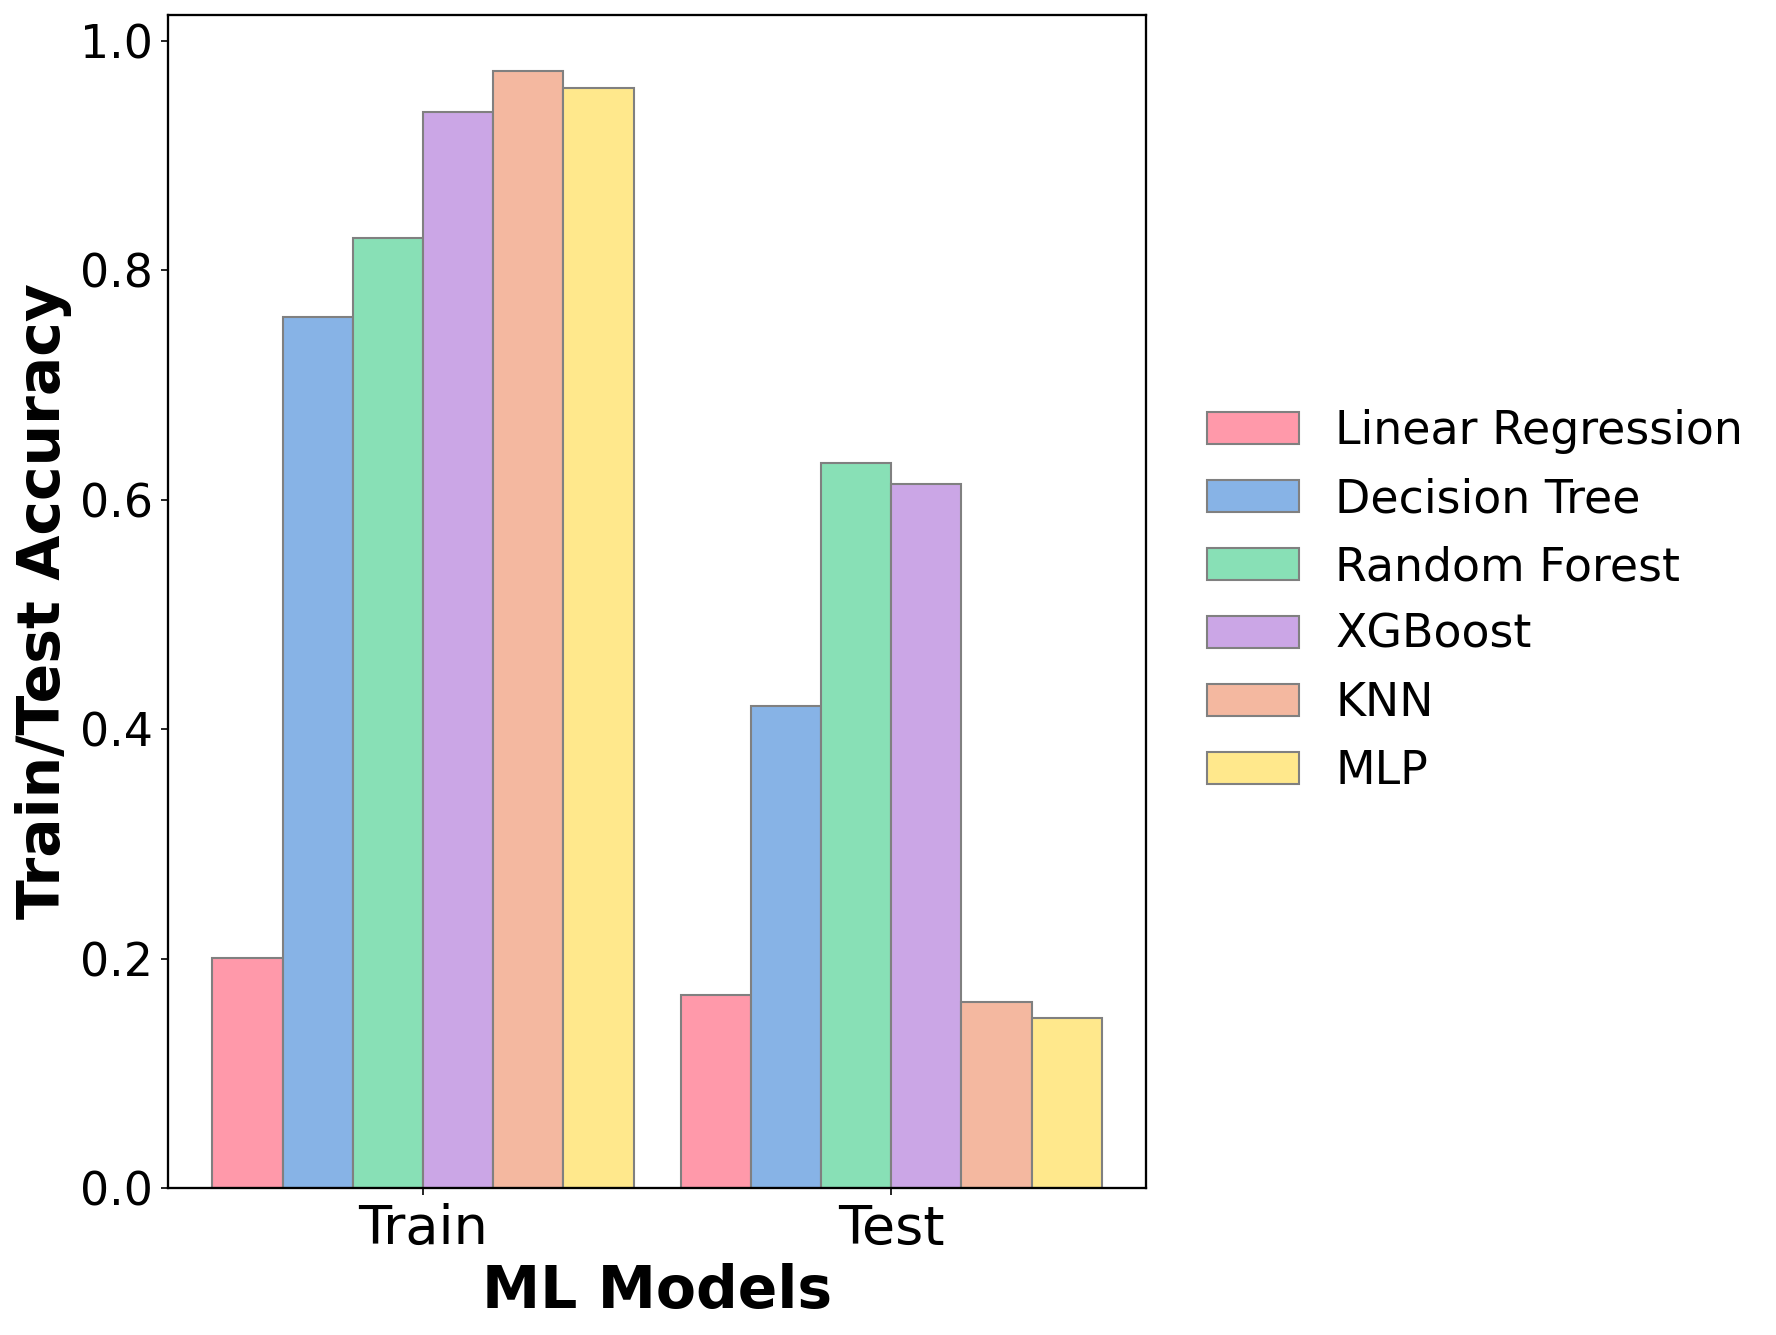

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Ensure we use the standardized variables that the bagging models were fit on
X_tr_eval = X_train_std
Y_tr_eval = Y_train_std
X_te_eval = X_test_std
Y_te_eval = Y_test_std

# set width of bar
barWidth = 0.15
fig, ax = plt.subplots(figsize=(12, 9))

# set height of bar using the correct standardized variables
Ln  = [linearbag.score(X_tr_eval, Y_tr_eval), linearbag.score(X_te_eval, Y_te_eval)]
DT  = [treebag.score(X_tr_eval, Y_tr_eval), treebag.score(X_te_eval, Y_te_eval)]
RF  = [forestbag.score(X_tr_eval, Y_tr_eval), forestbag.score(X_te_eval, Y_te_eval)]
XGB = [xgbbag.score(X_tr_eval, Y_tr_eval), xgbbag.score(X_te_eval, Y_te_eval)]
KNN = [knnbag.score(X_tr_eval, Y_tr_eval), knnbag.score(X_te_eval, Y_te_eval)]
MLP = [MLPbag.score(X_tr_eval, Y_tr_eval), MLPbag.score(X_te_eval, Y_te_eval)]

# Set position of bar on X axis
br1 = np.arange(len(Ln))
br2 = [x + barWidth for x in br1]
br3 = [x + barWidth for x in br2]
br4 = [x + barWidth for x in br3]
br5 = [x + barWidth for x in br4]
br6 = [x + barWidth for x in br5]

# Pastel colors
pastel_colors = {
    "Linear Regression": "#FF99AA",
    "Decision Tree":     "#87B3E6",
    "Random Forest":     "#88E0B6",
    "XGBoost":           "#CBA6E6",
    "KNN":               "#F4B8A0",
    "MLP":               "#FFE88C"
}

# Make the plot
ax.bar(br1, Ln, color=pastel_colors["Linear Regression"], width=barWidth,
       edgecolor='grey', label='Linear Regression')
ax.bar(br2, DT, color=pastel_colors["Decision Tree"], width=barWidth,
       edgecolor='grey', label='Decision Tree')
ax.bar(br3, RF, color=pastel_colors["Random Forest"], width=barWidth,
       edgecolor='grey', label='Random Forest')
ax.bar(br4, XGB, color=pastel_colors["XGBoost"], width=barWidth,
       edgecolor='grey', label='XGBoost')
ax.bar(br5, KNN, color=pastel_colors['KNN'], width=barWidth, edgecolor='grey', label='KNN')
ax.bar(br6, MLP, color=pastel_colors["MLP"], width=barWidth,
       edgecolor='grey', label='MLP')

# Center group labels
group_centers = [r + 2.5*barWidth for r in range(len(Ln))]
ax.set_xlabel('ML Models', fontweight='bold', fontsize=28)
ax.set_ylabel('Train/Test Accuracy', fontweight='bold', fontsize=28)
ax.set_xticks(group_centers)
ax.set_xticklabels(['Train', 'Test'], fontsize=26)
ax.tick_params(axis='y', labelsize=22)

# Move legend outside
ax.legend(frameon=False, fontsize=22, loc='center left', bbox_to_anchor=(1.02, 0.5))

plt.tight_layout()
plt.show()

In [ ]:
X_test.head(5)

,Type,TS,HD,Zeta,Charge,Shape,TM,CT,TSz,TW
45,1,0,3.974058,12.4,0.0,5,3,2,1.1,1.32
157,2,0,5.230574,29.5,0.0,5,4,0,0.1,0.12
256,2,1,4.919981,15.6,0.0,5,0,5,0.2,0.24
42,1,0,1.945910,3.0,0.0,5,4,11,0.2,0.24
181,2,1,4.605170,4.0,0.0,5,3,2,0.1,0.12


Text(0, 0.5, 'DEmax prediction')

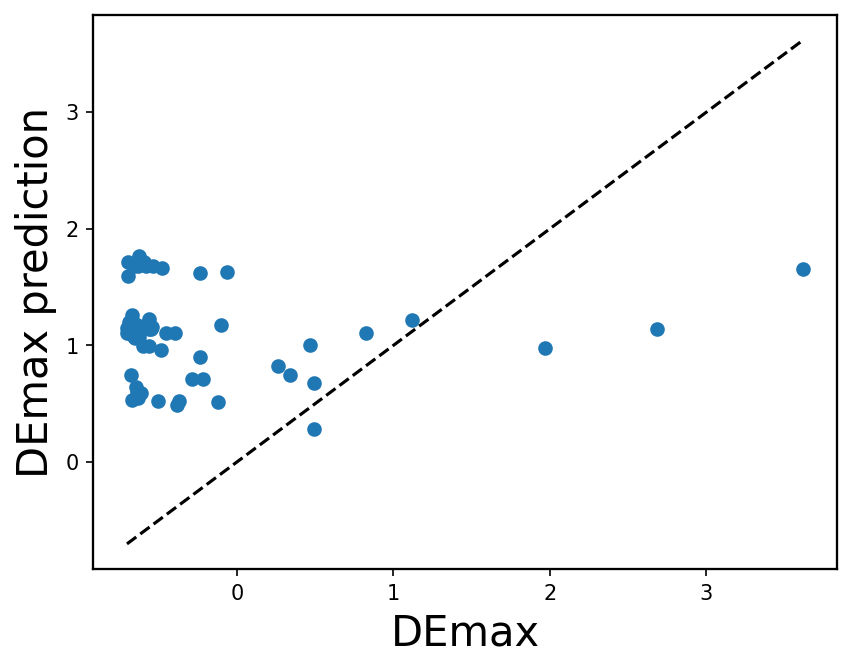

In [ ]:
y_pred = xgbbag.predict(X_test)
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], '--k')
plt.scatter(Y_test, y_pred)
plt.xlabel('DEmax', fontsize = 20)
plt.ylabel('DEmax prediction', fontsize = 20)

  feature  importance
7      CT    1.043378
1      TS    0.781506
4  Charge    0.565898
3    Zeta    0.555253
6      TM    0.455250
0    Type    0.392858
5   Shape    0.371860
2      HD    0.272612
9      TW    0.269843
8     TSz    0.257584


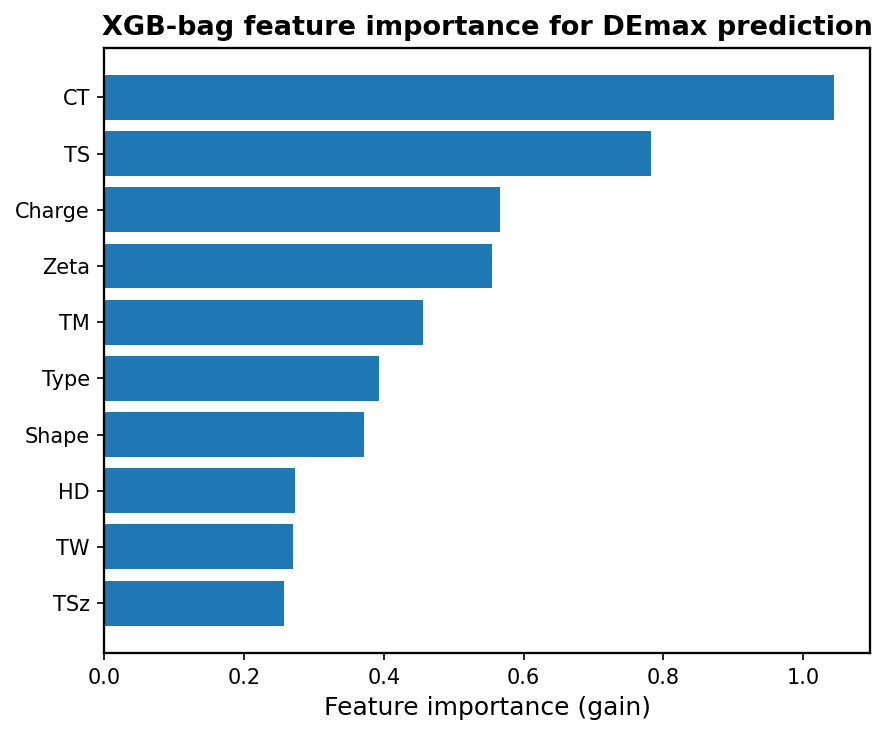

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- 1) Get feature importances from the bagged model ----
# Average over all base estimators in the bagging ensemble
fi = ((pd.Series(xgb_grid.best_estimator_.get_booster().get_score(importance_type="gain")).reindex(X_train.columns).fillna(0.0).values))

# Assume X_train is a DataFrame so we have column names
feature_names = np.array(X_train.columns)

# Put into a nice DataFrame and sort
fi_df = pd.DataFrame({
    "feature": feature_names,
    "importance": fi
}).sort_values("importance", ascending=False)

print(fi_df)

# ---- 2) Plot top k features ----
k = 10  # change if you want more/less
top = fi_df.head(k).iloc[::-1]   # reverse for nice horizontal plot

plt.figure(figsize=(6, 5))
plt.barh(top["feature"], top["importance"])
plt.xlabel("Feature importance (gain)")
plt.title("XGB-bag feature importance for DEmax prediction")
plt.tight_layout()
plt.show()


Model performance summary:
            Model  Train Score  Test Score
    Random Forest     0.828459    0.632349
          XGBoost     0.938344    0.613584
    Decision Tree     0.759630    0.420541
Linear Regression     0.200480    0.168451
              MLP     0.959271    0.148120

XGB-bag feature importance:
Feature  Importance
     CT    1.043378
     TS    0.781506
 Charge    0.565898
   Zeta    0.555253
     TM    0.455250
   Type    0.392858
  Shape    0.371860
     HD    0.272612
     TW    0.269843
    TSz    0.257584


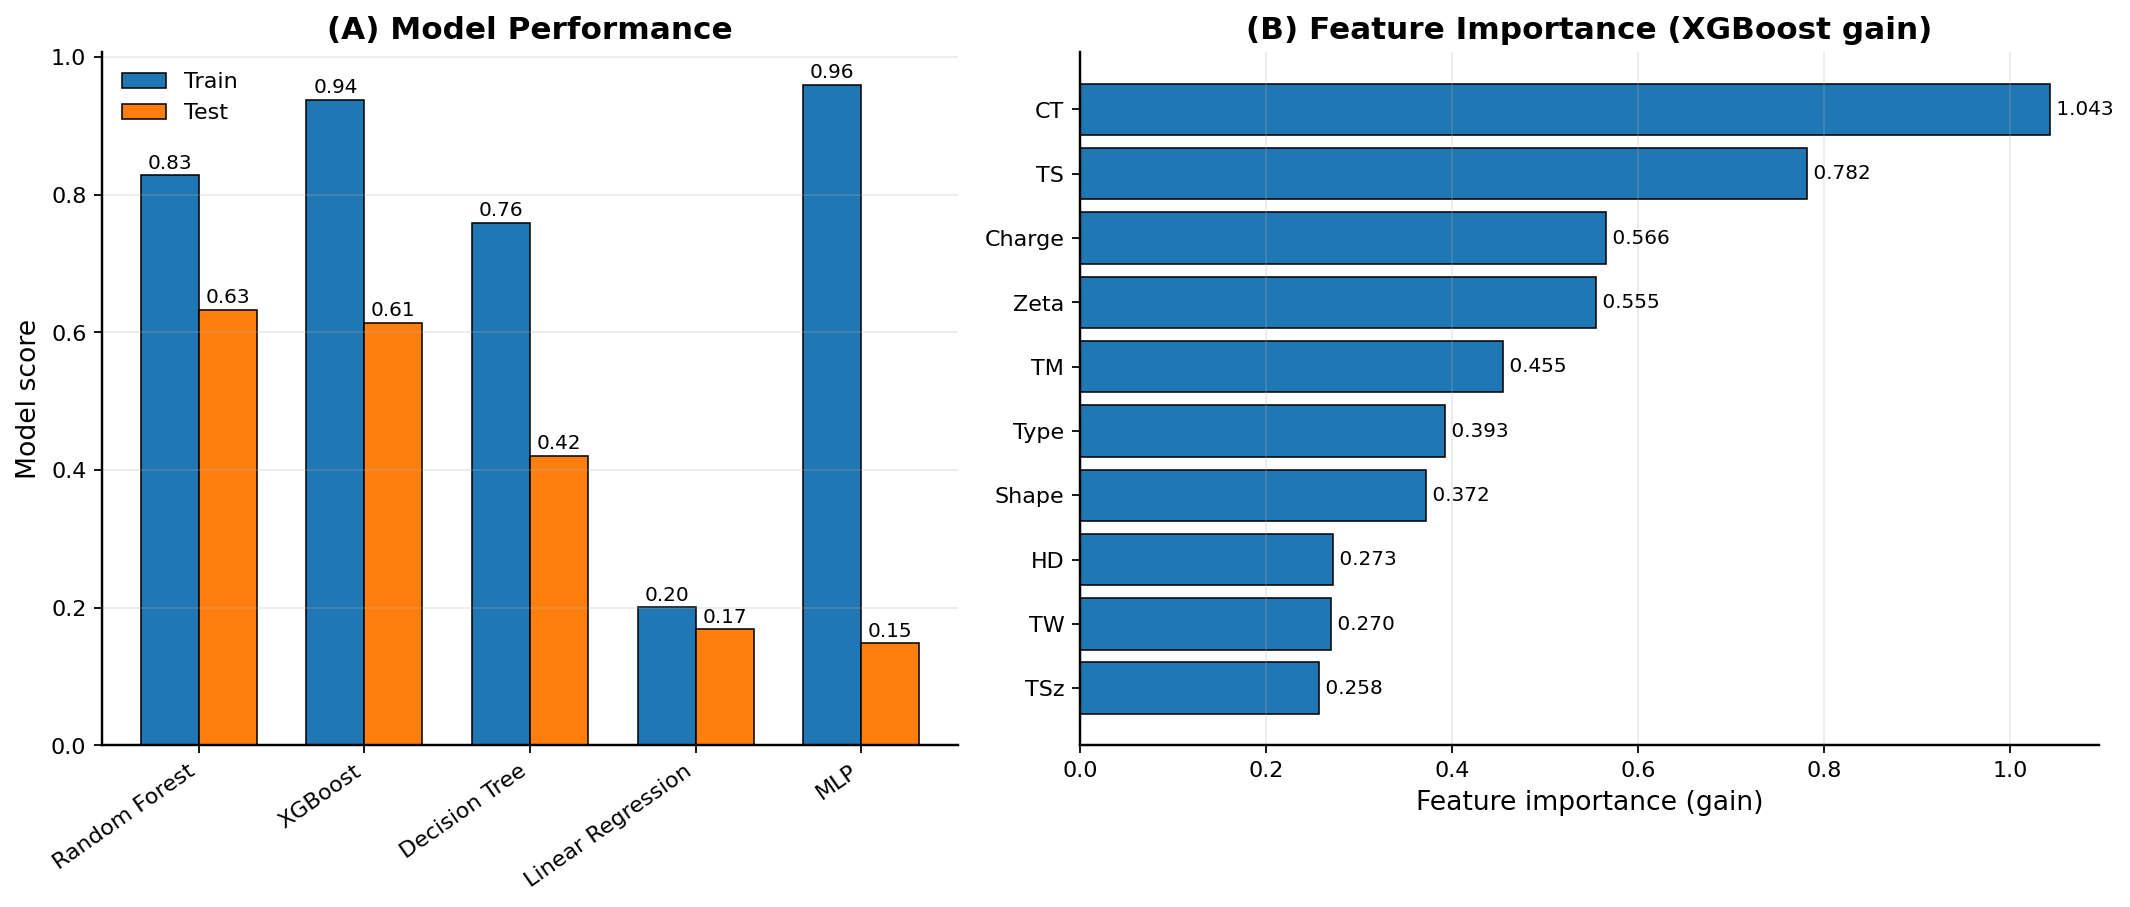

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================================================
# CHOOSE THE CORRECTLY MATCHED STANDARDIZED VARIABLES
# =========================================================
X_tr_eval = X_train_std
Y_tr_eval = Y_train_std
X_te_eval = X_test_std
Y_te_eval = Y_test_std

# =========================================================
# MODEL SCORES
# =========================================================
models = {
    "Linear Regression": linearbag,
    "Decision Tree": treebag,
    "Random Forest": forestbag,
    "XGBoost": xgbbag,
    "MLP": MLPbag,
}

score_rows = []

for name, model in models.items():
    train_score = model.score(X_tr_eval, Y_tr_eval)
    test_score = model.score(X_te_eval, Y_te_eval)

    score_rows.append({
        "Model": name,
        "Train Score": train_score,
        "Test Score": test_score,
    })

score_df = pd.DataFrame(score_rows).sort_values("Test Score", ascending=False)

print("Model performance summary:")
print(score_df.to_string(index=False))

# =========================================================
# FEATURE IMPORTANCE (XGB-BAG AVERAGED — YOUR METHOD)
# =========================================================
fi = ((pd.Series(xgb_grid.best_estimator_.get_booster().get_score(importance_type="gain")).reindex(X_tr_eval.columns).fillna(0.0).values))

feature_names = np.array(X_tr_eval.columns)

fi_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": fi
}).sort_values("Importance", ascending=False)

print("\nXGB-bag feature importance:")
print(fi_df.to_string(index=False))

# top features for plotting
k = 12
top_imp = fi_df.head(k).sort_values("Importance", ascending=True)

# =========================================================
# PUBLICATION STYLE
# =========================================================
plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "axes.linewidth": 1.1,
    "pdf.fonttype": 42,
})

# =========================================================
# LEFT–RIGHT FIGURE
# =========================================================
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(13.5, 5.8),
    gridspec_kw={"width_ratios": [1.05, 1.25]}
)

# ---------------- LEFT: MODEL PERFORMANCE ----------------
x = np.arange(len(score_df))
bar_width = 0.35

ax1.bar(
    x - bar_width/2,
    score_df["Train Score"],
    width=bar_width,
    label="Train",
    edgecolor="black",
    linewidth=0.7
)

ax1.bar(
    x + bar_width/2,
    score_df["Test Score"],
    width=bar_width,
    label="Test",
    edgecolor="black",
    linewidth=0.7
)

ax1.set_xticks(x)
ax1.set_xticklabels(score_df["Model"], rotation=35, ha="right")
ax1.set_ylabel("Model score")
ax1.set_title("(A) Model Performance")

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.grid(axis="y", alpha=0.25)

ax1.legend(frameon=False)

# annotate values
for i, row in score_df.reset_index(drop=True).iterrows():
    ax1.text(i - bar_width/2, row["Train Score"] + 0.01, f"{row['Train Score']:.2f}", ha="center", fontsize=9)
    ax1.text(i + bar_width/2, row["Test Score"] + 0.01, f"{row['Test Score']:.2f}", ha="center", fontsize=9)

# ---------------- RIGHT: XGB-BAG FEATURE IMPORTANCE ----------------
ax2.barh(
    top_imp["Feature"],
    top_imp["Importance"],
    edgecolor="black",
    linewidth=0.7
)

ax2.set_xlabel("Feature importance (gain)")
ax2.set_title("(B) Feature Importance (XGBoost gain)")

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.grid(axis="x", alpha=0.25)

# annotate values
for i, v in enumerate(top_imp["Importance"]):
    ax2.text(v, i, f" {v:.3f}", va="center", fontsize=9)

# =========================================================
# FINALIZE
# =========================================================
plt.tight_layout()

plt.savefig("combined_model_performance_XGBbag_importance.png", bbox_inches="tight")
plt.savefig("combined_model_performance_XGBbag_importance.pdf", bbox_inches="tight")

plt.show()

In [ ]:
y_pred

array([0.8253043 , 0.99590844, 1.06758   , 1.679455  , 0.5258001 ,
       1.1785948 , 1.1785948 , 0.7469185 , 1.2260303 , 1.1490757 ,
       1.6255594 , 0.95722306, 0.48845616, 0.7151809 , 0.28541142,
       1.6800203 , 1.1384668 , 1.595503  , 0.60434043, 1.159247  ,
       1.1239151 , 0.643421  , 1.072252  , 1.141452  , 0.54763675,
       1.2002567 , 1.2137746 , 0.5151963 , 1.0052202 , 0.9018189 ,
       1.1738869 , 1.1041439 , 0.5925535 , 1.1041439 , 0.5258001 ,
       1.1039001 , 0.5335492 , 1.1738869 , 1.7174858 , 0.7502623 ,
       0.6747261 , 1.136703  , 0.99590844, 1.25969   , 1.6800203 ,
       1.6800203 , 1.0681452 , 1.6630251 , 1.1041439 , 1.2005209 ,
       1.6221148 , 1.7130026 , 1.1041439 , 1.7627952 , 0.97446644,
       1.2005209 , 0.7151809 , 1.6533496 ], dtype=float32)

In [ ]:
import numpy as np, pandas as pd
# --- ROBUST INVERSE-TRANSFORM FIX ------------------------------------------
# Recompute the XGBoost prediction here instead of relying on a stale global
# `y_pred`. The multi-target MAIN LOOP overwrites `y_pred` with values that are
# ALREADY on the original DEmax scale; inverse-transforming those a SECOND time
# distorts them and makes R² strongly negative (e.g. -14). `xgbbag` was trained
# on standardized X/Y, so predict() is in standardized space and must be
# inverse-transformed exactly once.
y_pred = xgbbag.predict(X_test)        # standardized XGBoost predictions

y_train_unstd = y_scaler.inverse_transform(np.asarray(Y_train).reshape(-1, 1)).ravel()
y_test_unstd  = y_scaler.inverse_transform(np.asarray(Y_test ).reshape(-1, 1)).ravel()
y_pred_unstd  = y_scaler.inverse_transform(np.asarray(y_pred ).reshape(-1, 1)).ravel()


In [ ]:
X_train_unstd = pd.DataFrame(
    X_scaler.inverse_transform(X_train),
    columns=X_train.columns, index=X_train.index
)
X_test_unstd = pd.DataFrame(
    X_scaler.inverse_transform(X_test),
    columns=X_test.columns, index=X_test.index
)

In [ ]:
import numpy as np, pandas as pd

X = X_test_unstd #if 'Rhatmax_unstd' in globals() else X_test
y_true = pd.Series(np.asarray(y_test_unstd).ravel(), index=X.index, name='Rhatmax_true')   # from y_test_unstd
y_pred = pd.Series(np.asarray(y_pred_unstd).ravel(), index=X.index, name='Rhatmax_pred')

with pd.ExcelWriter('Rhatmax_export.xlsx') as w:
    X.assign(Rhatmax_true=y_true, Rhatmax_pred=y_pred).to_excel(w, 'combined', index=False)
    X.to_excel(w, 'Rhatmax_unstd', index=False)
    pd.concat([y_true, y_pred], axis=1).to_excel(w, 'Rhatmax', index=False)  ###df["Demax"].div(df["KTRESrelease"]


In [ ]:
y_pred_unstd

array([10.565679 , 11.744733 , 12.240059 , 16.46876  ,  8.49579  ,
       13.007289 , 13.007289 , 10.023951 , 13.335118 , 12.803281 ,
       16.096285 , 11.477376 ,  8.237703 ,  9.804609 ,  6.8344502,
       16.472666 , 12.729961 , 15.888563 ,  9.038586 , 12.873575 ,
       12.629394 ,  9.308673 , 12.272347 , 12.750592 ,  8.646704 ,
       13.156995 , 13.250418 ,  8.422506 , 11.809087 , 11.094475 ,
       12.974751 , 12.492754 ,  8.957126 , 12.492754 ,  8.49579  ,
       12.491069 ,  8.549343 , 12.974751 , 16.731592 , 10.047059 ,
        9.525024 , 12.717772 , 11.744733 , 13.567742 , 16.472666 ,
       16.472666 , 12.243965 , 16.355211 , 12.492754 , 13.158821 ,
       16.072477 , 16.70061  , 12.492754 , 17.04473  , 11.596546 ,
       13.158821 ,  9.804609 , 16.288343 ], dtype=float32)

Text(0, 0.5, 'DEmax prediction')

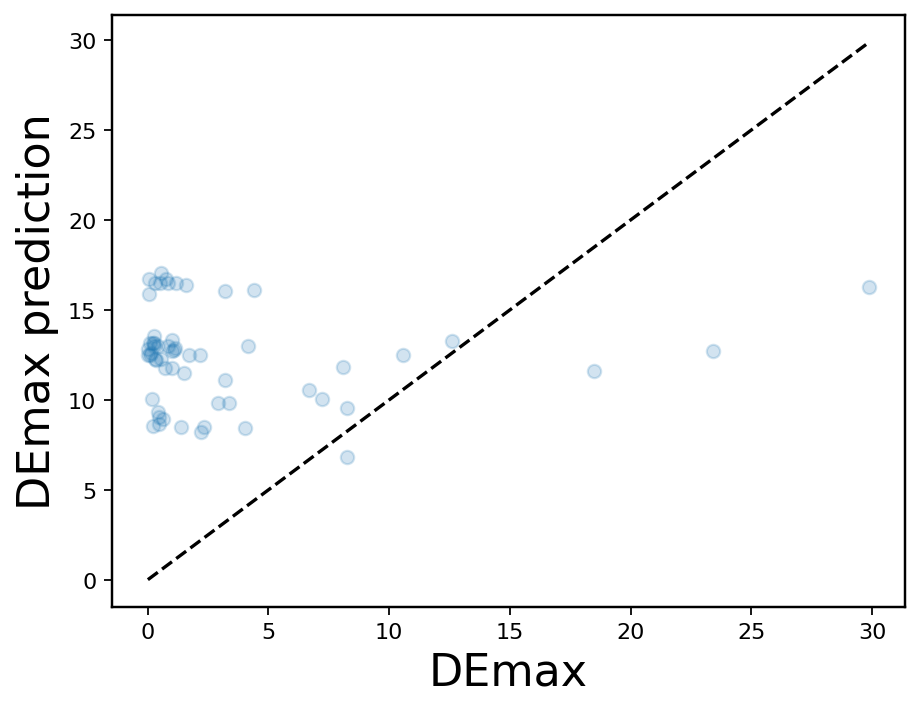

In [ ]:
plt.scatter(y_test_unstd, y_pred_unstd,alpha=0.2,cmap='viridis')
plt.plot([y_test_unstd.min(), y_test_unstd.max()], [y_test_unstd.min(), y_test_unstd.max()], '--k')
#plt.xlabel('Actual KTRES50', fontsize = 20)
#plt.ylabel('KTRES50 prediction', fontsize = 20)
plt.xlabel('DEmax', fontsize = 20)
plt.ylabel('DEmax prediction', fontsize = 20)

In [ ]:
print("R² =", round(r2_score(y_test_unstd, y_pred_unstd), 3))

R² = -2.801


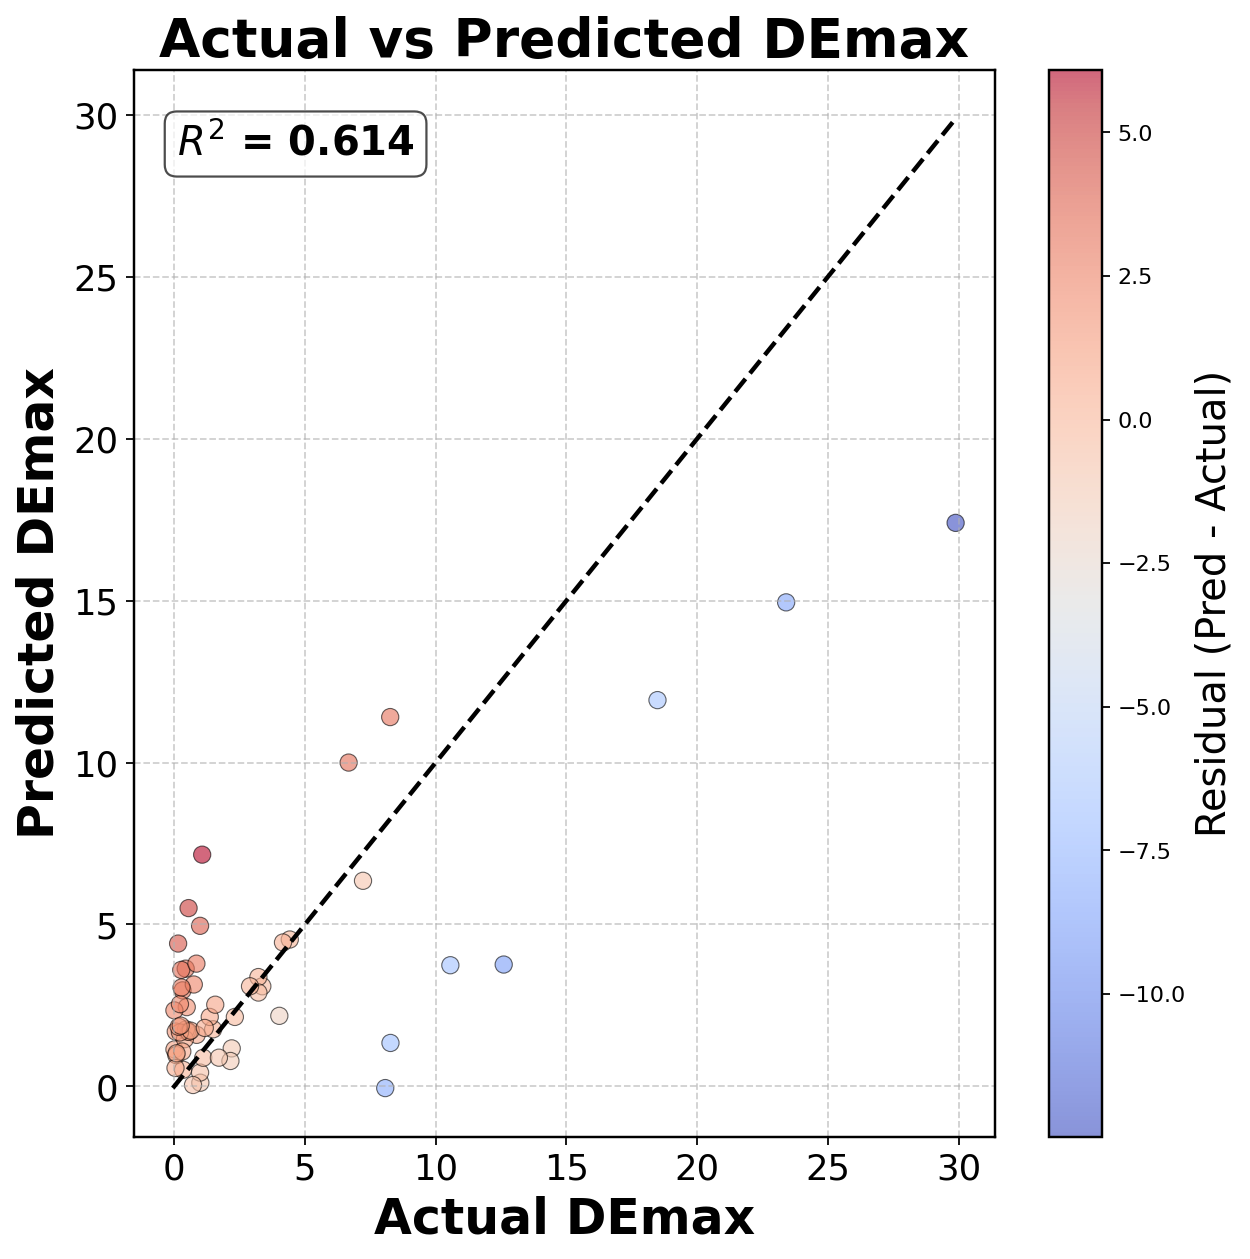

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import r2_score

# --- SELF-CONTAINED: recompute the XGBoost prediction and inverse-transform
# ONCE here, so this plot never depends on a stale global y_pred/y_pred_unstd.
# (The multi-target loop leaves y_pred on the ORIGINAL scale; inverse-transforming
# it again gives a negative R².) xgbbag was trained on standardized X/Y.
y_pred = xgbbag.predict(X_test_std)
y_test_unstd = y_scaler.inverse_transform(np.asarray(Y_test_std).reshape(-1, 1)).ravel()
y_pred_unstd = y_scaler.inverse_transform(np.asarray(y_pred).reshape(-1, 1)).ravel()

# residuals for coloring
residuals = y_pred_unstd - y_test_unstd

plt.figure(figsize=(8, 8))
sc = plt.scatter(y_test_unstd, y_pred_unstd,
                 c=residuals, cmap='coolwarm',
                 alpha=0.6, s=60, edgecolor='k', linewidth=0.5)

# identity line
lims = [min(y_test_unstd.min(), y_pred_unstd.min()),
        max(y_test_unstd.max(), y_pred_unstd.max())]
plt.plot(lims, lims, '--', color='black', lw=2)

# labels
plt.xlabel('Actual DEmax', fontsize=22, fontweight='bold')
plt.ylabel('Predicted DEmax', fontsize=22, fontweight='bold')
plt.title('Actual vs Predicted DEmax', fontsize=24, fontweight='bold')

# add colorbar
cbar = plt.colorbar(sc)
cbar.set_label("Residual (Pred - Actual)", fontsize=18)

# grid & ticks
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(fontsize=16); plt.yticks(fontsize=16)

# add R²
r2 = r2_score(y_test_unstd, y_pred_unstd)
plt.text(0.05, 0.95, f"$R^2$ = {r2:.3f}",
         transform=plt.gca().transAxes,
         fontsize=18, fontweight='bold',
         verticalalignment='top', bbox=dict(boxstyle="round", fc="white", ec="black", alpha=0.7))

plt.tight_layout()
plt.show()


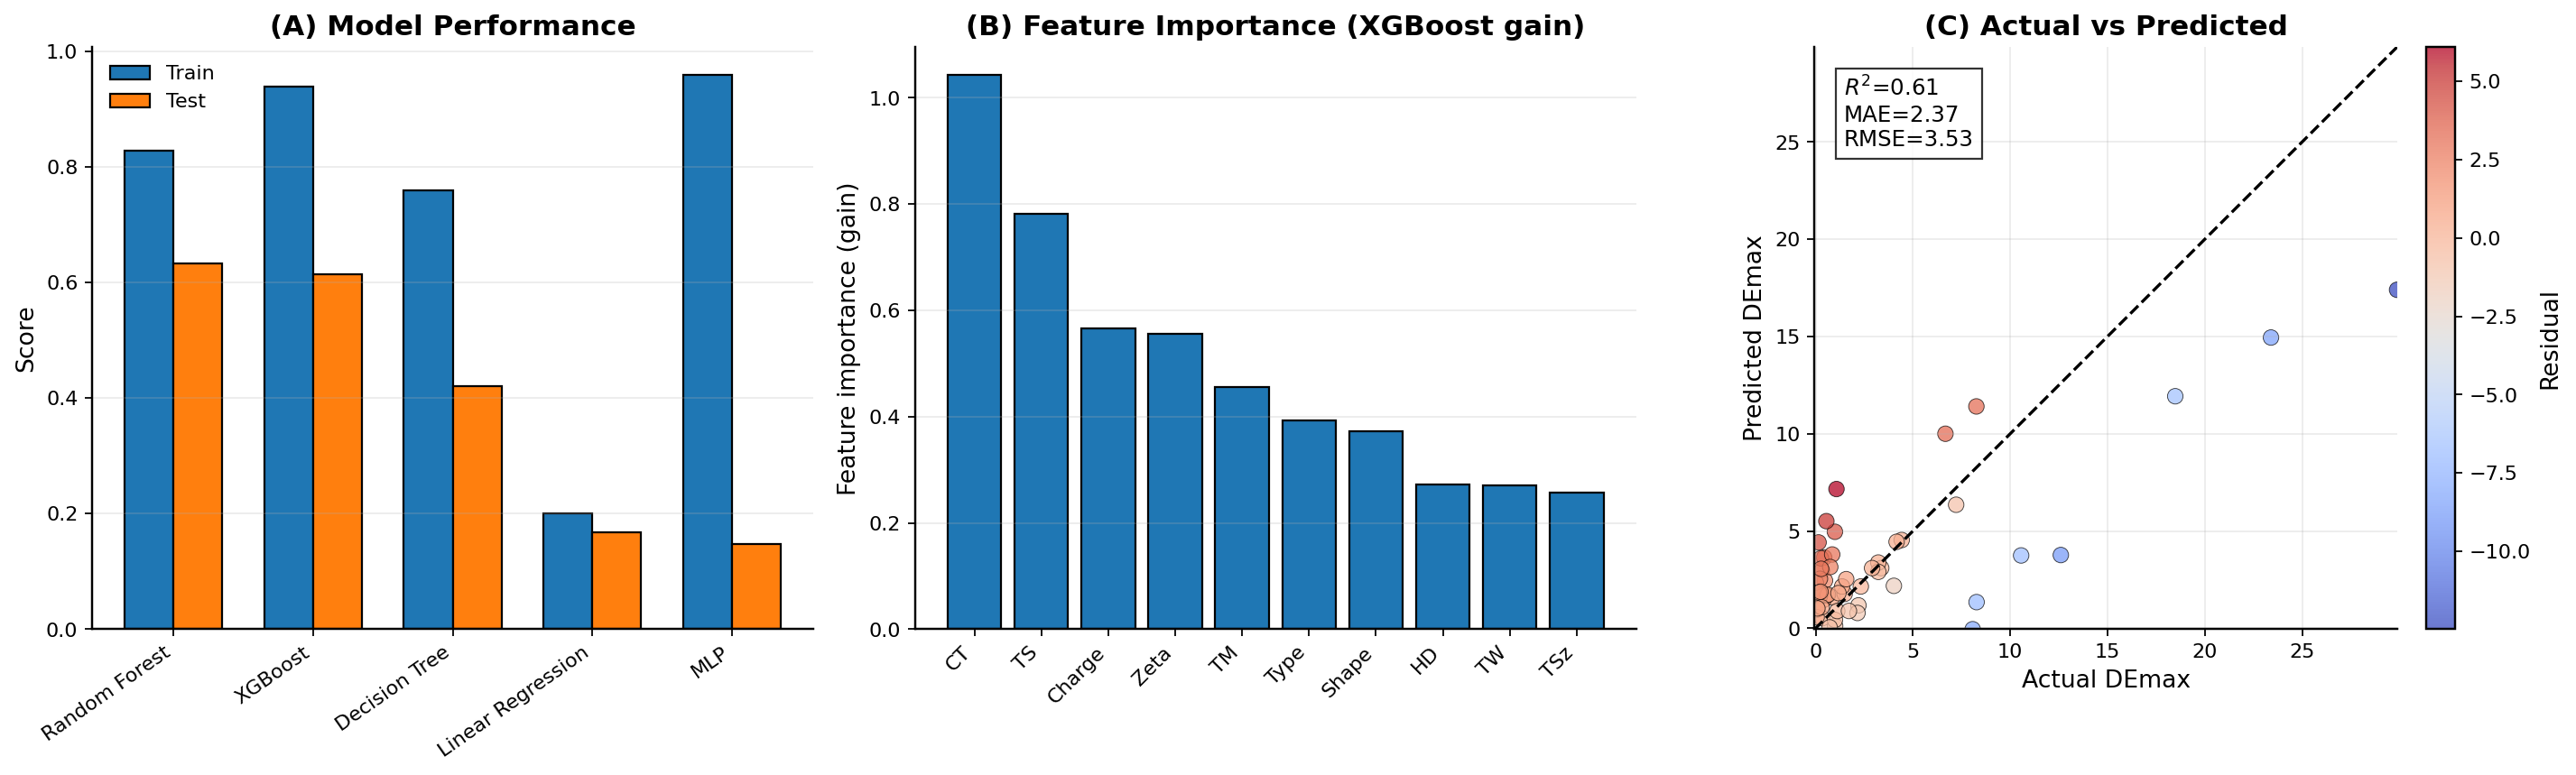

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# =========================================================
# MODEL PERFORMANCE — USE THE MATCHED STANDARDIZED VARIABLES
# =========================================================
X_tr_eval = X_train_std
Y_tr_eval = Y_train_std
X_te_eval = X_test_std
Y_te_eval = Y_test_std

models = {
    "Linear Regression": linearbag,
    "Decision Tree": treebag,
    "Random Forest": forestbag,
    "XGBoost": xgbbag,
    "MLP": MLPbag,
}

score_rows = []
for name, model in models.items():
    score_rows.append({
        "Model": name,
        "Train": model.score(X_tr_eval, Y_tr_eval),
        "Test": model.score(X_te_eval, Y_te_eval)
    })

score_df = pd.DataFrame(score_rows).sort_values("Test", ascending=False)

# =========================================================
# FEATURE IMPORTANCE (XGB-BAG YOUR METHOD)
# =========================================================
fi = ((pd.Series(xgb_grid.best_estimator_.get_booster().get_score(importance_type="gain")).reindex(X_tr_eval.columns).fillna(0.0).values))

fi_df = pd.DataFrame({
    "Feature": X_tr_eval.columns,
    "Importance": fi
}).sort_values("Importance", ascending=False)

top_imp = fi_df.head(10)

# =========================================================
# SCATTER DATA
# =========================================================
actual = np.asarray(y_test_unstd).ravel()
predicted = np.asarray(y_pred_unstd).ravel()
residuals = predicted - actual

r2 = r2_score(actual, predicted)
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

lims = [
    min(actual.min(), predicted.min()),
    max(actual.max(), predicted.max())
]

# =========================================================
# STYLE
# =========================================================
plt.rcParams.update({
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 1.1,
    "pdf.fonttype": 42,
})

# =========================================================
# FIGURE (3 PANELS)
# =========================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# =========================================================
# (A) MODEL PERFORMANCE
# =========================================================
ax1 = axes[0]
x = np.arange(len(score_df))
w = 0.35

ax1.bar(x - w/2, score_df["Train"], width=w, label="Train", edgecolor="black")
ax1.bar(x + w/2, score_df["Test"],  width=w, label="Test",  edgecolor="black")

ax1.set_xticks(x)
ax1.set_xticklabels(score_df["Model"], rotation=35, ha="right")
ax1.set_title("(A) Model Performance")
ax1.set_ylabel("Score")
ax1.legend(frameon=False)

ax1.grid(axis="y", alpha=0.25)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

# =========================================================
# (B) FEATURE IMPORTANCE
# =========================================================
ax2 = axes[1]

ax2.bar(
    np.arange(len(top_imp)),
    top_imp["Importance"],
    edgecolor="black"
)

ax2.set_xticks(np.arange(len(top_imp)))
ax2.set_xticklabels(top_imp["Feature"], rotation=45, ha="right")
ax2.set_title("(B) Feature Importance (XGBoost gain)")
ax2.set_ylabel("Feature importance (gain)")

ax2.grid(axis="y", alpha=0.25)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

# =========================================================
# (C) ACTUAL VS PREDICTED
# =========================================================
ax3 = axes[2]

sc = ax3.scatter(
    actual,
    predicted,
    c=residuals,
    cmap="coolwarm",
    s=60,
    alpha=0.75,
    edgecolor="black",
    linewidth=0.4
)

ax3.plot(lims, lims, "--", color="black")

ax3.set_xlim(lims)
ax3.set_ylim(lims)
ax3.set_aspect("equal", adjustable="box")

ax3.set_title("(C) Actual vs Predicted")
ax3.set_xlabel("Actual DEmax")
ax3.set_ylabel("Predicted DEmax")

# metrics box
ax3.text(
    0.05, 0.95,
    f"$R^2$={r2:.2f}\nMAE={mae:.2f}\nRMSE={rmse:.2f}",
    transform=ax3.transAxes,
    va="top",
    bbox=dict(facecolor="white", edgecolor="black", alpha=0.8)
)

ax3.grid(alpha=0.25)
ax3.spines["top"].set_visible(False)
ax3.spines["right"].set_visible(False)

# colorbar
cbar = fig.colorbar(sc, ax=ax3, fraction=0.046, pad=0.04)
cbar.set_label("Residual")

# =========================================================
# FINALIZE
# =========================================================
plt.tight_layout()

plt.savefig("combined_3panel_model_analysis.png", bbox_inches="tight")
plt.savefig("combined_3panel_model_analysis.pdf", bbox_inches="tight")

plt.show()

In [ ]:
import requests, pandas as pd, numpy as np

HEADERS = {"accept": "application/json"}

def _first(*vals):
    for v in vals:
        if v is None:
            continue
        if isinstance(v, str) and v.strip() == "":
            continue
        if isinstance(v, float) and np.isnan(v):
            continue
        return v
    return None

def _iter_conditions(raw):
    """
    Yield (name, value, unit) triples from many shapes:
    - dict: {name: {value,unit}|value}
    - list of dicts: [{'name':..., 'value':..., 'unit':...}, ...]
    - list of strings: ["dose: 10 ug/mL", ...]
    - string: "dose: 10 ug/mL"
    - None
    """
    if raw is None:
        return
    if isinstance(raw, dict):
        for k, v in raw.items():
            name = str(k).strip().lower().replace(" ", "_")
            unit = None
            if isinstance(v, dict):
                val  = _first(v.get("value"), v.get("loValue"), v.get("textValue"), v.get("nominalValue"))
                unit = v.get("unit")
            else:
                val = v
            yield name, val, unit
        return
    if isinstance(raw, (list, tuple)):
        for c in raw:
            if isinstance(c, dict):
                name = str(_first(c.get("name"), "cond")).strip().lower().replace(" ", "_")
                val  = _first(c.get("value"), c.get("loValue"), c.get("textValue"), c.get("nominalValue"))
                unit = c.get("unit")
                yield name, val, unit
            else:
                # bare string
                s = str(c)
                if ":" in s:
                    k, v = s.split(":", 1)
                    yield k.strip().lower().replace(" ", "_"), v.strip(), None
                else:
                    yield "cond", s.strip(), None
        return
    if isinstance(raw, str):
        s = raw
        if ":" in s:
            k, v = s.split(":", 1)
            yield k.strip().lower().replace(" ", "_"), v.strip(), None
        else:
            yield "cond", s.strip(), None

def extract_effects_robust(study_json):
    """
    Flatten AMBIT study → effects → conditions into a tidy DataFrame.
    Handles study_json being dict({'study':[...]}), list([...]), or other oddities.
    """
    # --- normalize top level to a list of studies ---
    if isinstance(study_json, dict):
        studies = study_json.get("study", [])
        if isinstance(studies, dict):
            # rare: single study as dict
            studies = [studies]
        elif not isinstance(studies, list):
            studies = []
    elif isinstance(study_json, list):
        # sometimes the endpoint returns a list of study objects directly
        studies = study_json
    else:
        studies = []

    rows = []
    for s in studies:
        if not isinstance(s, dict):
            # skip weird items
            continue

        prot = s.get("protocol") or {}
        if not isinstance(prot, dict):
            prot = {}
        cat  = (prot.get("category") or {}).get("code") if isinstance(prot.get("category"), dict) else prot.get("category")
        top  = (prot.get("topcategory") or {}).get("code") if isinstance(prot.get("topcategory"), dict) else prot.get("topcategory")
        owner = s.get("ownerName") or s.get("companyName")

        effects = s.get("effects") or []
        if isinstance(effects, dict):
            # rare case: a dict with a nested list
            # try common keys:
            effects = effects.get("effect") or effects.get("effects") or []
        if not isinstance(effects, list):
            # nothing usable
            continue

        # material descriptors may appear on study or effect level
        mat_s = s.get("material") or {}
        if not isinstance(mat_s, dict): mat_s = {}

        for e in effects:
            if not isinstance(e, dict):
                # skip malformed effect entries
                continue

            endpoint = _first(
                e.get("endpoint"), e.get("endpointcategory"),
                cat, top
            )

            res = e.get("result")
            # result may be a dict, list-of-dicts, string, or None
            if isinstance(res, list) and res:
                res = res[0]
            if not isinstance(res, dict):
                res = {}
            val  = _first(res.get("value"), res.get("loValue"), res.get("textValue"), res.get("nominalValue"))
            unit = res.get("unit")

            # conditions (robust)
            conds = {}
            for name, v, u in _iter_conditions(e.get("conditions")):
                key = str(name)
                conds[key] = v
                if u:
                    conds[f"{key}_unit"] = u

            mat_e = e.get("material") or {}
            if not isinstance(mat_e, dict): mat_e = {}
            core    = _first(mat_e.get("core"),    mat_s.get("core"))
            coating = _first(mat_e.get("coating"), mat_s.get("coating"))
            shape   = _first(mat_e.get("shape"),   mat_s.get("shape"))

            row = {
                "endpoint": endpoint,
                "value": val, "unit": unit,
                "protocol_category": cat, "topcategory": top,
                "owner": owner,
                "core": core, "coating": coating, "shape": shape
            }
            row.update(conds)
            rows.append(row)

    df = pd.DataFrame(rows)

    # Coerce obvious numerics (best-effort)
    if not df.empty:
        for c in df.columns:
            cl = c.lower()
            if any(tok in cl for tok in ["time", "hour", "dose", "conc", "size", "zeta", "serum", "percent", "value"]):
                df[c] = pd.to_numeric(df[c], errors="ignore")

    return df


GROUP SIZE DIAGNOSTICS
Total rows: 288
Total distinct groups (TM x CT): 32
Rows per group:
Allograft Heterotopic_Liver       48
Allograft Heterotopic_Breast      39
Xenograft Heterotopic_Breast      26
Allograft Heterotopic_Colon       21
Xenograft Heterotopic_Cervix      19
Xenograft Heterotopic_Lung        16
Xenograft Heterotopic_Liver        9
Allograft Orthotopic_Skin          9
Xenograft Orthotopic_skin          8
Allograft Heterotopic_breast       8
Xenograft Heterotopic_Pancreas     8
Allograft Orthotopic_Breast        8
Xenograft Orthotopic_Skin          8
Xenograft Heterotopic_Brain        7
Allograft Orthotopic_Other         7
Xenograft Orthotopic_Breast        6
Xenograft Orthotopic_Brain         4
Xenograft Orthotopic_Ovary         4
Xenograft Heterotopic_prostate     4
Xenograft Heterotopic_Ovary        4
Xenograft Heterotopic_Prostate     4
Xenograft Heterotopic_brain        4
Xenograft Heterotopic_Other        3
Xenograft Heterotopic_Kidney       3
Xenograft Heterotopic

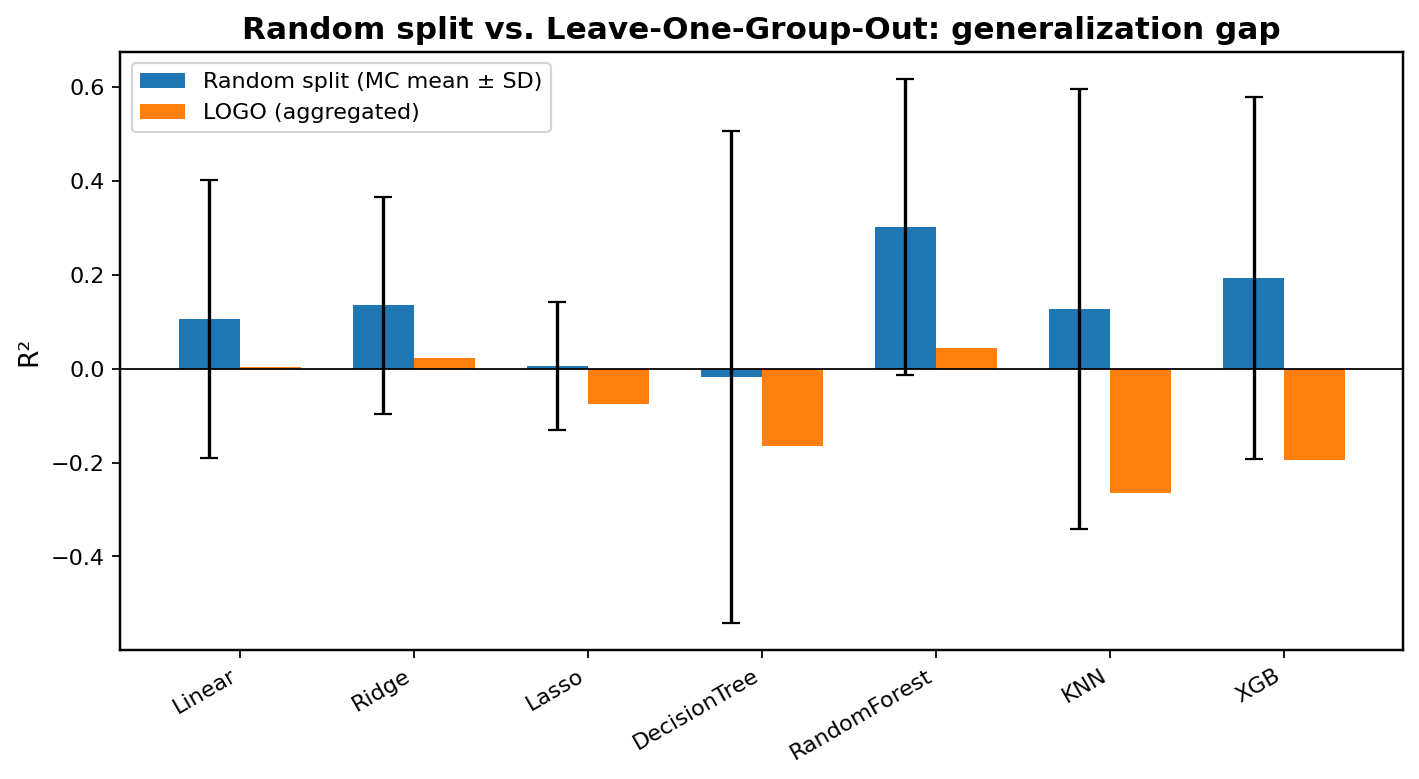

In [ ]:
# =============================================================================
# AI_nano_PBPK — LEAVE-ONE-GROUP-OUT (LOGO) VERSION
# =============================================================================
# Use this when the dataset is too small for GroupKFold(n_splits=5) to be
# stable (too few groups per fold -> noisy/unstable CV scores).
#
# LeaveOneGroupOut (LOGO) holds out ONE group (e.g., one TM+CT combination)
# at a time as the test fold, trains on everything else, and repeats until
# every group has been the test fold exactly once. This uses ALL your data
# across folds (no wasted 20% held out permanently) while still respecting
# group boundaries -- no group ever appears in both train and test within
# a fold.
#
# IMPORTANT: run the DIAGNOSTICS section first and actually look at the
# printed group sizes before trusting any LOGO score. If most groups have
# only 1 row, LOGO CV degenerates into "predict this single held-out point
# from everything else" repeated N times -- technically leak-free, but the
# per-fold scores (especially R^2 on a single point) will be extremely
# noisy and not very informative on their own. In that case, look at the
# printed distribution and consider the recommendations at the bottom.
# =============================================================================

import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import (
    LeaveOneGroupOut,
    GroupShuffleSplit,
    cross_val_score,
    cross_val_predict,
    GridSearchCV,
    train_test_split as plain_train_test_split,
)
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, BaggingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
pd.options.display.max_columns = None
pd.options.display.max_rows = None

# =============================================================================
# 1. LOAD + CLEAN DATA (same as before)
# =============================================================================
df = pd.read_excel(f"{DATA_DIR}/AI_nano.xlsx")
df = df.dropna().reset_index(drop=True)

df["HD_log"] = np.where(df["HD"] > 0, np.log(df["HD"]), np.nan)
df["HD"] = df["HD_log"]
df.drop(columns=["HD_log"], inplace=True)

y = df["Demax"]  # swap target as needed
X = df[["Type", "TS", "HD", "Zeta", "Charge", "Shape", "TM", "CT", "TSz", "TW"]].copy()

groups = (df["TM"].astype(str) + "_" + df["CT"].astype(str)).reset_index(drop=True)

# =============================================================================
# 2. DIAGNOSTICS -- look at this BEFORE trusting any LOGO result
# =============================================================================
group_sizes = groups.value_counts()
print("=" * 60)
print("GROUP SIZE DIAGNOSTICS")
print("=" * 60)
print(f"Total rows: {len(df)}")
print(f"Total distinct groups (TM x CT): {groups.nunique()}")
print(f"Rows per group:\n{group_sizes}")
print(f"\nGroups with only 1 row: {(group_sizes == 1).sum()} "
      f"({(group_sizes == 1).sum() / groups.nunique():.0%} of groups)")
print(f"Median rows/group: {group_sizes.median()}, "
      f"mean rows/group: {group_sizes.mean():.1f}")
print("=" * 60)

if (group_sizes == 1).mean() > 0.5:
    print(
        "\n[WARNING] Over half your groups have exactly 1 row.\n"
        "LOGO CV will effectively be 'predict this single unseen point from\n"
        "everything else' for most folds. Fold-level R^2 is undefined/meaningless\n"
        "for a single test point (R^2 needs variance to divide by) -- MAE/error\n"
        "for that single point is still valid, but you should aggregate errors\n"
        "across ALL held-out predictions rather than averaging per-fold R^2.\n"
        "See the aggregated-prediction approach in section 4 below.\n"
    )

# =============================================================================
# 3. ENCODE FEATURES
# =============================================================================
label_mappings = {}
text_cols = X.select_dtypes(include=["object", "category"]).columns
le = LabelEncoder()
for col in text_cols:
    X[col] = le.fit_transform(X[col].astype(str))
    label_mappings[col] = dict(zip(le.classes_, le.transform(le.classes_)))

X = pd.DataFrame(X)
Y = y.reset_index(drop=True)

logo = LeaveOneGroupOut()
n_folds = groups.nunique()
print(f"LOGO will run {n_folds} folds (one per distinct group).")

# =============================================================================
# 4. AGGREGATED OUT-OF-FOLD PREDICTIONS (recommended approach for small N)
# =============================================================================
# Instead of averaging per-fold R^2 (unstable when folds have 1-2 points),
# collect every out-of-fold prediction across all LOGO folds, then compute
# ONE overall MAE/RMSE/R^2 on the full set of held-out predictions. This is
# the standard, more robust way to report LOGO/LOOCV performance.

def logo_oof_predictions(model, X, Y, groups):
    """Return out-of-fold predictions for every row, using LOGO."""
    preds = cross_val_predict(model, X, Y, groups=groups, cv=LeaveOneGroupOut())
    return preds

models = {
    "Linear": LinearRegression(),
    "Ridge": Ridge(alpha=1.0, random_state=4649),
    "Lasso": Lasso(alpha=1.0, random_state=4649),
    "DecisionTree": DecisionTreeRegressor(max_depth=5, max_features=8, random_state=42),
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=42),
    "KNN": Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsRegressor(n_neighbors=3))]),
    "XGB": XGBRegressor(random_state=42, n_estimators=200, max_depth=3),
}

results = {}
for name, model in models.items():
    try:
        oof_pred = logo_oof_predictions(model, X, Y, groups)
        mae = mean_absolute_error(Y, oof_pred)
        rmse = math.sqrt(mean_squared_error(Y, oof_pred))
        r2 = r2_score(Y, oof_pred)
        results[name] = {"MAE": mae, "RMSE": rmse, "R2": r2}
        print(f"{name:15s}  LOGO-aggregated  MAE={mae:.4f}  RMSE={rmse:.4f}  R2={r2:.4f}")
    except Exception as e:
        print(f"{name:15s}  FAILED: {e}")

results_df = pd.DataFrame(results).T
print("\n" + "=" * 60)
print("LOGO SUMMARY (aggregated out-of-fold predictions, all folds pooled)")
print("=" * 60)
print(results_df)

# =============================================================================
# 5. OPTIONAL: hyperparameter tuning nested inside LOGO
# =============================================================================
# If you want to tune hyperparameters AND get a leakage-aware estimate, nest
# GridSearchCV (using GroupKFold or LOGO on the training fold) inside an outer
# LOGO loop. This is more correct but expensive on tiny datasets -- often not
# worth it if you only have a handful of groups. Shown here for RandomForest
# as an example; extend to other models if your group count supports it.

do_nested_tuning = False  # flip to True if you want to try this

if do_nested_tuning:
    outer_logo = LeaveOneGroupOut()
    nested_scores = []
    for train_idx, test_idx in outer_logo.split(X, Y, groups=groups):
        X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
        Y_tr, Y_te = Y.iloc[train_idx], Y.iloc[test_idx]
        groups_tr = groups.iloc[train_idx]

        # inner CV must also respect groups; skip if too few inner groups
        if groups_tr.nunique() < 2:
            continue

        inner_cv = LeaveOneGroupOut()
        param_grid = {"n_estimators": [100, 200, 300], "max_depth": [3, 5, 10]}
        grid = GridSearchCV(
            RandomForestRegressor(random_state=42),
            param_grid,
            cv=list(inner_cv.split(X_tr, Y_tr, groups=groups_tr)),
            n_jobs=-1,
        )
        grid.fit(X_tr, Y_tr)
        pred = grid.predict(X_te)
        nested_scores.append(mean_absolute_error(Y_te, pred))

    print(f"\nNested LOGO MAE (mean across outer folds): {np.mean(nested_scores):.4f}")

# =============================================================================
# 6. MONTE CARLO REPEATED RANDOM SPLIT (apples-to-apples vs. LOGO)
# =============================================================================
# A single 80/20 random split is a noisy estimate -- especially on a dataset
# this size. Repeat it many times with different random seeds, average the
# metrics, and report the spread (std / min-max) alongside the mean. This is
# the fair comparison to the LOGO-aggregated numbers (which are already an
# average over 32 folds).
#
# NOTE: this is a PLAIN random split (ignores groups on purpose) so you can
# see exactly how much the group leakage was inflating performance. It is
# NOT meant to replace the group-aware split from the earlier script -- it's
# here specifically to produce the "optimistic" number for the comparison.

N_REPEATS = 100
TEST_SIZE = 0.20

def _clone_model(model):
    return clone(model)

def monte_carlo_random_split_eval(model, X, Y, n_repeats=N_REPEATS, test_size=TEST_SIZE):
    """Fit/evaluate over many random splits; return per-repeat MAE and R^2."""
    maes, rmses, r2s = [], [], []
    for seed in range(n_repeats):
        X_tr, X_te, Y_tr, Y_te = plain_train_test_split(
            X, Y, test_size=test_size, random_state=seed
        )
        m = _clone_model(model)
        m.fit(X_tr, Y_tr)
        pred = m.predict(X_te)
        maes.append(mean_absolute_error(Y_te, pred))
        rmses.append(math.sqrt(mean_squared_error(Y_te, pred)))
        r2s.append(r2_score(Y_te, pred))
    return np.array(maes), np.array(rmses), np.array(r2s)

mc_rows = []
for name, model in models.items():
    maes, rmses, r2s = monte_carlo_random_split_eval(model, X, Y)
    mc_rows.append({
        "Model": name,
        "RandomSplit MAE (mean)": maes.mean(),
        "RandomSplit MAE (std)": maes.std(),
        "RandomSplit RMSE (mean)": rmses.mean(),
        "RandomSplit R2 (mean)": r2s.mean(),
        "RandomSplit R2 (std)": r2s.std(),
        "LOGO MAE": results.get(name, {}).get("MAE", np.nan),
        "LOGO RMSE": results.get(name, {}).get("RMSE", np.nan),
        "LOGO R2": results.get(name, {}).get("R2", np.nan),
    })
    print(
        f"{name:15s}  RandomSplit(x{N_REPEATS})  "
        f"MAE={maes.mean():.3f}±{maes.std():.3f}  "
        f"R2={r2s.mean():.3f}±{r2s.std():.3f}   |   "
        f"LOGO  MAE={results.get(name, {}).get('MAE', float('nan')):.3f}  "
        f"R2={results.get(name, {}).get('R2', float('nan')):.3f}"
    )

comparison_df = pd.DataFrame(mc_rows)
print("\n" + "=" * 80)
print(f"RANDOM SPLIT (Monte Carlo, {N_REPEATS} repeats) vs. LOGO — apples-to-apples")
print("=" * 80)
pd.options.display.float_format = "{:.3f}".format
print(comparison_df.to_string(index=False))

# The gap column is the headline number for the paper: how much does
# performance drop once group leakage is removed?
comparison_df["R2 gap (Random - LOGO)"] = (
    comparison_df["RandomSplit R2 (mean)"] - comparison_df["LOGO R2"]
)
comparison_df["MAE gap (LOGO - Random)"] = (
    comparison_df["LOGO MAE"] - comparison_df["RandomSplit MAE (mean)"]
)
print("\n" + "=" * 80)
print("GENERALIZATION GAP (this is the number to report/discuss)")
print("=" * 80)
print(comparison_df[["Model", "R2 gap (Random - LOGO)", "MAE gap (LOGO - Random)"]]
      .to_string(index=False))

# =============================================================================
# 7. OPTIONAL: bar chart of Random vs. LOGO R^2, for the manuscript figure
# =============================================================================
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(comparison_df))
width = 0.35
ax.bar(x - width/2, comparison_df["RandomSplit R2 (mean)"], width,
       yerr=comparison_df["RandomSplit R2 (std)"], label="Random split (MC mean ± SD)",
       capsize=4)
ax.bar(x + width/2, comparison_df["LOGO R2"], width, label="LOGO (aggregated)")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(comparison_df["Model"], rotation=30, ha="right")
ax.set_ylabel("R²")
ax.set_title("Random split vs. Leave-One-Group-Out: generalization gap")
ax.legend()
plt.tight_layout()
plt.savefig("random_vs_logo_r2_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

Table S2 — leakage-free re-run of the cross-validation (reviewer check)
Two questions in one table, per target × model:

Was the CV inflated by leakage? Compare CV_infl (augment whole train → then 5-fold = current Table S2 CV) with CV_free (5-fold first → augment only each training fold → score the untouched fold). If CV_infl ≫ CV_free, the leakage is confirmed.
Did augmentation improve generalization, or just inflate the CV? Compare Test_aug (clean hold-out, trained WITH augmentation = current Table S2 Test) with Test_noaug (clean hold-out, trained with NO augmentation). d_aug = Test_aug − Test_noaug: positive ⇒ augmentation helped; ≈0 or negative ⇒ it mainly inflated the CV.
Run after the Table S2 cells so df, prepare_Xy, augment_noise, build_models, FEATURE_COLS, TARGET_COLS, SEED are in memory. Set the KNN in build_models() to k=3, distance-weighted if you want to match the published Table S2 exactly.

In [ ]:
# =============================================================================
# Reviewer check — (A) re-run Table S2's CV without leakage, and
#                   (B) test whether augmentation actually helps generalization.
# Per target x model it prints:
#   CV_infl   : augment whole train, THEN 5-fold   (= current Table S2 CV; leaky)
#   CV_free   : 5-fold FIRST, augment only each train fold, score untouched fold (honest CV)
#   Test_aug  : clean 80/20 hold-out, trained WITH augmentation  (= current Table S2 Test)
#   Test_noaug: clean 80/20 hold-out, trained WITHOUT any augmentation
#   d_aug     : Test_aug - Test_noaug  (>0 => augmentation improved generalization)
#
# Run AFTER the Table S2 cells so these are in memory:
#   df, prepare_Xy, augment_noise, build_models, FEATURE_COLS, TARGET_COLS, SEED
# =============================================================================
import numpy as np, pandas as pd
from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

SEED = globals().get('SEED', 42)
AUG = dict(aug_multiplier=2, noise_frac=0.03, cat_strategy='swap',
           tail='both', low_quantile=0.20, high_quantile=0.80, both_tail_weights=(0.4, 0.8))

def _fit_predict_aug(model, Xtr_raw, ytr_raw, Xeval, seed):
    """Augment ONLY these training rows, scale on them, fit, predict Xeval (original scale)."""
    Xa, ya = augment_noise(Xtr_raw, ytr_raw, random_state=seed, **AUG)
    xs = StandardScaler().fit(Xa); ys = StandardScaler().fit(ya.values.reshape(-1, 1))
    m = clone(model).fit(xs.transform(Xa), ys.transform(ya.values.reshape(-1, 1)).ravel())
    return ys.inverse_transform(m.predict(xs.transform(Xeval)).reshape(-1, 1)).ravel()

def _fit_predict_noaug(model, Xtr_raw, ytr_raw, Xeval):
    """NO augmentation: scale on raw train, fit, predict Xeval (original scale)."""
    xs = StandardScaler().fit(Xtr_raw); ys = StandardScaler().fit(ytr_raw.values.reshape(-1, 1))
    m = clone(model).fit(xs.transform(Xtr_raw), ys.transform(ytr_raw.values.reshape(-1, 1)).ravel())
    return ys.inverse_transform(m.predict(xs.transform(Xeval)).reshape(-1, 1)).ravel()

def inflated_cv(model, X_tr, y_tr, seed=SEED, n_splits=5):
    Xa, ya = augment_noise(X_tr, y_tr, random_state=seed, **AUG)
    xs = StandardScaler().fit(Xa); ys = StandardScaler().fit(ya.values.reshape(-1, 1))
    Xa_s = pd.DataFrame(xs.transform(Xa), columns=X_tr.columns)
    ya_s = ys.transform(ya.values.reshape(-1, 1)).ravel()
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return cross_val_score(clone(model), Xa_s, ya_s, cv=kf, scoring='r2').mean()

def leakage_free_cv(model, X_tr, y_tr, seed=SEED, n_splits=5):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed); sc = []
    for tr, va in kf.split(X_tr):
        pred = _fit_predict_aug(model, X_tr.iloc[tr], y_tr.iloc[tr], X_tr.iloc[va], seed)
        sc.append(r2_score(y_tr.iloc[va].values, pred))
    return float(np.mean(sc))

print(f"{'Target':<9}{'Model':<20}{'CV_infl':>9}{'CV_free':>9}{'Test_aug':>10}{'Test_noaug':>12}{'d_aug':>8}")
print("-" * 77)
rows = []
for target_name, target_col in TARGET_COLS.items():
    X_t, y_t = prepare_Xy(df, target_col, FEATURE_COLS)
    X_tr, X_te, y_tr, y_te = train_test_split(X_t, y_t, test_size=0.2, random_state=SEED)
    for mname, model in build_models().items():
        cv_i = inflated_cv(model, X_tr, y_tr)
        cv_f = leakage_free_cv(model, X_tr, y_tr)
        t_a  = r2_score(y_te.values, _fit_predict_aug(model, X_tr, y_tr, X_te, SEED))
        t_n  = r2_score(y_te.values, _fit_predict_noaug(model, X_tr, y_tr, X_te))
        rows.append([target_name, mname, cv_i, cv_f, t_a, t_n, t_a - t_n])
        print(f"{target_name:<9}{mname:<20}{cv_i:>9.3f}{cv_f:>9.3f}{t_a:>10.3f}{t_n:>12.3f}{t_a-t_n:>+8.3f}")

res = pd.DataFrame(rows, columns=['Target','Model','CV_infl','CV_free','Test_aug','Test_noaug','d_aug'])
print("\n--- summary (mean over all target x model cells) ---")
print(f"  CV inflated (leaky)        = {res.CV_infl.mean():+.3f}")
print(f"  CV leakage-free            = {res.CV_free.mean():+.3f}")
print(f"  Test WITH augmentation     = {res.Test_aug.mean():+.3f}")
print(f"  Test WITHOUT augmentation  = {res.Test_noaug.mean():+.3f}")
print(f"  mean augmentation effect   = {res.d_aug.mean():+.3f}  (Test_aug - Test_noaug)")
n_help = int((res.d_aug > 0).sum())
print(f"  augmentation improved test in {n_help}/{len(res)} cells")
print("\nReading: CV_infl >> CV_free confirms the leakage. d_aug > 0 means augmentation")
print("helped generalization; d_aug ~ 0 or < 0 means it mainly inflated the CV.")

Target   Model                 CV_infl  CV_free  Test_aug  Test_noaug   d_aug
-----------------------------------------------------------------------------
KTRES_relLinear Regression       0.014   -0.649    -0.087       0.017  -0.104
KTRES_relRandom Forest           0.577    0.051     0.260       0.253  +0.007
KTRES_relKNN                     0.755   -0.676    -0.025       0.098  -0.123
KTRES_relXGBoost                 0.702    0.057     0.304       0.219  +0.085
KTRES_relMLP                     0.231   -0.394     0.011       0.050  -0.039
KTRES_n  Linear Regression      -0.019   -0.209    -0.720      -0.236  -0.485
KTRES_n  Random Forest           0.440    0.191    -0.113      -0.059  -0.054
KTRES_n  KNN                     0.607   -0.324    -0.709      -0.279  -0.430
KTRES_n  XGBoost                 0.543    0.160    -0.129      -0.088  -0.041
KTRES_n  MLP                     0.106   -0.146    -0.583      -0.168  -0.415
KTRES_maxLinear Regression       0.007   -2.354     0.049       